In [1]:
# Paths and analysis configuration
from pathlib import Path
import os, json, math, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

SEED = 101
STRICT_TOL = 0.50
DATASET_TOL = 0.70
RELAXED_TOL = 1.00
BOOTSTRAP_REPLICATES = 2000

def _find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "configs" / "voxconverse").exists():
            return candidate
    return Path.cwd()

PROJECT_ROOT = Path(os.environ.get("PROJECT_ROOT", _find_project_root())).expanduser().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "voxconverse"
RESULTS_DIR = PROJECT_ROOT / "results" / "voxconverse"

VOX_ROOT = Path(os.environ.get("VOX_ROOT", DATA_DIR)).expanduser().resolve()
RUNS_DIR = Path(os.environ.get("VOX_RUNS_DIR", RESULTS_DIR)).expanduser().resolve()
MAIN_RUN_NAME = "18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2"

RUN_ROOT = Path(
    os.environ.get(
        "VOX_ANALYSIS_RUN_ROOT",
        str(RUNS_DIR / MAIN_RUN_NAME),
    )
).expanduser().resolve()

RTTM_TEST = Path(
    os.environ.get(
        "VOX_RTTM_TEST",
        str(VOX_ROOT / "labels" / "test"),
    )
).expanduser().resolve()

AUDIO_TEST = Path(
    os.environ.get(
        "VOX_AUDIO_TEST",
        str(VOX_ROOT / "voxconverse_test_wav" / "audio"),
    )
).expanduser().resolve()

ANALYSIS_DIR = RUN_ROOT / "paper_analysis_voxconverse"
FIG_DIR = ANALYSIS_DIR / "figures"
TABLE_DIR = ANALYSIS_DIR / "tables"
AUDIT_DIR = ANALYSIS_DIR / "manual_label_audit"
TIMING_DIR = ANALYSIS_DIR / "timing"

for d in [ANALYSIS_DIR, FIG_DIR, TABLE_DIR, AUDIT_DIR, TIMING_DIR]:
    d.mkdir(parents=True, exist_ok=True)

AUGMENTATION_RUNS = {
    "no_aug": RUNS_DIR / f"{MAIN_RUN_NAME}__aug_ablation_no_aug",
    "synthetic_only": RUNS_DIR / f"{MAIN_RUN_NAME}__aug_ablation_synthetic_only",
    "diffusion_only": RUNS_DIR / f"{MAIN_RUN_NAME}__aug_ablation_diffusion_only",
    "full": RUN_ROOT,
}

AUG_CAMPAIGN_RESULT_DIR = Path(
    os.environ.get(
        "VOX_AUG_CAMPAIGN_RESULT_DIR",
        str(RESULTS_DIR / "augmentation_ablation_campaign"),
    )
).expanduser().resolve()

AUG_CAMPAIGN_RESULTS_CSV = (
    AUG_CAMPAIGN_RESULT_DIR / "paper_ready_augmentation_ablation_results.csv"
)
AUG_CAMPAIGN_BOOTSTRAP_CSV = (
    AUG_CAMPAIGN_RESULT_DIR / "augmentation_ablation_paired_bootstrap_summary.csv"
)

RUN_TRUE_TIMING_BENCHMARK = bool(
    str(os.environ.get("VOX_RUN_TRUE_TIMING_BENCHMARK", "1")).strip().lower()
    not in {"0", "false", "no", "off"}
)
TIMING_N_SYS1_SESSIONS = int(os.environ.get("VOX_TIMING_N_SYS1_SESSIONS", 3))
TIMING_SYS1_AUDIO_S_PER_SESSION = float(
    os.environ.get("VOX_TIMING_SYS1_AUDIO_S_PER_SESSION", 60.0)
)
TIMING_SYS1_BATCH_SIZE = int(os.environ.get("VOX_TIMING_SYS1_BATCH_SIZE", 8))
TIMING_SYS2_MAX_ROWS = int(os.environ.get("VOX_TIMING_SYS2_MAX_ROWS", 20000))
TIMING_SYS2_BATCH_SIZE = int(os.environ.get("VOX_TIMING_SYS2_BATCH_SIZE", 128))
TIMING_REPEATS = int(os.environ.get("VOX_TIMING_REPEATS", 3))

EXPORT_AUDIO_SNIPPETS = bool(
    str(os.environ.get("VOX_EXPORT_AUDIT_AUDIO", "1")).strip().lower()
    not in {"0", "false", "no", "off"}
)
MANUAL_AUDIT_TOTAL = int(os.environ.get("VOX_MANUAL_AUDIT_TOTAL", 300))
SNIPPET_BEFORE_S = float(os.environ.get("VOX_AUDIT_SNIPPET_BEFORE_S", 3.0))
SNIPPET_AFTER_S = float(os.environ.get("VOX_AUDIT_SNIPPET_AFTER_S", 3.0))
AUDIT_REVIEW_PATH = AUDIT_DIR / "manual_event_label_audit_review.csv"
AUDIT_STATUS_PATH = AUDIT_DIR / "manual_event_label_audit_status.json"

SILENCE_BASELINE_THRESHOLD_GRID = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.40, 0.50, 0.60, 0.70, 0.80, 1.00,
]
SILENCE_BASELINE_PRIMARY_TOL = STRICT_TOL
SILENCE_BASELINE_DIR = ANALYSIS_DIR / "silence_only_baseline"
SILENCE_BASELINE_DIR.mkdir(parents=True, exist_ok=True)

STRONG_SILENCE_DIR = ANALYSIS_DIR / "silence_plus_speaker_change_baseline"
STRONG_SILENCE_DIR.mkdir(parents=True, exist_ok=True)

STRONG_SILENCE_MIN_GRID = [
    0.00, 0.05, 0.10, 0.15, 0.20, 0.25,
]
STRONG_SILENCE_MAX_GRID = [
    0.25, 0.50, 0.75, 1.00, 1.50, 2.00, None,
]
STRONG_SILENCE_COOLDOWN_GRID = [
    0.00, 0.25, 0.50, 1.00,
]

EXPECTED_MAIN = {
    "P": 0.5361759025404843,
    "R": 0.5685255198487713,
    "F1": 0.551877054820705,
    "TP": 3609,
    "FP": 3122,
    "FN": 2739,
    "N_pred": 6731,
    "N_gt": 6348,
}

print("VOX_ROOT:", VOX_ROOT)
print("RUN_ROOT:", RUN_ROOT)
print("RTTM_TEST:", RTTM_TEST)
print("ANALYSIS_DIR:", ANALYSIS_DIR)

VOX_ROOT: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset
RUN_ROOT: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2
RTTM_TEST: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/labels/test
ANALYSIS_DIR: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/paper_analysis_voxconverse


In [2]:
CORE_ARTIFACTS = {
    "final predictions": RUN_ROOT / "eval" / "final_test_predictions_used.csv",
    "final strict per-session metrics": RUN_ROOT / "eval" / "final_test_metrics_per_session.csv",
    "final metrics": RUN_ROOT / "eval" / "final_test_metrics.csv",
    "primary TEST events": RUN_ROOT / "cache" / "test_primary_events.pkl",
    "primary VAL events": RUN_ROOT / "cache" / "val_primary_events.pkl",
    "split summary": RUN_ROOT / "split_summary.json",
    "asset provenance": RUN_ROOT / "asset_provenance.json",
    "Branch 2 oracle scores": RUN_ROOT / "branch2_vap_decision_point_classifier_past_only_v2" / "branch2_test_scores.csv",
    "Branch 2E automatic candidates": RUN_ROOT / "branch2_end_to_end_from_auto_candidates_deployable_v3" / "branch2e_test_auto_candidate_scores.csv",
    "final fused candidate scores": RUN_ROOT / "predictions" / "test_fused_candidate_scores_val_selected_official_real_val_event_level.pkl",
    "consolidated branch results": RUN_ROOT / "consolidated_final" / "consolidated_branch_results.csv",
    "final locked settings": RUN_ROOT / "final_locked_val_settings.json",
    "locked System-1 settings": RUN_ROOT / "sys1_locked_settings.json",
    "run card": RUN_ROOT / "run_card.json",
}

OPTIONAL_ARTIFACTS = {
    "strict bootstrap": RUN_ROOT / "eval" / "branch1_strict_session_bootstrap.json",
    "Branch 3 metrics": RUN_ROOT / "branch3_future_activity_projection_past_only_v2" / "branch3_future_activity_metrics.csv",
    "Branch 2E per-session metrics": RUN_ROOT / "branch2_end_to_end_from_auto_candidates_deployable_v3" / "branch2e_test_per_session_by_tolerance.csv",
    "close-miss summary": RUN_ROOT / "eval" / "error_analysis" / "test_close_miss_summary.json",
    "automatic inventory metrics": RUN_ROOT / "nextspeaker_auto_inventory" / "automatic_inventory_metrics_v3.json",
    "Sys1 WavLM checkpoint": RUN_ROOT / "models" / "wavlm_sys1_dense_multiscale" / "wavlm_dense_multiscale_sys1_best.pt",
    "Sys2 temporal checkpoint": RUN_ROOT / "models" / "sys2_temporal_verifier" / "best_temporal_action_verifier.pt",
    "Sys2 TEST temporal tensor": RUN_ROOT / "cache" / "temporal_tensors" / "test_real.npz",
    "Sys2 TEST temporal meta": RUN_ROOT / "cache" / "temporal_tensors" / "test_real_meta.pkl",
}

rows = []
for kind, mapping in [("required", CORE_ARTIFACTS), ("optional", OPTIONAL_ARTIFACTS)]:
    for name, path in mapping.items():
        rows.append({"kind": kind, "artifact": name, "exists": path.exists(), "path": str(path)})

READINESS = pd.DataFrame(rows)
display(READINESS)

missing_core = READINESS[READINESS["kind"].eq("required") & ~READINESS["exists"]]
if len(missing_core):
    raise FileNotFoundError(
        "Required analysis artefacts are missing:\n"
        + missing_core[["artifact", "path"]].to_string(index=False)
    )

if not RTTM_TEST.exists():
    raise FileNotFoundError(f"TEST RTTM directory is missing: {RTTM_TEST}")

print("✅ Core analysis artefacts are available.")

,kind,artifact,exists,path
0,required,final predictions,True,/Documents/Turn_Taking/Tech_paper/R...
1,required,final strict per-session metrics,True,/Documents/Turn_Taking/Tech_paper/R...
2,required,final metrics,True,/Documents/Turn_Taking/Tech_paper/R...
3,required,primary TEST events,True,/Documents/Turn_Taking/Tech_paper/R...
4,required,primary VAL events,True,/Documents/Turn_Taking/Tech_paper/R...
5,required,split summary,True,/Documents/Turn_Taking/Tech_paper/R...
6,required,asset provenance,True,/Documents/Turn_Taking/Tech_paper/R...
7,required,Branch 2 oracle scores,True,/Documents/Turn_Taking/Tech_paper/R...
8,required,Branch 2E automatic candidates,True,/Documents/Turn_Taking/Tech_paper/R...
9,required,final fused candidate scores,True,/Documents/Turn_Taking/Tech_paper/R...


✅ Core analysis artefacts are available.


In [3]:
# Common helpers
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from sklearn.metrics import (
    precision_recall_fscore_support,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

def safe_div(a, b):
    return float(a) / float(b) if float(b) != 0 else 0.0

def prf_from_counts(tp, fp, fn):
    p = safe_div(tp, tp + fp)
    r = safe_div(tp, tp + fn)
    f1 = safe_div(2 * p * r, p + r)
    return {"P": p, "R": r, "F1": f1}

def canonical_match_indices(pred_times, gt_times, tol=0.50):
    pred_raw = np.asarray(pred_times, dtype=np.float64).reshape(-1)
    gt_raw = np.asarray(gt_times, dtype=np.float64).reshape(-1)

    pred_valid_idx = np.flatnonzero(np.isfinite(pred_raw))
    gt_valid_idx = np.flatnonzero(np.isfinite(gt_raw))

    if len(pred_valid_idx) == 0 or len(gt_valid_idx) == 0:
        return []

    pred_order = np.argsort(pred_raw[pred_valid_idx], kind="mergesort")
    gt_order = np.argsort(gt_raw[gt_valid_idx], kind="mergesort")

    pred_idx = pred_valid_idx[pred_order]
    gt_idx = gt_valid_idx[gt_order]

    pred = pred_raw[pred_idx]
    gt = gt_raw[gt_idx]

    cost = np.abs(pred[:, None] - gt[None, :])
    large = float(tol) + 1e6
    rows, cols = linear_sum_assignment(
        np.where(cost <= float(tol), cost, large)
    )

    out = []
    for pi, gi in zip(rows, cols):
        err = float(cost[pi, gi])
        if err <= float(tol):
            out.append((int(pred_idx[pi]), int(gt_idx[gi]), err))
    return out

def canonicalize_event_table(frame, *, time_col="time", nonnegative=False):
    out = frame.copy()
    if "session" not in out.columns or time_col not in out.columns:
        raise KeyError(
            f"Event table needs 'session' and {time_col!r} columns."
        )

    out["session"] = out["session"].astype(str).map(
        lambda x: Path(str(x)).stem
    )
    out[time_col] = pd.to_numeric(
        out[time_col], errors="coerce"
    ).astype("float64")
    out = out.dropna(subset=["session", time_col]).copy()

    if nonnegative:
        out = out[out[time_col] >= 0].copy()

    out["_canonical_time_key"] = out[time_col].round(9)
    out["_canonical_original_order"] = np.arange(len(out), dtype=np.int64)

    out = (
        out.sort_values(
            ["session", "_canonical_time_key", "_canonical_original_order"],
            kind="mergesort",
        )
        .drop_duplicates(
            ["session", "_canonical_time_key"],
            keep="first",
        )
        .drop(columns=["_canonical_time_key", "_canonical_original_order"])
        .sort_values(["session", time_col], kind="mergesort")
        .reset_index(drop=True)
    )
    return out

def bootstrap_count_metrics(frame, reps=2000, seed=101):
    require_columns(frame, {"session", "TP", "FP", "FN"}, "bootstrap count frame")

    work = frame[["session", "TP", "FP", "FN"]].copy()
    for c in ["TP", "FP", "FN"]:
        work[c] = (
            pd.to_numeric(work[c], errors="coerce")
            .fillna(0)
            .astype(np.int64)
        )

    values = work[["TP", "FP", "FN"]].to_numpy(np.int64)
    if len(values) == 0:
        return pd.DataFrame(), {}

    rng = np.random.default_rng(int(seed))
    rows = []
    for rep in range(int(reps)):
        idx = rng.integers(0, len(values), size=len(values))
        tp, fp, fn = values[idx].sum(axis=0)
        m = prf_from_counts(int(tp), int(fp), int(fn))
        rows.append({
            "replicate": int(rep),
            "P": m["P"],
            "R": m["R"],
            "F1": m["F1"],
        })

    boot = pd.DataFrame(rows)
    summary = {"replicates": int(len(boot)), "sessions": int(len(work))}
    for metric in ["P", "R", "F1"]:
        v = boot[metric].to_numpy(float)
        summary[metric] = {
            "mean": float(np.mean(v)),
            "lower_95": float(np.quantile(v, 0.025)),
            "upper_95": float(np.quantile(v, 0.975)),
        }
    return boot, summary

def wilson_interval(successes, total, z=1.959963984540054):
    successes = int(successes)
    total = int(total)
    if total <= 0:
        return (np.nan, np.nan)
    p = successes / total
    denom = 1.0 + (z * z) / total
    centre = (p + (z * z) / (2.0 * total)) / denom
    half = (
        z
        * math.sqrt(
            (p * (1.0 - p) / total)
            + (z * z) / (4.0 * total * total)
        )
        / denom
    )
    return float(centre - half), float(centre + half)

def event_metrics(pred_df, gt_df, tol=0.50, return_matches=False):

    pred = pred_df[["session", "time"]].copy()
    gt = gt_df[["session", "time"]].copy()

    pred["session"] = pred["session"].astype(str).map(
        lambda x: Path(str(x)).stem
    )
    pred["time"] = pd.to_numeric(
        pred["time"], errors="coerce"
    ).astype("float64")

    pred = pred.dropna(
        subset=["session", "time"]
    )
    pred = pred[
        pred["time"] >= 0
    ].copy()

    pred["_time_key"] = pred["time"].round(9)

    pred = (
        pred
        .sort_values(["session", "_time_key", "time"])
        .drop_duplicates(
            ["session", "_time_key"],
            keep="first",
        )
        .drop(columns=["_time_key"])
        .sort_values(["session", "time"])
        .reset_index(drop=True)
    )

    gt["session"] = gt["session"].astype(str).map(
        lambda x: Path(str(x)).stem
    )
    gt["time"] = pd.to_numeric(
        gt["time"], errors="coerce"
    ).astype("float64")

    gt = gt.dropna(
        subset=["session", "time"]
    )

    gt["_time_key"] = gt["time"].round(9)

    gt = (
        gt
        .drop_duplicates(
            ["session", "_time_key"],
            keep="first",
        )
        .drop(columns=["_time_key"])
        .sort_values(["session", "time"])
        .reset_index(drop=True)
    )

    sessions = sorted(
        set(pred["session"]) | set(gt["session"])
    )

    totals = {
        "TP": 0,
        "FP": 0,
        "FN": 0,
    }

    per_session = []
    matches = []

    for sid in sessions:
        ps = (
            pred[pred["session"].eq(sid)]
            .reset_index(drop=True)
        )
        gs = (
            gt[gt["session"].eq(sid)]
            .reset_index(drop=True)
        )

        pairs = canonical_match_indices(
            ps["time"].to_numpy(np.float64),
            gs["time"].to_numpy(np.float64),
            tol=float(tol),
        )

        tp = len(pairs)
        fp = len(ps) - tp
        fn = len(gs) - tp

        totals["TP"] += tp
        totals["FP"] += fp
        totals["FN"] += fn

        per_session.append({
            "session": sid,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "N_pred": len(ps),
            "N_gt": len(gs),
            **prf_from_counts(tp, fp, fn),
        })

        if return_matches:
            for pi, gi, err in pairs:
                matches.append({
                    "session": sid,
                    "pred_local_index": int(pi),
                    "gt_local_index": int(gi),
                    "pred_time": float(
                        ps.iloc[pi]["time"]
                    ),
                    "gt_time": float(
                        gs.iloc[gi]["time"]
                    ),
                    "abs_error": float(err),
                })

    result = {
        **totals,
        "N_pred": totals["TP"] + totals["FP"],
        "N_gt": totals["TP"] + totals["FN"],
        **prf_from_counts(
            totals["TP"],
            totals["FP"],
            totals["FN"],
        ),
    }

    return (
        result,
        pd.DataFrame(per_session),
        pd.DataFrame(matches),
    )

def load_rttm(path):
    rows = []
    path = Path(path)
    if not path.exists():
        return pd.DataFrame(columns=["session", "start", "end", "dur", "speaker"])
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            p = line.strip().split()
            if len(p) < 8 or p[0] != "SPEAKER":
                continue
            try:
                start, dur = float(p[3]), float(p[4])
            except Exception:
                continue
            if not np.isfinite(start) or not np.isfinite(dur) or dur <= 0:
                continue
            rows.append({
                "session": str(p[1]), "start": start, "end": start + dur,
                "dur": dur, "speaker": str(p[7])
            })
    if not rows:
        return pd.DataFrame(columns=["session", "start", "end", "dur", "speaker"])
    return pd.DataFrame(rows).sort_values(["start", "end", "speaker"]).reset_index(drop=True)

def discover_rttm_files(root):
    return {p.stem: p for p in Path(root).rglob("*.rttm")}

def discover_audio_files(root):
    out = {}
    for ext in ("*.wav", "*.flac"):
        for p in Path(root).rglob(ext):
            out[p.stem] = p
    return out

def merge_intervals(intervals):
    vals = sorted((float(a), float(b)) for a, b in intervals if np.isfinite(a) and np.isfinite(b) and b > a)
    if not vals:
        return []
    merged = [list(vals[0])]
    for a, b in vals[1:]:
        if a <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], b)
        else:
            merged.append([a, b])
    return [tuple(x) for x in merged]

def activity_duration_stats(turns, session_duration):
    events = []
    for _, g in turns.groupby("speaker"):
        for a, b in merge_intervals(g[["start", "end"]].to_numpy()):
            events += [(a, +1), (b, -1)]
    if not events:
        return {"speech_s": 0.0, "overlap_2plus_s": 0.0, "overlap_3plus_s": 0.0,
                "speech_ratio": 0.0, "overlap_ratio": 0.0, "triple_overlap_ratio": 0.0}
    grouped = {}
    for t, d in events:
        grouped[t] = grouped.get(t, 0) + d
    active, prev = 0, min(grouped)
    speech = overlap2 = overlap3 = 0.0
    for t in sorted(grouped):
        dt = max(0.0, float(t) - float(prev))
        if active >= 1: speech += dt
        if active >= 2: overlap2 += dt
        if active >= 3: overlap3 += dt
        active += grouped[t]
        prev = t
    dur = max(float(session_duration), 1e-9)
    return {
        "speech_s": speech,
        "overlap_2plus_s": overlap2,
        "overlap_3plus_s": overlap3,
        "speech_ratio": speech / dur,
        "overlap_ratio": overlap2 / dur,
        "triple_overlap_ratio": overlap3 / dur,
    }

def aggregate_count_metrics(frame):
    tp = int(pd.to_numeric(frame["TP"], errors="coerce").fillna(0).sum())
    fp = int(pd.to_numeric(frame["FP"], errors="coerce").fillna(0).sum())
    fn = int(pd.to_numeric(frame["FN"], errors="coerce").fillna(0).sum())
    return {"TP": tp, "FP": fp, "FN": fn, **prf_from_counts(tp, fp, fn)}

def session_bootstrap_ci(frame, reps=2000, seed=101):
    arr = frame[["TP", "FP", "FN"]].apply(pd.to_numeric, errors="coerce").fillna(0).to_numpy(np.int64)
    if len(arr) == 0:
        return {}
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(int(reps)):
        idx = rng.integers(0, len(arr), size=len(arr))
        tp, fp, fn = arr[idx].sum(axis=0)
        vals.append(prf_from_counts(tp, fp, fn)["F1"])
    vals = np.asarray(vals, dtype=float)
    return {
        "F1_mean": float(vals.mean()),
        "F1_lower_95": float(np.quantile(vals, 0.025)),
        "F1_upper_95": float(np.quantile(vals, 0.975)),
    }

def require_columns(df, required, name):
    missing = sorted(set(required).difference(set(df.columns)))
    if missing:
        raise KeyError(
            f"{name} is missing required columns: {missing}. "
            "Check that this analysis notebook points at the completed "
            "paper-ready VoxConverse run."
        )

def parse_bool_series(series):
    def _one(x):
        if isinstance(x, (bool, np.bool_)):
            return bool(x)
        if pd.isna(x):
            return False
        return str(x).strip().lower() in {"1", "true", "yes", "y", "on"}
    return series.map(_one).astype(bool)

def safe_spearman(x, y):
    a = pd.to_numeric(pd.Series(x), errors="coerce").to_numpy(float)
    b = pd.to_numeric(pd.Series(y), errors="coerce").to_numpy(float)
    valid = np.isfinite(a) & np.isfinite(b)
    a, b = a[valid], b[valid]
    if len(a) < 3 or len(np.unique(a)) < 2 or len(np.unique(b)) < 2:
        return np.nan, np.nan
    return spearmanr(a, b)

print("Helpers ready.")

Helpers ready.


In [4]:
# Load frozen outputs and verify the main TEST result
FINAL_PRED = pd.read_csv(CORE_ARTIFACTS["final predictions"])
FINAL_PER_SESSION = pd.read_csv(CORE_ARTIFACTS["final strict per-session metrics"])
FINAL_METRICS = pd.read_csv(CORE_ARTIFACTS["final metrics"])
GT_EVENTS_ALL = pd.read_pickle(CORE_ARTIFACTS["primary TEST events"])
BRANCH2_SCORES = pd.read_csv(CORE_ARTIFACTS["Branch 2 oracle scores"])
BRANCH2E_AUTO = pd.read_csv(CORE_ARTIFACTS["Branch 2E automatic candidates"])
FINAL_FUSED_CANDIDATES = pd.read_pickle(CORE_ARTIFACTS["final fused candidate scores"])
CONSOLIDATED = pd.read_csv(CORE_ARTIFACTS["consolidated branch results"])
FINAL_LOCKED = json.loads(Path(CORE_ARTIFACTS["final locked settings"]).read_text())

require_columns(FINAL_PRED, {"session", "time"}, "final TEST predictions")
require_columns(GT_EVENTS_ALL, {"session", "time", "label", "action"}, "primary TEST events")
require_columns(BRANCH2_SCORES, {"session", "label", "pred_label", "action"}, "Branch 2 oracle scores")
require_columns(BRANCH2E_AUTO, {"session", "time"}, "Branch 2E candidate scores")
require_columns(FINAL_FUSED_CANDIDATES, {"session", "time", "fused_shift_score"}, "final fused candidate scores")
require_columns(CONSOLIDATED, {"branch", "f1"}, "consolidated branch results")

GT_EVENTS_ALL["session"] = GT_EVENTS_ALL["session"].astype(str)
GT_EVENTS_ALL["time"] = pd.to_numeric(GT_EVENTS_ALL["time"], errors="coerce")
GT_EVENTS_ALL["label"] = pd.to_numeric(GT_EVENTS_ALL["label"], errors="coerce").fillna(0).astype(int)

_EXPECTED_ACTION_LABEL = {"NTT": 1, "ITT": 1, "BC": 0, "BI": 0, "NA": 0}
_contract_rows = GT_EVENTS_ALL[
    GT_EVENTS_ALL["action"].astype(str).isin(_EXPECTED_ACTION_LABEL)
].copy()
_contract_expected = _contract_rows["action"].astype(str).map(_EXPECTED_ACTION_LABEL).astype(int)
_contract_bad = _contract_rows[_contract_rows["label"].to_numpy(int) != _contract_expected.to_numpy(int)]
if len(_contract_bad):
    raise RuntimeError(
        "Primary event table violates the action-aware SHIFT/HOLD contract. "
        f"Found {len(_contract_bad)} inconsistent rows."
    )

GT_SHIFT_RAW = (
    GT_EVENTS_ALL[GT_EVENTS_ALL["label"].eq(1)]
    .copy()
    .sort_values(["session", "time"], kind="mergesort")
    .reset_index(drop=True)
)

_shift_dup_work = GT_SHIFT_RAW.copy()
_shift_dup_work["_time_key"] = pd.to_numeric(
    _shift_dup_work["time"], errors="coerce"
).round(9)
GT_SHIFT_DUPLICATE_AUDIT = _shift_dup_work[
    _shift_dup_work.duplicated(["session", "_time_key"], keep=False)
].copy()

if len(GT_SHIFT_DUPLICATE_AUDIT):
    GT_SHIFT_DUPLICATE_AUDIT.to_csv(
        TABLE_DIR / "gt_shift_duplicate_timestamp_audit.csv",
        index=False,
    )

GT_SHIFT = canonicalize_event_table(
    GT_SHIFT_RAW,
    time_col="time",
    nonnegative=False,
)

N_SHIFT_DUPLICATES_REMOVED = int(len(GT_SHIFT_RAW) - len(GT_SHIFT))

print(
    "SHIFT GT canonicalisation:",
    f"{len(GT_SHIFT_RAW)} raw -> {len(GT_SHIFT)} unique "
    f"({N_SHIFT_DUPLICATES_REMOVED} duplicate timestamp rows removed)"
)

if int(len(GT_SHIFT)) != int(EXPECTED_MAIN["N_gt"]):
    raise RuntimeError(
        "Canonical SHIFT ground truth does not match the frozen official "
        f"N_gt={EXPECTED_MAIN['N_gt']}: got {len(GT_SHIFT)}."
    )

FINAL_PRED["session"] = FINAL_PRED["session"].astype(str)
FINAL_PRED["time"] = pd.to_numeric(FINAL_PRED["time"], errors="coerce")
FINAL_PRED = (
    FINAL_PRED.dropna(subset=["session", "time"])
    .sort_values(["session", "time"])
    .drop_duplicates(["session", "time"])
    .reset_index(drop=True)
)

STRICT_RECOMPUTED, STRICT_PER_SESSION_RECOMPUTED, STRICT_MATCHES = event_metrics(
    FINAL_PRED, GT_SHIFT, tol=STRICT_TOL, return_matches=True
)

print(json.dumps(STRICT_RECOMPUTED, indent=2))

for key in ["P", "R", "F1"]:
    assert abs(float(STRICT_RECOMPUTED[key]) - float(EXPECTED_MAIN[key])) < 1e-10
for key in ["TP", "FP", "FN", "N_pred", "N_gt"]:
    assert int(STRICT_RECOMPUTED[key]) == int(EXPECTED_MAIN[key])

print("✅ Frozen primary result exactly matches the completed main notebook.")

FINAL_FUSED_CANDIDATES["session"] = FINAL_FUSED_CANDIDATES["session"].astype(str)
FINAL_FUSED_CANDIDATES["time"] = pd.to_numeric(
    FINAL_FUSED_CANDIDATES["time"], errors="coerce"
)
FINAL_FUSED_CANDIDATES["fused_shift_score"] = pd.to_numeric(
    FINAL_FUSED_CANDIDATES["fused_shift_score"], errors="coerce"
)
FINAL_FUSED_CANDIDATES = (
    FINAL_FUSED_CANDIDATES
    .dropna(subset=["session", "time", "fused_shift_score"])
    .sort_values(["session", "time"])
    .drop_duplicates(["session", "time"])
    .reset_index(drop=True)
)

print("Final fused candidate rows:", len(FINAL_FUSED_CANDIDATES))
print("Final score mode:", FINAL_LOCKED.get("score_mode", "unknown"))

SHIFT GT canonicalisation: 6350 raw -> 6348 unique (2 duplicate timestamp rows removed)
{
  "TP": 3609,
  "FP": 3122,
  "FN": 2739,
  "N_pred": 6731,
  "N_gt": 6348,
  "P": 0.5361759025404843,
  "R": 0.5685255198487713,
  "F1": 0.551877054820705
}
✅ Frozen primary result exactly matches the completed main notebook.
Final fused candidate rows: 80012
Final score mode: weighted_ranker_temporal


In [5]:
# TEST session metadata from RTTM
RTTM_FILES = discover_rttm_files(RTTM_TEST)
AUDIO_FILES = discover_audio_files(AUDIO_TEST)

if not RTTM_FILES:
    raise RuntimeError(f"No RTTM files found under {RTTM_TEST}")

try:
    import soundfile as sf
except Exception:
    sf = None

session_rows = []

sessions = sorted(RTTM_FILES.keys())

for session in sessions:
    rttm_path = RTTM_FILES.get(session)
    if rttm_path is None:
        continue
    turns = load_rttm(rttm_path)

    duration_s = np.nan
    audio_path = AUDIO_FILES.get(session)
    if audio_path is not None and sf is not None:
        try:
            info = sf.info(str(audio_path))
            duration_s = float(info.frames) / float(info.samplerate)
        except Exception:
            pass
    if not np.isfinite(duration_s):
        duration_s = float(turns["end"].max()) if len(turns) else 0.0

    act = activity_duration_stats(turns, duration_s)
    session_rows.append({
        "session": session,
        "n_speakers": int(turns["speaker"].nunique()),
        "n_rttm_segments": int(len(turns)),
        "duration_s": float(duration_s),
        "duration_min": float(duration_s / 60.0),
        "segments_per_min": safe_div(len(turns), duration_s / 60.0),
        **act,
        "rttm_path": str(rttm_path),
        "audio_path": str(audio_path) if audio_path is not None else "",
    })

SESSION_META = pd.DataFrame(session_rows)

EVALUATED_SESSION_IDS = sorted(
    set(GT_EVENTS_ALL["session"].astype(str))
    | set(FINAL_PRED["session"].astype(str))
)
missing_eval_meta = sorted(set(EVALUATED_SESSION_IDS) - set(SESSION_META["session"].astype(str)))
if missing_eval_meta:
    raise RuntimeError(
        "RTTM metadata are missing for evaluated TEST sessions: "
        + ", ".join(missing_eval_meta[:10])
    )

SESSION_ANALYSIS = (
    SESSION_META[SESSION_META["session"].isin(EVALUATED_SESSION_IDS)]
    .copy()
    .merge(STRICT_PER_SESSION_RECOMPUTED, on="session", how="left")
)

for c in ["TP", "FP", "FN", "N_pred", "N_gt", "P", "R", "F1"]:
    SESSION_ANALYSIS[c] = pd.to_numeric(SESSION_ANALYSIS[c], errors="coerce").fillna(0)

SESSION_ANALYSIS.to_csv(TABLE_DIR / "session_difficulty_metadata_and_strict_metrics.csv", index=False)

display(SESSION_ANALYSIS[
    ["session", "n_speakers", "duration_min", "overlap_ratio",
     "triple_overlap_ratio", "TP", "FP", "FN", "P", "R", "F1"]
].head())

print("Ground-truth TEST RTTM sessions:", len(SESSION_META))
print("Sessions participating in the frozen strict evaluation:", len(SESSION_ANALYSIS))
print("Speaker-count range:", SESSION_ANALYSIS["n_speakers"].min(), "to", SESSION_ANALYSIS["n_speakers"].max())
print("Total TEST minutes:", round(float(SESSION_ANALYSIS["duration_min"].sum()), 2))

,session,n_speakers,duration_min,overlap_ratio,triple_overlap_ratio,TP,FP,FN,P,R,F1
0,aepyx,4,2.819200,0.020041,0.0,10.0,8.0,2.0,0.555556,0.833333,0.666667
1,aggyz,13,4.376533,0.008911,0.0,23.0,4.0,6.0,0.851852,0.793103,0.821429
2,aiqwk,7,3.314133,0.011215,0.0,6.0,4.0,5.0,0.600000,0.545455,0.571429
3,aorju,12,20.001067,0.002283,0.0,10.0,26.0,15.0,0.277778,0.400000,0.327869
4,auzru,8,8.598400,0.005873,0.0,14.0,3.0,1.0,0.823529,0.933333,0.875000


Ground-truth TEST RTTM sessions: 232
Sessions participating in the frozen strict evaluation: 231
Speaker-count range: 1 to 21
Total TEST minutes: 2610.74


In [6]:
# Load automatic activity and construct mutual silences
SPLIT_INFO = json.loads(
    Path(CORE_ARTIFACTS["split summary"]).read_text()
)
ASSET_INFO = json.loads(
    Path(CORE_ARTIFACTS["asset provenance"]).read_text()
)

VAL_SESSION_IDS = [
    str(x) for x in SPLIT_INFO.get("val_sessions_active", [])
]
TEST_SESSION_IDS = [
    str(x) for x in SPLIT_INFO.get("test_sessions_active", [])
]

if not VAL_SESSION_IDS:
    raise RuntimeError(
        "split_summary.json does not contain val_sessions_active."
    )
if not TEST_SESSION_IDS:
    raise RuntimeError(
        "split_summary.json does not contain test_sessions_active."
    )

PYANNOTE_CACHE_DIR_AUTO = Path(
    ASSET_INFO.get("pyannote_cache_dir", "")
).expanduser().resolve()
AUTO_PYANNOTE_TURNS_PATH = (
    PYANNOTE_CACHE_DIR_AUTO / "pyannote_turns_all.pkl"
)

if not AUTO_PYANNOTE_TURNS_PATH.exists():
    raise FileNotFoundError(
        "Automatic pyannote turn cache required for the silence-only "
        f"baseline was not found: {AUTO_PYANNOTE_TURNS_PATH}"
    )

_auto_source_str = str(AUTO_PYANNOTE_TURNS_PATH)
if str(RTTM_TEST) in _auto_source_str:
    raise RuntimeError(
        "Silence baseline source unexpectedly points inside TEST GT RTTM."
    )

AUTO_TURNS = pd.read_pickle(AUTO_PYANNOTE_TURNS_PATH)
require_columns(
    AUTO_TURNS,
    {"session", "start", "end", "speaker"},
    "automatic pyannote turns",
)

AUTO_TURNS = AUTO_TURNS.copy()
AUTO_TURNS["session"] = AUTO_TURNS["session"].astype(str).map(
    lambda x: Path(str(x)).stem
)
AUTO_TURNS["start"] = pd.to_numeric(
    AUTO_TURNS["start"], errors="coerce"
)
AUTO_TURNS["end"] = pd.to_numeric(
    AUTO_TURNS["end"], errors="coerce"
)
AUTO_TURNS = AUTO_TURNS.dropna(
    subset=["session", "start", "end"]
)
AUTO_TURNS = AUTO_TURNS[
    AUTO_TURNS["end"] > AUTO_TURNS["start"]
].copy()

if "is_synthetic" in AUTO_TURNS.columns:
    _syn = AUTO_TURNS["is_synthetic"]
    if _syn.dtype == bool:
        AUTO_TURNS = AUTO_TURNS[~_syn].copy()
    else:
        _is_syn = (
            _syn.astype(str).str.strip().str.lower()
            .isin({"1", "true", "yes", "y"})
        )
        AUTO_TURNS = AUTO_TURNS[~_is_syn].copy()

AUTO_TURNS_VAL = AUTO_TURNS[
    AUTO_TURNS["session"].isin(VAL_SESSION_IDS)
].copy()
AUTO_TURNS_TEST = AUTO_TURNS[
    AUTO_TURNS["session"].isin(TEST_SESSION_IDS)
].copy()

print("Automatic activity source:", AUTO_PYANNOTE_TURNS_PATH)
print("VAL automatic turns:", len(AUTO_TURNS_VAL))
print("TEST automatic turns:", len(AUTO_TURNS_TEST))
print(
    "VAL sessions with automatic turns:",
    AUTO_TURNS_VAL["session"].nunique(),
    "/",
    len(VAL_SESSION_IDS),
)
print(
    "TEST sessions with automatic turns:",
    AUTO_TURNS_TEST["session"].nunique(),
    "/",
    len(TEST_SESSION_IDS),
)

VAL_EVENTS_ALL = pd.read_pickle(
    CORE_ARTIFACTS["primary VAL events"]
)
require_columns(
    VAL_EVENTS_ALL,
    {"session", "time", "label", "action"},
    "primary VAL events",
)

VAL_EVENTS_ALL["session"] = (
    VAL_EVENTS_ALL["session"]
    .astype(str)
    .map(lambda x: Path(str(x)).stem)
)
VAL_EVENTS_ALL["time"] = pd.to_numeric(
    VAL_EVENTS_ALL["time"], errors="coerce"
)
VAL_EVENTS_ALL["label"] = (
    pd.to_numeric(VAL_EVENTS_ALL["label"], errors="coerce")
    .fillna(0)
    .astype(int)
)

VAL_SHIFT = canonicalize_event_table(
    VAL_EVENTS_ALL[VAL_EVENTS_ALL["label"].eq(1)].copy(),
    time_col="time",
    nonnegative=False,
)

AUDIO_DEV = Path(
    SPLIT_INFO.get(
        "audio_dev",
        VOX_ROOT / "voxconverse_dev_wav" / "audio",
    )
).expanduser().resolve()

VAL_AUDIO_FILES = discover_audio_files(AUDIO_DEV)
TEST_AUDIO_FILES_FOR_BASELINE = discover_audio_files(AUDIO_TEST)

def _audio_duration_s(path):
    path = Path(path)
    if not path.exists():
        return np.nan

    if sf is not None:
        try:
            info = sf.info(str(path))
            return float(info.frames) / float(info.samplerate)
        except Exception:
            pass

    try:
        import wave
        with wave.open(str(path), "rb") as wf:
            return float(wf.getnframes()) / float(wf.getframerate())
    except Exception:
        return np.nan

def _merge_any_speech(turns):
    if turns is None or len(turns) == 0:
        return []

    arr = (
        turns[["start", "end"]]
        .apply(pd.to_numeric, errors="coerce")
        .dropna()
        .to_numpy(float)
    )
    arr = arr[arr[:, 1] > arr[:, 0]]

    if len(arr) == 0:
        return []

    arr = arr[np.argsort(arr[:, 0], kind="mergesort")]
    merged = [[float(arr[0, 0]), float(arr[0, 1])]]

    for start, end in arr[1:]:
        start = float(start)
        end = float(end)

        if start <= merged[-1][1] + 1e-9:
            merged[-1][1] = max(merged[-1][1], end)
        else:
            merged.append([start, end])

    return [(a, b) for a, b in merged]

def build_mutual_silence_intervals(
    turns,
    session_ids,
    audio_files,
):
    rows = []

    for sid in list(session_ids):
        sid = str(sid)
        g = turns[turns["session"].eq(sid)].copy()
        speech = _merge_any_speech(g)

        if not speech:
            continue

        audio_path = audio_files.get(sid)
        duration_s = (
            _audio_duration_s(audio_path)
            if audio_path is not None
            else np.nan
        )

        for j in range(len(speech) - 1):
            silence_start = float(speech[j][1])
            silence_end = float(speech[j + 1][0])
            dur = silence_end - silence_start

            if dur > 0:
                rows.append({
                    "session": sid,
                    "silence_start": silence_start,
                    "silence_end": silence_end,
                    "silence_duration": float(dur),
                    "has_following_speech": True,
                    "audio_path": (
                        str(audio_path)
                        if audio_path is not None
                        else ""
                    ),
                })

        if np.isfinite(duration_s):
            final_start = float(speech[-1][1])
            final_end = float(duration_s)
            if final_end > final_start:
                rows.append({
                    "session": sid,
                    "silence_start": final_start,
                    "silence_end": final_end,
                    "silence_duration": float(final_end - final_start),
                    "has_following_speech": False,
                    "audio_path": (
                        str(audio_path)
                        if audio_path is not None
                        else ""
                    ),
                })

    out = pd.DataFrame(rows)

    if len(out):
        out = (
            out.sort_values(
                ["session", "silence_start"],
                kind="mergesort",
            )
            .drop_duplicates(
                ["session", "silence_start"],
                keep="first",
            )
            .reset_index(drop=True)
        )

    return out

VAL_SILENCE_INTERVALS = build_mutual_silence_intervals(
    AUTO_TURNS_VAL,
    VAL_SESSION_IDS,
    VAL_AUDIO_FILES,
)
TEST_SILENCE_INTERVALS = build_mutual_silence_intervals(
    AUTO_TURNS_TEST,
    TEST_SESSION_IDS,
    TEST_AUDIO_FILES_FOR_BASELINE,
)

if len(VAL_SILENCE_INTERVALS) == 0:
    raise RuntimeError(
        "No automatic mutual-silence intervals were produced on VAL."
    )
if len(TEST_SILENCE_INTERVALS) == 0:
    raise RuntimeError(
        "No automatic mutual-silence intervals were produced on TEST."
    )

VAL_SILENCE_INTERVALS.to_csv(
    SILENCE_BASELINE_DIR / "val_automatic_mutual_silences.csv",
    index=False,
)
TEST_SILENCE_INTERVALS.to_csv(
    SILENCE_BASELINE_DIR / "test_automatic_mutual_silences.csv",
    index=False,
)

print("VAL automatic mutual silences:", len(VAL_SILENCE_INTERVALS))
print("TEST automatic mutual silences:", len(TEST_SILENCE_INTERVALS))
print("Canonical VAL SHIFT GT:", len(VAL_SHIFT))
print("Canonical TEST SHIFT GT:", len(GT_SHIFT))

def silence_predictions_for_threshold(
    silence_intervals,
    threshold_s,
):
    threshold_s = float(threshold_s)

    x = silence_intervals[
        pd.to_numeric(
            silence_intervals["silence_duration"],
            errors="coerce",
        ) >= threshold_s
    ].copy()

    if len(x) == 0:
        return pd.DataFrame(
            columns=[
                "session",
                "time",
                "decision_time",
                "minimum_silence_s",
                "observed_silence_duration_s",
            ]
        )

    x["time"] = pd.to_numeric(
        x["silence_start"], errors="coerce"
    )
    x["decision_time"] = x["time"] + threshold_s
    x["minimum_silence_s"] = threshold_s
    x["observed_silence_duration_s"] = pd.to_numeric(
        x["silence_duration"], errors="coerce"
    )

    return canonicalize_event_table(
        x[
            [
                "session",
                "time",
                "decision_time",
                "minimum_silence_s",
                "observed_silence_duration_s",
                "has_following_speech",
            ]
        ],
        time_col="time",
        nonnegative=True,
    )

SILENCE_BASELINE_PROTOCOL = {
    "baseline": "automatic_mutual_silence_only",
    "automatic_activity_source": str(AUTO_PYANNOTE_TURNS_PATH),
    "prediction_generation_uses_ground_truth_rttm": False,
    "speaker_identity_used": False,
    "wavlm_turn_taking_score_used": False,
    "text_used": False,
    "future_activity_used": False,
    "system2_used": False,
    "threshold_selection_split": "VAL only",
    "primary_selection_metric": "strict ±0.50 s event F1",
    "event_timestamp": "automatic mutual-silence onset",
    "decision_latency": "selected minimum-silence duration",
    "streaming_causal_diarization_claim_allowed": False,
    "event_contract_version": "voxconverse_action_aware_immediate_v1",
}

(
    SILENCE_BASELINE_DIR / "silence_baseline_protocol.json"
).write_text(
    json.dumps(
        SILENCE_BASELINE_PROTOCOL,
        indent=2,
    )
)

print("✅ Automatic silence baseline inputs are ready.")

Automatic activity source: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_v1/cache/pyannote/pyannote_turns_all.pkl
VAL automatic turns: 1991
TEST automatic turns: 26978
VAL sessions with automatic turns: 39 / 39
TEST sessions with automatic turns: 232 / 232
VAL automatic mutual silences: 1057
TEST automatic mutual silences: 14970
Canonical VAL SHIFT GT: 467
Canonical TEST SHIFT GT: 6348
✅ Automatic silence baseline inputs are ready.


,minimum_silence_s,P,R,F1,TP,FP,FN,N_pred,N_gt,predictions_per_min
0,0.10,0.124008,0.267666,0.169492,125,883,342,1008,467,4.548384
1,0.15,0.115189,0.241970,0.156077,113,868,354,981,467,4.426552
2,0.20,0.110876,0.224839,0.148515,105,842,362,947,467,4.273135
3,0.25,0.104741,0.203426,0.138282,95,812,372,907,467,4.092643
4,0.30,0.101266,0.188437,0.131737,88,781,379,869,467,3.921176
5,0.40,0.084525,0.139186,0.105178,65,704,402,769,467,3.469948
6,0.50,0.077496,0.111349,0.091388,52,619,415,671,467,3.027744
7,0.60,0.067019,0.081370,0.073501,38,529,429,567,467,2.558466
8,0.70,0.062370,0.064240,0.063291,30,451,437,481,467,2.170409
9,0.80,0.048426,0.042827,0.045455,20,393,447,413,467,1.863574


LOCKED silence threshold:
{
  "minimum_silence_s": 0.1,
  "selection_split": "VAL",
  "selection_tolerance_s": 0.5,
  "selection_metric": "F1",
  "selection_rule": "max F1; tie: higher precision; fewer predictions; longer minimum silence",
  "val_P": 0.12400793650793651,
  "val_R": 0.2676659528907923,
  "val_F1": 0.1694915254237288,
  "val_TP": 125,
  "val_FP": 883,
  "val_FN": 342,
  "val_N_pred": 1008,
  "val_N_gt": 467,
  "test_used_for_selection": false
}
✅ Silence threshold selected using VAL only. TEST remains untouched by selection.


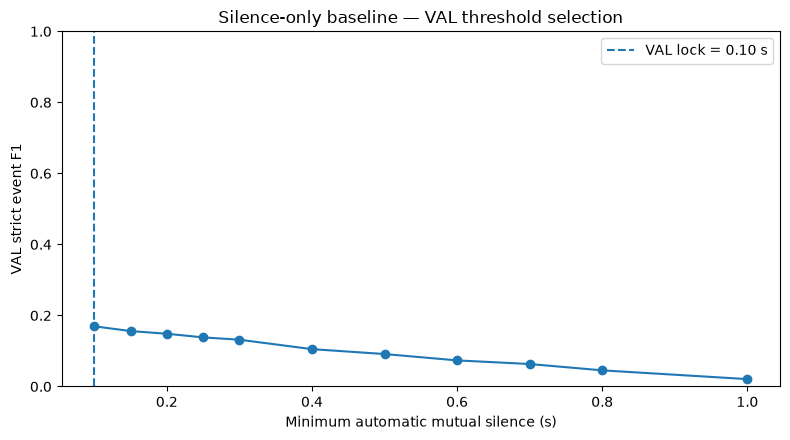

In [7]:
# VAL-only silence-threshold tuning and lock
import matplotlib.pyplot as plt

VAL_AUDIO_MINUTES = 0.0
for sid in VAL_SESSION_IDS:
    p = VAL_AUDIO_FILES.get(str(sid))
    if p is not None:
        d = _audio_duration_s(p)
        if np.isfinite(d):
            VAL_AUDIO_MINUTES += float(d) / 60.0

val_rows = []

for threshold_s in SILENCE_BASELINE_THRESHOLD_GRID:
    pred = silence_predictions_for_threshold(
        VAL_SILENCE_INTERVALS,
        threshold_s,
    )

    metrics, per_session, _ = event_metrics(
        pred[["session", "time"]],
        VAL_SHIFT[["session", "time"]],
        tol=SILENCE_BASELINE_PRIMARY_TOL,
        return_matches=False,
    )

    val_rows.append({
        "minimum_silence_s": float(threshold_s),
        "P": float(metrics["P"]),
        "R": float(metrics["R"]),
        "F1": float(metrics["F1"]),
        "TP": int(metrics["TP"]),
        "FP": int(metrics["FP"]),
        "FN": int(metrics["FN"]),
        "N_pred": int(metrics["N_pred"]),
        "N_gt": int(metrics["N_gt"]),
        "predictions_per_min": safe_div(
            metrics["N_pred"],
            VAL_AUDIO_MINUTES,
        ),
    })

SILENCE_VAL_SWEEP = pd.DataFrame(val_rows)

if len(SILENCE_VAL_SWEEP) == 0:
    raise RuntimeError("Silence baseline VAL sweep is empty.")

SILENCE_VAL_SWEEP = SILENCE_VAL_SWEEP.sort_values(
    [
        "F1",
        "P",
        "N_pred",
        "minimum_silence_s",
    ],
    ascending=[
        False,
        False,
        True,
        False,
    ],
    kind="mergesort",
).reset_index(drop=True)

best = SILENCE_VAL_SWEEP.iloc[0]

SILENCE_LOCK = {
    "minimum_silence_s": float(best["minimum_silence_s"]),
    "selection_split": "VAL",
    "selection_tolerance_s": float(
        SILENCE_BASELINE_PRIMARY_TOL
    ),
    "selection_metric": "F1",
    "selection_rule": (
        "max F1; tie: higher precision; fewer predictions; "
        "longer minimum silence"
    ),
    "val_P": float(best["P"]),
    "val_R": float(best["R"]),
    "val_F1": float(best["F1"]),
    "val_TP": int(best["TP"]),
    "val_FP": int(best["FP"]),
    "val_FN": int(best["FN"]),
    "val_N_pred": int(best["N_pred"]),
    "val_N_gt": int(best["N_gt"]),
    "test_used_for_selection": False,
}

SILENCE_VAL_SWEEP.to_csv(
    SILENCE_BASELINE_DIR / "silence_baseline_val_threshold_sweep.csv",
    index=False,
)

(
    SILENCE_BASELINE_DIR / "silence_baseline_val_lock.json"
).write_text(
    json.dumps(SILENCE_LOCK, indent=2)
)

display(SILENCE_VAL_SWEEP)

print("LOCKED silence threshold:")
print(json.dumps(SILENCE_LOCK, indent=2))
print(
    "✅ Silence threshold selected using VAL only. "
    "TEST remains untouched by selection."
)

fig, ax = plt.subplots(figsize=(8, 4.5))

plot_df = SILENCE_VAL_SWEEP.sort_values(
    "minimum_silence_s"
)

ax.plot(
    plot_df["minimum_silence_s"],
    plot_df["F1"],
    marker="o",
)

ax.axvline(
    SILENCE_LOCK["minimum_silence_s"],
    linestyle="--",
    label=(
        "VAL lock = "
        f"{SILENCE_LOCK['minimum_silence_s']:.2f} s"
    ),
)

ax.set_xlabel("Minimum automatic mutual silence (s)")
ax.set_ylabel("VAL strict event F1")
ax.set_title(
    "Silence-only baseline — VAL threshold selection"
)
ax.set_ylim(0, 1)
ax.legend()

fig.tight_layout()

fig.savefig(
    FIG_DIR / "silence_baseline_val_threshold_sweep.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()

,system,minimum_silence_s,tol,TP,FP,FN,N_pred,N_gt,P,R,F1
0,automatic_silence_only,0.1,0.5,1995,12026,4353,14021,6348,0.142287,0.314272,0.195886
1,automatic_silence_only,0.1,0.7,2111,11910,4237,14021,6348,0.150560,0.332546,0.207276
2,automatic_silence_only,0.1,1.0,2252,11769,4096,14021,6348,0.160616,0.354757,0.221120


Frozen silence-only strict TEST result:
{
  "minimum_silence_s": 0.1,
  "P": 0.14228657014478283,
  "R": 0.31427221172022685,
  "F1": 0.19588590505179443,
  "TP": 1995,
  "FP": 12026,
  "FN": 4353,
  "N_pred": 14021,
  "N_gt": 6348
}
Direct same-task paired comparison:
{
  "comparison": "final_dual_process_minus_automatic_silence_only",
  "common_test_sessions": 232,
  "delta_F1_mean": 0.35608954234153645,
  "delta_F1_lower_95": 0.3318905793453873,
  "delta_F1_upper_95": 0.3794853313901969,
  "prob_delta_F1_gt_0": 1.0,
  "same_dataset": true,
  "same_task": true,
  "same_gt_contract": true,
  "same_primary_tolerance_s": 0.5
}


,action,N_gt,TP,FN,recall
0,ITT,1773,104,1669,0.058658
1,NTT,4575,1891,2684,0.413333


,system,P,R,F1,N_pred,decision_point_supplied,continuous_event_discovery,test_selected
0,Automatic silence only,0.142287,0.314272,0.195886,14021,False,True,False
1,Final dual-process,0.536176,0.568526,0.551877,6731,False,True,False


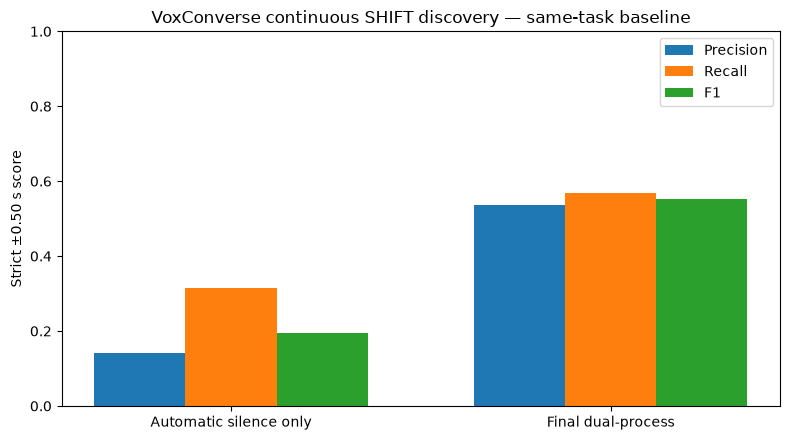

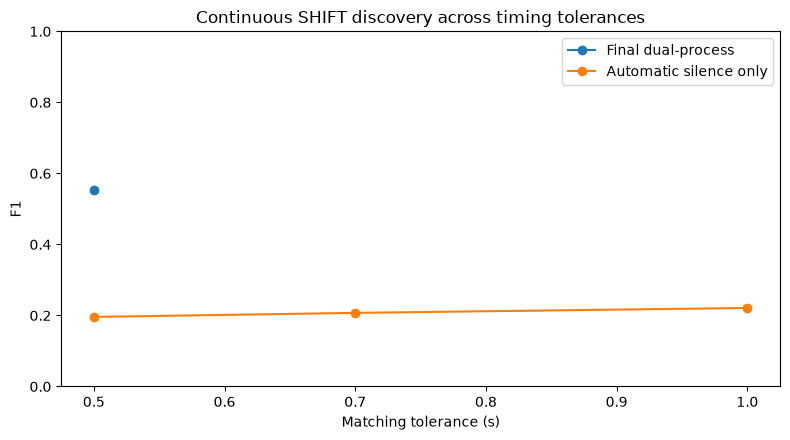

Silence baseline confirmation latency: 0.10 s
✅ Same-dataset/same-task automatic silence baseline completed.


In [8]:
# Frozen silence baseline TEST evaluation + significance
LOCKED_SILENCE_S = float(
    SILENCE_LOCK["minimum_silence_s"]
)

SILENCE_TEST_PRED = silence_predictions_for_threshold(
    TEST_SILENCE_INTERVALS,
    LOCKED_SILENCE_S,
)

SILENCE_TEST_PRED.to_csv(
    SILENCE_BASELINE_DIR / "silence_baseline_test_predictions.csv",
    index=False,
)

silence_test_rows = []
silence_per_session = {}

for tol in [
    STRICT_TOL,
    DATASET_TOL,
    RELAXED_TOL,
]:
    m, ps, matches = event_metrics(
        SILENCE_TEST_PRED[["session", "time"]],
        GT_SHIFT[["session", "time"]],
        tol=float(tol),
        return_matches=True,
    )

    silence_per_session[float(tol)] = ps.copy()

    silence_test_rows.append({
        "system": "automatic_silence_only",
        "minimum_silence_s": LOCKED_SILENCE_S,
        "tol": float(tol),
        **m,
    })

SILENCE_TEST_METRICS = pd.DataFrame(silence_test_rows)

SILENCE_TEST_METRICS.to_csv(
    SILENCE_BASELINE_DIR / "silence_baseline_test_metrics_by_tolerance.csv",
    index=False,
)

SILENCE_STRICT_PER_SESSION = silence_per_session[
    float(STRICT_TOL)
].copy()

SILENCE_STRICT_PER_SESSION.to_csv(
    SILENCE_BASELINE_DIR / "silence_baseline_test_per_session_strict.csv",
    index=False,
)

display(SILENCE_TEST_METRICS)

SILENCE_STRICT = SILENCE_TEST_METRICS[
    np.isclose(
        pd.to_numeric(
            SILENCE_TEST_METRICS["tol"],
            errors="coerce",
        ),
        STRICT_TOL,
    )
].iloc[0].to_dict()

print("Frozen silence-only strict TEST result:")
print(
    json.dumps(
        {
            k: SILENCE_STRICT[k]
            for k in [
                "minimum_silence_s",
                "P",
                "R",
                "F1",
                "TP",
                "FP",
                "FN",
                "N_pred",
                "N_gt",
            ]
        },
        indent=2,
    )
)

def _complete_session_count_table(
    per_session,
    session_ids,
):
    base = pd.DataFrame({
        "session": [str(s) for s in session_ids]
    })
    out = base.merge(
        per_session[
            ["session", "TP", "FP", "FN"]
        ].copy(),
        on="session",
        how="left",
    )
    for c in ["TP", "FP", "FN"]:
        out[c] = (
            pd.to_numeric(out[c], errors="coerce")
            .fillna(0)
            .astype(int)
        )
    return out

SILENCE_COUNTS_ALL_TEST = _complete_session_count_table(
    SILENCE_STRICT_PER_SESSION,
    TEST_SESSION_IDS,
)

DUAL_COUNTS_ALL_TEST = _complete_session_count_table(
    STRICT_PER_SESSION_RECOMPUTED,
    TEST_SESSION_IDS,
)

SILENCE_BOOT_REPS, SILENCE_BOOTSTRAP = bootstrap_count_metrics(
    SILENCE_COUNTS_ALL_TEST,
    reps=BOOTSTRAP_REPLICATES,
    seed=SEED + 5100,
)

pd.DataFrame([
    {
        "system": "automatic_silence_only",
        "point_F1": float(SILENCE_STRICT["F1"]),
        "bootstrap_mean_F1": float(
            SILENCE_BOOTSTRAP.get("F1", {}).get(
                "mean", np.nan
            )
        ),
        "F1_lower_95": float(
            SILENCE_BOOTSTRAP.get("F1", {}).get(
                "lower_95", np.nan
            )
        ),
        "F1_upper_95": float(
            SILENCE_BOOTSTRAP.get("F1", {}).get(
                "upper_95", np.nan
            )
        ),
    }
]).to_csv(
    SILENCE_BASELINE_DIR / "silence_baseline_strict_bootstrap_summary.csv",
    index=False,
)

paired = (
    DUAL_COUNTS_ALL_TEST
    .merge(
        SILENCE_COUNTS_ALL_TEST,
        on="session",
        suffixes=("_dual", "_silence"),
        how="inner",
    )
)

rng_pair = np.random.default_rng(SEED + 5110)
pair_rows = []

for rep in range(int(BOOTSTRAP_REPLICATES)):
    idx_boot = rng_pair.integers(
        0,
        len(paired),
        size=len(paired),
    )
    g = paired.iloc[idx_boot]

    dual = prf_from_counts(
        int(g["TP_dual"].sum()),
        int(g["FP_dual"].sum()),
        int(g["FN_dual"].sum()),
    )
    silence = prf_from_counts(
        int(g["TP_silence"].sum()),
        int(g["FP_silence"].sum()),
        int(g["FN_silence"].sum()),
    )

    pair_rows.append({
        "replicate": int(rep),
        "dual_F1": dual["F1"],
        "silence_F1": silence["F1"],
        "delta_F1_dual_minus_silence": (
            dual["F1"] - silence["F1"]
        ),
    })

SILENCE_VS_DUAL_BOOT = pd.DataFrame(pair_rows)
delta = SILENCE_VS_DUAL_BOOT[
    "delta_F1_dual_minus_silence"
].to_numpy(float)

SILENCE_VS_DUAL_SIGNIFICANCE = {
    "comparison": "final_dual_process_minus_automatic_silence_only",
    "common_test_sessions": int(len(paired)),
    "delta_F1_mean": float(np.mean(delta)),
    "delta_F1_lower_95": float(
        np.quantile(delta, 0.025)
    ),
    "delta_F1_upper_95": float(
        np.quantile(delta, 0.975)
    ),
    "prob_delta_F1_gt_0": float(
        np.mean(delta > 0)
    ),
    "same_dataset": True,
    "same_task": True,
    "same_gt_contract": True,
    "same_primary_tolerance_s": float(STRICT_TOL),
}

SILENCE_VS_DUAL_BOOT.to_csv(
    SILENCE_BASELINE_DIR / "silence_vs_dual_paired_bootstrap_replicates.csv",
    index=False,
)
pd.DataFrame([
    SILENCE_VS_DUAL_SIGNIFICANCE
]).to_csv(
    SILENCE_BASELINE_DIR / "silence_vs_dual_paired_bootstrap_summary.csv",
    index=False,
)

print("Direct same-task paired comparison:")
print(
    json.dumps(
        SILENCE_VS_DUAL_SIGNIFICANCE,
        indent=2,
    )
)

sil_pred = (
    SILENCE_TEST_PRED[["session", "time"]]
    .copy()
    .reset_index(drop=True)
)
sil_pred["_pred_idx"] = np.arange(
    len(sil_pred), dtype=int
)

sil_gt = GT_SHIFT.copy().reset_index(drop=True)
sil_gt["_gt_idx"] = np.arange(
    len(sil_gt), dtype=int
)

matched_gt_idx = set()

for sid in sorted(
    set(sil_pred["session"])
    | set(sil_gt["session"])
):
    ps = sil_pred[
        sil_pred["session"].eq(sid)
    ].reset_index(drop=True)
    gs = sil_gt[
        sil_gt["session"].eq(sid)
    ].reset_index(drop=True)

    pairs = canonical_match_indices(
        ps["time"].to_numpy(float),
        gs["time"].to_numpy(float),
        tol=STRICT_TOL,
    )

    for _, gi, _ in pairs:
        matched_gt_idx.add(
            int(gs.iloc[int(gi)]["_gt_idx"])
        )

sil_gt["matched_by_silence_baseline"] = (
    sil_gt["_gt_idx"].isin(matched_gt_idx)
)

event_rows = []
for action, g in sil_gt.groupby("action"):
    event_rows.append({
        "action": str(action),
        "N_gt": int(len(g)),
        "TP": int(
            g["matched_by_silence_baseline"].sum()
        ),
        "FN": int(
            (~g["matched_by_silence_baseline"]).sum()
        ),
        "recall": float(
            g["matched_by_silence_baseline"].mean()
        ) if len(g) else np.nan,
    })

SILENCE_EVENT_TYPE = pd.DataFrame(event_rows)
SILENCE_EVENT_TYPE.to_csv(
    SILENCE_BASELINE_DIR / "silence_baseline_recall_by_shift_action.csv",
    index=False,
)
display(SILENCE_EVENT_TYPE)

SAME_TASK_VOX_COMPARISON = pd.DataFrame([
    {
        "system": "Automatic silence only",
        "P": float(SILENCE_STRICT["P"]),
        "R": float(SILENCE_STRICT["R"]),
        "F1": float(SILENCE_STRICT["F1"]),
        "N_pred": int(SILENCE_STRICT["N_pred"]),
        "decision_point_supplied": False,
        "continuous_event_discovery": True,
        "test_selected": False,
    },
    {
        "system": "Final dual-process",
        "P": float(STRICT_RECOMPUTED["P"]),
        "R": float(STRICT_RECOMPUTED["R"]),
        "F1": float(STRICT_RECOMPUTED["F1"]),
        "N_pred": int(STRICT_RECOMPUTED["N_pred"]),
        "decision_point_supplied": False,
        "continuous_event_discovery": True,
        "test_selected": False,
    },
])

SAME_TASK_VOX_COMPARISON.to_csv(
    TABLE_DIR / "voxconverse_same_task_silence_vs_dual.csv",
    index=False,
)
display(SAME_TASK_VOX_COMPARISON)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(SAME_TASK_VOX_COMPARISON))
w = 0.24

ax.bar(
    x - w,
    SAME_TASK_VOX_COMPARISON["P"],
    width=w,
    label="Precision",
)
ax.bar(
    x,
    SAME_TASK_VOX_COMPARISON["R"],
    width=w,
    label="Recall",
)
ax.bar(
    x + w,
    SAME_TASK_VOX_COMPARISON["F1"],
    width=w,
    label="F1",
)
ax.set_xticks(x)
ax.set_xticklabels(
    SAME_TASK_VOX_COMPARISON["system"]
)
ax.set_ylim(0, 1)
ax.set_ylabel("Strict ±0.50 s score")
ax.set_title(
    "VoxConverse continuous SHIFT discovery — same-task baseline"
)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIG_DIR / "voxconverse_silence_vs_dual_strict_prf.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
tol_dual = FINAL_METRICS.copy()

if "tol" in tol_dual.columns:
    _tcol = "tol"
elif "tolerance" in tol_dual.columns:
    _tcol = "tolerance"
else:
    _tcol = None

if _tcol is not None:
    dual_tol = tol_dual.copy()
    dual_tol["_tol"] = pd.to_numeric(
        dual_tol[_tcol], errors="coerce"
    )
    dual_tol["_F1"] = pd.to_numeric(
        dual_tol.get(
            "F1",
            dual_tol.get("f1", np.nan),
        ),
        errors="coerce",
    )

    dual_tol = dual_tol[
        dual_tol["_tol"].isin(
            [STRICT_TOL, DATASET_TOL, RELAXED_TOL]
        )
    ]

    ax.plot(
        dual_tol["_tol"],
        dual_tol["_F1"],
        marker="o",
        label="Final dual-process",
    )

ax.plot(
    SILENCE_TEST_METRICS["tol"],
    SILENCE_TEST_METRICS["F1"],
    marker="o",
    label="Automatic silence only",
)
ax.set_xlabel("Matching tolerance (s)")
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
ax.set_title("Continuous SHIFT discovery across timing tolerances")
ax.legend()
fig.tight_layout()
fig.savefig(
    FIG_DIR / "voxconverse_silence_vs_dual_by_tolerance.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

print(
    "Silence baseline confirmation latency:",
    f"{LOCKED_SILENCE_S:.2f} s",
)
print(
    "✅ Same-dataset/same-task automatic silence baseline completed."
)

In [9]:
# Build contextual automatic-silence intervals
def build_speech_islands_with_context(session_turns):
    g = session_turns.copy()

    if len(g) == 0:
        return []

    g["start"] = pd.to_numeric(g["start"], errors="coerce")
    g["end"] = pd.to_numeric(g["end"], errors="coerce")
    g = g.dropna(subset=["start", "end", "speaker"])
    g = g[g["end"] > g["start"]].copy()

    if len(g) == 0:
        return []

    g = g.sort_values(
        ["start", "end"],
        kind="mergesort",
    ).reset_index(drop=True)

    island_members = []
    current = [0]
    current_start = float(g.loc[0, "start"])
    current_end = float(g.loc[0, "end"])

    for row_idx in range(1, len(g)):
        start = float(g.loc[row_idx, "start"])
        end = float(g.loc[row_idx, "end"])

        if start <= current_end + 1e-9:
            current.append(row_idx)
            current_end = max(current_end, end)
        else:
            island_members.append(
                (current_start, current_end, current)
            )
            current = [row_idx]
            current_start = start
            current_end = end

    island_members.append(
        (current_start, current_end, current)
    )

    islands = []

    for island_start, island_end, members in island_members:
        sub = g.loc[members].copy()

        first_row = (
            sub.sort_values(
                ["start", "end"],
                ascending=[True, True],
                kind="mergesort",
            )
            .iloc[0]
        )
        last_row = (
            sub.sort_values(
                ["end", "start"],
                ascending=[False, False],
                kind="mergesort",
            )
            .iloc[0]
        )

        islands.append({
            "island_start": float(island_start),
            "island_end": float(island_end),
            "first_speaker": str(first_row["speaker"]),
            "last_speaker": str(last_row["speaker"]),
            "first_turn_duration_s": float(
                first_row["end"] - first_row["start"]
            ),
            "last_turn_duration_s": float(
                last_row["end"] - last_row["start"]
            ),
            "speaker_set": tuple(
                sorted(set(sub["speaker"].astype(str)))
            ),
        })

    return islands

def build_contextual_silences(
    turns,
    session_ids,
):
    rows = []

    for sid in [str(x) for x in session_ids]:
        g = turns[turns["session"].eq(sid)].copy()
        islands = build_speech_islands_with_context(g)

        if len(islands) < 2:
            continue

        for j in range(len(islands) - 1):
            prev_island = islands[j]
            next_island = islands[j + 1]

            silence_start = float(prev_island["island_end"])
            silence_end = float(next_island["island_start"])
            silence_duration = silence_end - silence_start

            if silence_duration <= 0:
                continue

            prev_speaker = str(prev_island["last_speaker"])
            next_speaker = str(next_island["first_speaker"])

            rows.append({
                "session": sid,
                "silence_start": silence_start,
                "silence_end": silence_end,
                "silence_duration": float(silence_duration),
                "prev_auto_speaker": prev_speaker,
                "next_auto_speaker": next_speaker,
                "automatic_speaker_change": bool(
                    prev_speaker != next_speaker
                ),
                "prev_boundary_turn_duration_s": float(
                    prev_island["last_turn_duration_s"]
                ),
                "next_boundary_turn_duration_s": float(
                    next_island["first_turn_duration_s"]
                ),
                "prev_island_speakers": "|".join(
                    prev_island["speaker_set"]
                ),
                "next_island_speakers": "|".join(
                    next_island["speaker_set"]
                ),
            })

    out = pd.DataFrame(rows)

    if len(out):
        out = (
            out.sort_values(
                ["session", "silence_start"],
                kind="mergesort",
            )
            .drop_duplicates(
                ["session", "silence_start"],
                keep="first",
            )
            .reset_index(drop=True)
        )

    return out

VAL_CONTEXT_SILENCES = build_contextual_silences(
    AUTO_TURNS_VAL,
    VAL_SESSION_IDS,
)

TEST_CONTEXT_SILENCES = build_contextual_silences(
    AUTO_TURNS_TEST,
    TEST_SESSION_IDS,
)

if len(VAL_CONTEXT_SILENCES) == 0:
    raise RuntimeError(
        "No contextual automatic silences were produced on VAL."
    )

if len(TEST_CONTEXT_SILENCES) == 0:
    raise RuntimeError(
        "No contextual automatic silences were produced on TEST."
    )

VAL_CONTEXT_SILENCES.to_csv(
    STRONG_SILENCE_DIR / "val_contextual_automatic_silences.csv",
    index=False,
)
TEST_CONTEXT_SILENCES.to_csv(
    STRONG_SILENCE_DIR / "test_contextual_automatic_silences.csv",
    index=False,
)

def _speaker_change_summary(frame, split_name):
    if len(frame) == 0:
        return {
            "split": split_name,
            "internal_silences": 0,
            "speaker_change_silences": 0,
            "same_speaker_silences": 0,
            "speaker_change_fraction": np.nan,
        }

    change = frame["automatic_speaker_change"].astype(bool)
    return {
        "split": split_name,
        "internal_silences": int(len(frame)),
        "speaker_change_silences": int(change.sum()),
        "same_speaker_silences": int((~change).sum()),
        "speaker_change_fraction": float(change.mean()),
    }

CONTEXT_SILENCE_SUMMARY = pd.DataFrame([
    _speaker_change_summary(VAL_CONTEXT_SILENCES, "val"),
    _speaker_change_summary(TEST_CONTEXT_SILENCES, "test"),
])

CONTEXT_SILENCE_SUMMARY.to_csv(
    STRONG_SILENCE_DIR / "contextual_silence_summary.csv",
    index=False,
)

display(CONTEXT_SILENCE_SUMMARY)

print(
    "Important: TEST counts above are descriptive only. "
    "They are NOT used in parameter selection."
)
print("✅ Contextual automatic-silence table ready.")

,split,internal_silences,speaker_change_silences,same_speaker_silences,speaker_change_fraction
0,val,1023,224,799,0.218964
1,test,14795,3393,11402,0.229334


Important: TEST counts above are descriptive only. They are NOT used in parameter selection.
✅ Contextual automatic-silence table ready.


Best 20 VAL configurations:


,minimum_silence_s,maximum_silence_s,maximum_silence_label,cooldown_s,P,R,F1,TP,FP,FN,N_pred,N_gt
0,0.00,1.5,1.50,1.00,0.606936,0.224839,0.328125,105,68,362,173,467
1,0.00,1.5,1.50,0.50,0.603448,0.224839,0.327613,105,69,362,174,467
2,0.00,1.5,1.50,0.25,0.603448,0.224839,0.327613,105,69,362,174,467
3,0.00,1.5,1.50,0.00,0.603448,0.224839,0.327613,105,69,362,174,467
4,0.00,1.0,1.00,1.00,0.712230,0.211991,0.326733,99,40,368,139,467
5,0.00,1.0,1.00,0.50,0.707143,0.211991,0.326194,99,41,368,140,467
6,0.00,1.0,1.00,0.25,0.707143,0.211991,0.326194,99,41,368,140,467
7,0.00,1.0,1.00,0.00,0.707143,0.211991,0.326194,99,41,368,140,467
8,0.00,2.0,2.00,1.00,0.555556,0.224839,0.320122,105,84,362,189,467
9,0.00,2.0,2.00,0.50,0.552632,0.224839,0.319635,105,85,362,190,467


LOCKED strong silence baseline:
{
  "minimum_silence_s": 0.0,
  "maximum_silence_s": 1.5,
  "cooldown_s": 1.0,
  "require_speech_before": true,
  "require_speech_after": true,
  "require_automatic_speaker_change": true,
  "event_timestamp": "automatic silence onset",
  "selection_split": "VAL",
  "selection_tolerance_s": 0.5,
  "selection_metric": "F1",
  "val_P": 0.6069364161849711,
  "val_R": 0.22483940042826553,
  "val_F1": 0.328125,
  "val_TP": 105,
  "val_FP": 68,
  "val_FN": 362,
  "val_N_pred": 173,
  "val_N_gt": 467,
  "test_used_for_selection": false,
  "audit_test_statistics_used_for_selection": false,
  "human_test_audit_used_for_selection": false
}


,baseline,P,R,F1,N_pred
0,Pure silence,0.124008,0.267666,0.169492,1008
1,Silence + automatic speaker change,0.427861,0.184154,0.257485,201
2,Audit-informed strong silence (VAL locked),0.606936,0.224839,0.328125,173


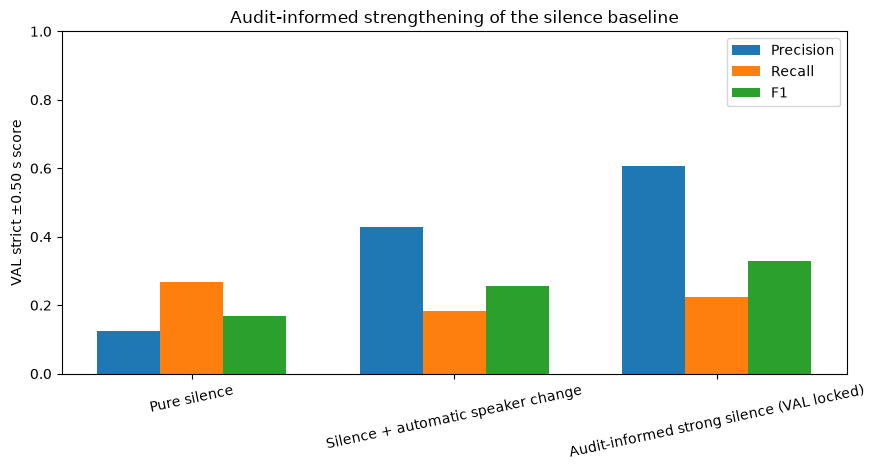

✅ Strong silence parameters frozen using VAL only. TEST has not been used for selection.


In [10]:
# VAL-only tuning of silence + speaker-change baseline
from itertools import product
import matplotlib.pyplot as plt

def apply_prediction_cooldown(pred, cooldown_s):
    cooldown_s = float(cooldown_s)

    if len(pred) == 0 or cooldown_s <= 0:
        return pred.copy().reset_index(drop=True)

    kept_rows = []

    for sid, g in pred.groupby("session", sort=False):
        g = g.sort_values("time", kind="mergesort")
        last_kept = -np.inf

        for row_index, row in g.iterrows():
            t = float(row["time"])

            if t - last_kept >= cooldown_s - 1e-12:
                kept_rows.append(row_index)
                last_kept = t

    return (
        pred.loc[kept_rows]
        .sort_values(["session", "time"], kind="mergesort")
        .reset_index(drop=True)
    )

def strong_silence_predictions(
    contextual_silences,
    minimum_silence_s,
    maximum_silence_s,
    cooldown_s,
):
    minimum_silence_s = float(minimum_silence_s)

    x = contextual_silences[
        contextual_silences["automatic_speaker_change"].astype(bool)
    ].copy()

    x["silence_duration"] = pd.to_numeric(
        x["silence_duration"],
        errors="coerce",
    )

    x = x[
        x["silence_duration"] >= minimum_silence_s
    ].copy()

    if maximum_silence_s is not None:
        maximum_silence_s = float(maximum_silence_s)
        x = x[
            x["silence_duration"] <= maximum_silence_s
        ].copy()

    x["time"] = pd.to_numeric(
        x["silence_start"],
        errors="coerce",
    )

    x["decision_time"] = x["time"] + minimum_silence_s
    x["minimum_silence_s"] = minimum_silence_s
    x["maximum_silence_s"] = (
        np.nan
        if maximum_silence_s is None
        else float(maximum_silence_s)
    )
    x["cooldown_s"] = float(cooldown_s)

    keep_cols = [
        "session",
        "time",
        "decision_time",
        "silence_duration",
        "minimum_silence_s",
        "maximum_silence_s",
        "cooldown_s",
        "prev_auto_speaker",
        "next_auto_speaker",
    ]

    x = canonicalize_event_table(
        x[keep_cols],
        time_col="time",
        nonnegative=True,
    )

    x = apply_prediction_cooldown(
        x,
        cooldown_s,
    )

    return x

strong_val_rows = []

for min_s, max_s, cooldown_s in product(
    STRONG_SILENCE_MIN_GRID,
    STRONG_SILENCE_MAX_GRID,
    STRONG_SILENCE_COOLDOWN_GRID,
):
    if max_s is not None and float(max_s) < float(min_s):
        continue

    pred = strong_silence_predictions(
        VAL_CONTEXT_SILENCES,
        minimum_silence_s=min_s,
        maximum_silence_s=max_s,
        cooldown_s=cooldown_s,
    )

    metrics, _, _ = event_metrics(
        pred[["session", "time"]],
        VAL_SHIFT[["session", "time"]],
        tol=STRICT_TOL,
        return_matches=False,
    )

    strong_val_rows.append({
        "minimum_silence_s": float(min_s),
        "maximum_silence_s": (
            np.nan if max_s is None else float(max_s)
        ),
        "maximum_silence_label": (
            "none" if max_s is None else f"{float(max_s):.2f}"
        ),
        "cooldown_s": float(cooldown_s),
        "P": float(metrics["P"]),
        "R": float(metrics["R"]),
        "F1": float(metrics["F1"]),
        "TP": int(metrics["TP"]),
        "FP": int(metrics["FP"]),
        "FN": int(metrics["FN"]),
        "N_pred": int(metrics["N_pred"]),
        "N_gt": int(metrics["N_gt"]),
    })

STRONG_SILENCE_VAL_SWEEP = pd.DataFrame(
    strong_val_rows
)

if len(STRONG_SILENCE_VAL_SWEEP) == 0:
    raise RuntimeError(
        "Strong silence baseline VAL sweep is empty."
    )

STRONG_SILENCE_VAL_SWEEP = (
    STRONG_SILENCE_VAL_SWEEP
    .sort_values(
        [
            "F1",
            "P",
            "R",
            "N_pred",
            "cooldown_s",
            "minimum_silence_s",
        ],
        ascending=[
            False,
            False,
            False,
            True,
            False,
            False,
        ],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

best = STRONG_SILENCE_VAL_SWEEP.iloc[0]

best_max = (
    None
    if pd.isna(best["maximum_silence_s"])
    else float(best["maximum_silence_s"])
)

STRONG_SILENCE_LOCK = {
    "minimum_silence_s": float(best["minimum_silence_s"]),
    "maximum_silence_s": best_max,
    "cooldown_s": float(best["cooldown_s"]),
    "require_speech_before": True,
    "require_speech_after": True,
    "require_automatic_speaker_change": True,
    "event_timestamp": "automatic silence onset",
    "selection_split": "VAL",
    "selection_tolerance_s": float(STRICT_TOL),
    "selection_metric": "F1",
    "val_P": float(best["P"]),
    "val_R": float(best["R"]),
    "val_F1": float(best["F1"]),
    "val_TP": int(best["TP"]),
    "val_FP": int(best["FP"]),
    "val_FN": int(best["FN"]),
    "val_N_pred": int(best["N_pred"]),
    "val_N_gt": int(best["N_gt"]),
    "test_used_for_selection": False,
    "audit_test_statistics_used_for_selection": False,
    "human_test_audit_used_for_selection": False,
}

STRONG_SILENCE_VAL_SWEEP.to_csv(
    STRONG_SILENCE_DIR / "strong_silence_val_grid.csv",
    index=False,
)

(
    STRONG_SILENCE_DIR / "strong_silence_val_lock.json"
).write_text(
    json.dumps(
        STRONG_SILENCE_LOCK,
        indent=2,
    )
)

print("Best 20 VAL configurations:")
display(
    STRONG_SILENCE_VAL_SWEEP.head(20)
)

print("LOCKED strong silence baseline:")
print(
    json.dumps(
        STRONG_SILENCE_LOCK,
        indent=2,
    )
)

val_internal_at_pure_threshold = strong_silence_predictions(
    VAL_CONTEXT_SILENCES,
    minimum_silence_s=float(
        SILENCE_LOCK["minimum_silence_s"]
    ),
    maximum_silence_s=None,
    cooldown_s=0.0,
)

m_internal_change, _, _ = event_metrics(
    val_internal_at_pure_threshold[["session", "time"]],
    VAL_SHIFT[["session", "time"]],
    tol=STRICT_TOL,
    return_matches=False,
)

VAL_STRONG_LOCK_PRED = strong_silence_predictions(
    VAL_CONTEXT_SILENCES,
    minimum_silence_s=STRONG_SILENCE_LOCK[
        "minimum_silence_s"
    ],
    maximum_silence_s=STRONG_SILENCE_LOCK[
        "maximum_silence_s"
    ],
    cooldown_s=STRONG_SILENCE_LOCK[
        "cooldown_s"
    ],
)

m_strong_val, _, _ = event_metrics(
    VAL_STRONG_LOCK_PRED[["session", "time"]],
    VAL_SHIFT[["session", "time"]],
    tol=STRICT_TOL,
    return_matches=False,
)

VAL_SILENCE_PROGRESSION = pd.DataFrame([
    {
        "baseline": "Pure silence",
        "P": float(SILENCE_LOCK["val_P"]),
        "R": float(SILENCE_LOCK["val_R"]),
        "F1": float(SILENCE_LOCK["val_F1"]),
        "N_pred": int(SILENCE_LOCK["val_N_pred"]),
    },
    {
        "baseline": "Silence + automatic speaker change",
        "P": float(m_internal_change["P"]),
        "R": float(m_internal_change["R"]),
        "F1": float(m_internal_change["F1"]),
        "N_pred": int(m_internal_change["N_pred"]),
    },
    {
        "baseline": "Audit-informed strong silence (VAL locked)",
        "P": float(m_strong_val["P"]),
        "R": float(m_strong_val["R"]),
        "F1": float(m_strong_val["F1"]),
        "N_pred": int(m_strong_val["N_pred"]),
    },
])

VAL_SILENCE_PROGRESSION.to_csv(
    STRONG_SILENCE_DIR / "val_silence_baseline_progression.csv",
    index=False,
)

display(VAL_SILENCE_PROGRESSION)

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(VAL_SILENCE_PROGRESSION))
w = 0.24

ax.bar(
    x - w,
    VAL_SILENCE_PROGRESSION["P"],
    width=w,
    label="Precision",
)
ax.bar(
    x,
    VAL_SILENCE_PROGRESSION["R"],
    width=w,
    label="Recall",
)
ax.bar(
    x + w,
    VAL_SILENCE_PROGRESSION["F1"],
    width=w,
    label="F1",
)

ax.set_xticks(x)
ax.set_xticklabels(
    VAL_SILENCE_PROGRESSION["baseline"],
    rotation=12,
)
ax.set_ylim(0, 1)
ax.set_ylabel("VAL strict ±0.50 s score")
ax.set_title(
    "Audit-informed strengthening of the silence baseline"
)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIG_DIR / "val_audit_informed_silence_progression.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

print(
    "✅ Strong silence parameters frozen using VAL only. "
    "TEST has not been used for selection."
)

,system,minimum_silence_s,maximum_silence_s,cooldown_s,tol,TP,FP,FN,N_pred,N_gt,P,R,F1
0,silence_plus_automatic_speaker_change,0.0,1.5,1.0,0.5,1529,1072,4819,2601,6348,0.587851,0.240863,0.341714
1,silence_plus_automatic_speaker_change,0.0,1.5,1.0,0.7,1570,1031,4778,2601,6348,0.603614,0.247322,0.350877
2,silence_plus_automatic_speaker_change,0.0,1.5,1.0,1.0,1621,980,4727,2601,6348,0.623222,0.255356,0.362275


Frozen strong-silence strict TEST result:
{
  "minimum_silence_s": 0.0,
  "maximum_silence_s": 1.5,
  "cooldown_s": 1.0,
  "P": 0.5878508266051519,
  "R": 0.24086326402016384,
  "F1": 0.34171415800648125,
  "TP": 1529,
  "FP": 1072,
  "FN": 4819,
  "N_pred": 2601,
  "N_gt": 6348
}
Strong silence minus pure silence:
{
  "comparison": "strong_silence_minus_pure_silence",
  "common_sessions": 232,
  "delta_F1_mean": 0.14555259446181087,
  "delta_F1_lower_95": 0.11688751233821769,
  "delta_F1_upper_95": 0.17723619847453484,
  "prob_delta_F1_gt_0": 1.0
}
Dual-process minus strong silence:
{
  "comparison": "dual_process_minus_strong_silence",
  "common_sessions": 232,
  "delta_F1_mean": 0.21038908490289085,
  "delta_F1_lower_95": 0.18721609871152955,
  "delta_F1_upper_95": 0.2322226874941738,
  "prob_delta_F1_gt_0": 1.0
}


,action,N_gt,TP,FN,recall
0,ITT,1773,56,1717,0.031585
1,NTT,4575,1473,3102,0.321967


,system,P,R,F1,N_pred
0,Pure automatic silence,0.142287,0.314272,0.195886,14021
1,Silence + automatic speaker change,0.587851,0.240863,0.341714,2601
2,Final dual-process,0.536176,0.568526,0.551877,6731


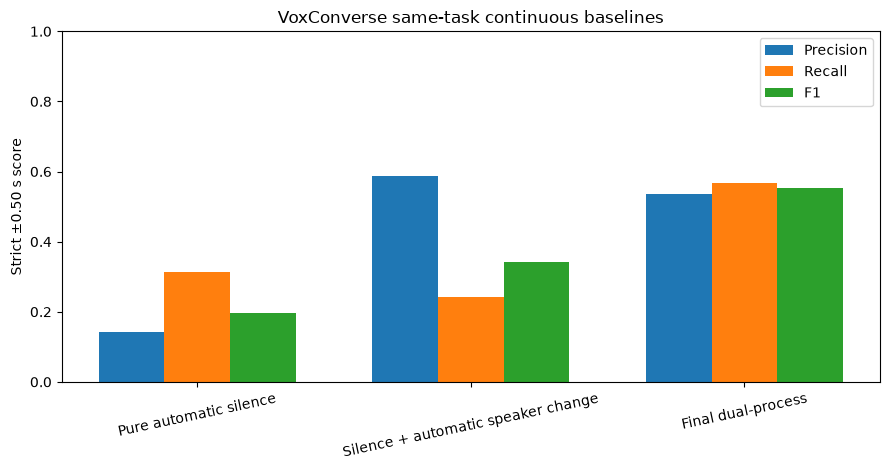

✅ Strong silence TEST evaluation complete. No TEST parameter selection was performed.


In [11]:
# Frozen strong-silence TEST evaluation
STRONG_SILENCE_TEST_PRED = strong_silence_predictions(
    TEST_CONTEXT_SILENCES,
    minimum_silence_s=STRONG_SILENCE_LOCK[
        "minimum_silence_s"
    ],
    maximum_silence_s=STRONG_SILENCE_LOCK[
        "maximum_silence_s"
    ],
    cooldown_s=STRONG_SILENCE_LOCK[
        "cooldown_s"
    ],
)

STRONG_SILENCE_TEST_PRED.to_csv(
    STRONG_SILENCE_DIR / "strong_silence_test_predictions.csv",
    index=False,
)

strong_test_rows = []
strong_per_session = {}

for tol in [
    STRICT_TOL,
    DATASET_TOL,
    RELAXED_TOL,
]:
    m, ps, _ = event_metrics(
        STRONG_SILENCE_TEST_PRED[["session", "time"]],
        GT_SHIFT[["session", "time"]],
        tol=float(tol),
        return_matches=False,
    )

    strong_per_session[float(tol)] = ps.copy()

    strong_test_rows.append({
        "system": "silence_plus_automatic_speaker_change",
        "minimum_silence_s": STRONG_SILENCE_LOCK[
            "minimum_silence_s"
        ],
        "maximum_silence_s": STRONG_SILENCE_LOCK[
            "maximum_silence_s"
        ],
        "cooldown_s": STRONG_SILENCE_LOCK[
            "cooldown_s"
        ],
        "tol": float(tol),
        **m,
    })

STRONG_SILENCE_TEST_METRICS = pd.DataFrame(
    strong_test_rows
)

STRONG_SILENCE_TEST_METRICS.to_csv(
    STRONG_SILENCE_DIR / "strong_silence_test_metrics_by_tolerance.csv",
    index=False,
)

display(STRONG_SILENCE_TEST_METRICS)

STRONG_SILENCE_STRICT = (
    STRONG_SILENCE_TEST_METRICS[
        np.isclose(
            pd.to_numeric(
                STRONG_SILENCE_TEST_METRICS["tol"],
                errors="coerce",
            ),
            STRICT_TOL,
        )
    ]
    .iloc[0]
    .to_dict()
)

print("Frozen strong-silence strict TEST result:")
print(
    json.dumps(
        {
            k: STRONG_SILENCE_STRICT[k]
            for k in [
                "minimum_silence_s",
                "maximum_silence_s",
                "cooldown_s",
                "P",
                "R",
                "F1",
                "TP",
                "FP",
                "FN",
                "N_pred",
                "N_gt",
            ]
        },
        indent=2,
        default=str,
    )
)

STRONG_COUNTS_ALL_TEST = _complete_session_count_table(
    strong_per_session[float(STRICT_TOL)],
    TEST_SESSION_IDS,
)

_, STRONG_SILENCE_BOOTSTRAP = bootstrap_count_metrics(
    STRONG_COUNTS_ALL_TEST,
    reps=BOOTSTRAP_REPLICATES,
    seed=SEED + 5200,
)

def paired_f1_delta_bootstrap(
    left_counts,
    right_counts,
    left_name,
    right_name,
    seed,
):
    paired = left_counts.merge(
        right_counts,
        on="session",
        suffixes=("_left", "_right"),
        how="inner",
    )

    rng = np.random.default_rng(int(seed))
    rows = []

    for rep in range(int(BOOTSTRAP_REPLICATES)):
        idx_boot = rng.integers(
            0,
            len(paired),
            size=len(paired),
        )
        g = paired.iloc[idx_boot]

        left = prf_from_counts(
            int(g["TP_left"].sum()),
            int(g["FP_left"].sum()),
            int(g["FN_left"].sum()),
        )
        right = prf_from_counts(
            int(g["TP_right"].sum()),
            int(g["FP_right"].sum()),
            int(g["FN_right"].sum()),
        )

        rows.append({
            "replicate": int(rep),
            "left_F1": float(left["F1"]),
            "right_F1": float(right["F1"]),
            "delta_F1": float(
                left["F1"] - right["F1"]
            ),
        })

    reps = pd.DataFrame(rows)
    delta = reps["delta_F1"].to_numpy(float)

    summary = {
        "comparison": f"{left_name}_minus_{right_name}",
        "common_sessions": int(len(paired)),
        "delta_F1_mean": float(np.mean(delta)),
        "delta_F1_lower_95": float(
            np.quantile(delta, 0.025)
        ),
        "delta_F1_upper_95": float(
            np.quantile(delta, 0.975)
        ),
        "prob_delta_F1_gt_0": float(
            np.mean(delta > 0)
        ),
    }

    return reps, summary

STRONG_VS_PURE_REPS, STRONG_VS_PURE = (
    paired_f1_delta_bootstrap(
        STRONG_COUNTS_ALL_TEST,
        SILENCE_COUNTS_ALL_TEST,
        "strong_silence",
        "pure_silence",
        seed=SEED + 5210,
    )
)

DUAL_VS_STRONG_REPS, DUAL_VS_STRONG = (
    paired_f1_delta_bootstrap(
        DUAL_COUNTS_ALL_TEST,
        STRONG_COUNTS_ALL_TEST,
        "dual_process",
        "strong_silence",
        seed=SEED + 5220,
    )
)

STRONG_VS_PURE_REPS.to_csv(
    STRONG_SILENCE_DIR / "strong_vs_pure_paired_bootstrap_replicates.csv",
    index=False,
)
pd.DataFrame([STRONG_VS_PURE]).to_csv(
    STRONG_SILENCE_DIR / "strong_vs_pure_paired_bootstrap_summary.csv",
    index=False,
)

DUAL_VS_STRONG_REPS.to_csv(
    STRONG_SILENCE_DIR / "dual_vs_strong_silence_paired_bootstrap_replicates.csv",
    index=False,
)
pd.DataFrame([DUAL_VS_STRONG]).to_csv(
    STRONG_SILENCE_DIR / "dual_vs_strong_silence_paired_bootstrap_summary.csv",
    index=False,
)

print("Strong silence minus pure silence:")
print(json.dumps(STRONG_VS_PURE, indent=2))

print("Dual-process minus strong silence:")
print(json.dumps(DUAL_VS_STRONG, indent=2))

strong_pred = (
    STRONG_SILENCE_TEST_PRED[["session", "time"]]
    .copy()
    .reset_index(drop=True)
)
strong_pred["_pred_idx"] = np.arange(
    len(strong_pred),
    dtype=int,
)

strong_gt = GT_SHIFT.copy().reset_index(drop=True)
strong_gt["_gt_idx"] = np.arange(
    len(strong_gt),
    dtype=int,
)

matched_gt_idx = set()

for sid in sorted(
    set(strong_pred["session"])
    | set(strong_gt["session"])
):
    ps = strong_pred[
        strong_pred["session"].eq(sid)
    ].reset_index(drop=True)
    gs = strong_gt[
        strong_gt["session"].eq(sid)
    ].reset_index(drop=True)

    pairs = canonical_match_indices(
        ps["time"].to_numpy(float),
        gs["time"].to_numpy(float),
        tol=STRICT_TOL,
    )

    for _, gi, _ in pairs:
        matched_gt_idx.add(
            int(gs.iloc[int(gi)]["_gt_idx"])
        )

strong_gt["matched_by_strong_silence"] = (
    strong_gt["_gt_idx"].isin(
        matched_gt_idx
    )
)

strong_action_rows = []

for action, g in strong_gt.groupby("action"):
    strong_action_rows.append({
        "action": str(action),
        "N_gt": int(len(g)),
        "TP": int(
            g["matched_by_strong_silence"].sum()
        ),
        "FN": int(
            (~g["matched_by_strong_silence"]).sum()
        ),
        "recall": float(
            g["matched_by_strong_silence"].mean()
        ) if len(g) else np.nan,
    })

STRONG_SILENCE_EVENT_TYPE = pd.DataFrame(
    strong_action_rows
)

STRONG_SILENCE_EVENT_TYPE.to_csv(
    STRONG_SILENCE_DIR / "strong_silence_recall_by_shift_action.csv",
    index=False,
)

display(STRONG_SILENCE_EVENT_TYPE)

VOX_SAME_TASK_BASELINES = pd.DataFrame([
    {
        "system": "Pure automatic silence",
        "P": float(SILENCE_STRICT["P"]),
        "R": float(SILENCE_STRICT["R"]),
        "F1": float(SILENCE_STRICT["F1"]),
        "N_pred": int(SILENCE_STRICT["N_pred"]),
    },
    {
        "system": "Silence + automatic speaker change",
        "P": float(STRONG_SILENCE_STRICT["P"]),
        "R": float(STRONG_SILENCE_STRICT["R"]),
        "F1": float(STRONG_SILENCE_STRICT["F1"]),
        "N_pred": int(STRONG_SILENCE_STRICT["N_pred"]),
    },
    {
        "system": "Final dual-process",
        "P": float(STRICT_RECOMPUTED["P"]),
        "R": float(STRICT_RECOMPUTED["R"]),
        "F1": float(STRICT_RECOMPUTED["F1"]),
        "N_pred": int(STRICT_RECOMPUTED["N_pred"]),
    },
])

VOX_SAME_TASK_BASELINES.to_csv(
    TABLE_DIR / "voxconverse_same_task_silence_strong_dual.csv",
    index=False,
)

display(VOX_SAME_TASK_BASELINES)

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(VOX_SAME_TASK_BASELINES))
w = 0.24

ax.bar(
    x - w,
    VOX_SAME_TASK_BASELINES["P"],
    width=w,
    label="Precision",
)
ax.bar(
    x,
    VOX_SAME_TASK_BASELINES["R"],
    width=w,
    label="Recall",
)
ax.bar(
    x + w,
    VOX_SAME_TASK_BASELINES["F1"],
    width=w,
    label="F1",
)

ax.set_xticks(x)
ax.set_xticklabels(
    VOX_SAME_TASK_BASELINES["system"],
    rotation=12,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Strict ±0.50 s score")
ax.set_title(
    "VoxConverse same-task continuous baselines"
)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIG_DIR / "voxconverse_pure_strong_silence_vs_dual.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

print(
    "✅ Strong silence TEST evaluation complete. "
    "No TEST parameter selection was performed."
)

In [12]:
STRONG_SILENCE_PROTOCOL = {
    "name": "silence_plus_automatic_speaker_change",
    "same_dataset_as_main_system": True,
    "same_continuous_task_as_main_system": True,
    "same_gt_contract_as_main_system": True,
    "ground_truth_rttm_used_to_generate_predictions": False,
    "automatic_activity_source": str(
        AUTO_PYANNOTE_TURNS_PATH
    ),
    "uses_wavlm_turn_taking_scores": False,
    "uses_text": False,
    "uses_future_activity_projection": False,
    "uses_ranker": False,
    "uses_system2_verifier": False,
    "uses_automatic_speaker_identity": True,
    "requires_speech_before": True,
    "requires_speech_after": True,
    "requires_automatic_speaker_change": True,
    "val_selected_parameters": STRONG_SILENCE_LOCK,
    "test_used_for_selection": False,
    "audit_test_statistics_used_for_selection": False,
    "human_test_audit_used_for_selection": False,
    "limitation": (
        "Still requires a positive mutual-silence interval, so it cannot "
        "recover many overlapping interruptions."
    ),
    "streaming_causality_note": (
        "The cached automatic pyannote diarization may use offline context. "
        "This is therefore a continuous automatic-activity baseline, not a "
        "claim of strictly streaming causal diarization."
    ),
}

(
    STRONG_SILENCE_DIR / "strong_silence_protocol.json"
).write_text(
    json.dumps(
        STRONG_SILENCE_PROTOCOL,
        indent=2,
        default=str,
    )
)

print("Paper interpretation:")
print(
    "- Pure silence remains the naïve baseline."
)
print(
    "- Silence + automatic speaker change is the stronger simple baseline."
)
print(
    "- The dual-process model remains the learned full system."
)
print(
    "- If the strong baseline improves, that is evidence that speaker identity "
    "removes many same-speaker pause false alarms."
)
print(
    "- If ITT recall remains low, that is expected: overlapping interruptions "
    "contain no qualifying mutual silence."
)

Paper interpretation:
- Pure silence remains the naïve baseline.
- Silence + automatic speaker change is the stronger simple baseline.
- The dual-process model remains the learned full system.
- If the strong baseline improves, that is evidence that speaker identity removes many same-speaker pause false alarms.
- If ITT recall remains low, that is expected: overlapping interruptions contain no qualifying mutual silence.


⚠️ 14 evaluated session(s) have <2 RTTM speakers and are excluded from the requested 2/3/4/5/6+ multiparty strata.


,speaker_bucket,sessions,mean_n_speakers,total_minutes,macro_session_f1,TP,FP,FN,P,R,F1,F1_mean,F1_lower_95,F1_upper_95
0,2,31,2.000000,268.789333,0.526895,395,300,239,0.568345,0.623028,0.594432,0.595875,0.534760,0.658350
1,3,18,3.000000,105.092267,0.390974,88,70,144,0.556962,0.379310,0.451282,0.454886,0.345511,0.575110
2,4,22,4.000000,162.973867,0.546473,240,232,142,0.508475,0.628272,0.562061,0.562461,0.472470,0.636486
3,5,13,5.000000,107.859200,0.626061,160,106,120,0.601504,0.571429,0.586081,0.597746,0.523591,0.730616
4,6+,133,9.165414,1865.011200,0.573092,2726,2394,2094,0.532422,0.565560,0.548491,0.548859,0.523174,0.576132


{'sessions_in_correlation': 217, 'excluded_lt2_speaker_sessions': 14, 'spearman_rho_n_speakers_vs_session_f1': 0.06929128892199465, 'p_value': 0.3096051990059749}


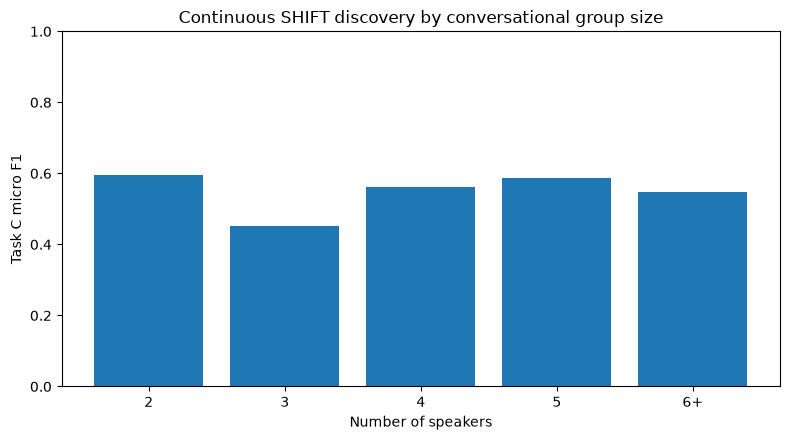

In [13]:
# Continuous Task C by speaker count
def speaker_bucket(n):
    if pd.isna(n):
        return np.nan
    n = int(n)
    if n < 2: return "1"
    if n == 2: return "2"
    if n == 3: return "3"
    if n == 4: return "4"
    if n == 5: return "5"
    return "6+"

SESSION_ANALYSIS["speaker_bucket"] = SESSION_ANALYSIS["n_speakers"].map(speaker_bucket)
_single = int((SESSION_ANALYSIS["speaker_bucket"] == "1").sum())
if _single:
    print(
        f"⚠️ {_single} evaluated session(s) have <2 RTTM speakers and are "
        "excluded from the requested 2/3/4/5/6+ multiparty strata."
    )

rows = []
for bucket in ["2", "3", "4", "5", "6+"]:
    g = SESSION_ANALYSIS[SESSION_ANALYSIS["speaker_bucket"].eq(bucket)].copy()
    if not len(g):
        continue
    rows.append({
        "speaker_bucket": bucket,
        "sessions": int(len(g)),
        "mean_n_speakers": float(g["n_speakers"].mean()),
        "total_minutes": float(g["duration_min"].sum()),
        "macro_session_f1": float(g["F1"].mean()),
        **aggregate_count_metrics(g),
        **session_bootstrap_ci(g, BOOTSTRAP_REPLICATES, SEED + 10 + len(rows)),
    })

SPEAKER_COUNT_TASKC = pd.DataFrame(rows)
SPEAKER_COUNT_TASKC.to_csv(TABLE_DIR / "taskC_performance_by_speaker_count.csv", index=False)
display(SPEAKER_COUNT_TASKC)

MULTIPARTY_SESSION_ANALYSIS = SESSION_ANALYSIS[
    pd.to_numeric(SESSION_ANALYSIS["n_speakers"], errors="coerce") >= 2
].copy()

rho_sc, p_sc = safe_spearman(
    MULTIPARTY_SESSION_ANALYSIS["n_speakers"],
    MULTIPARTY_SESSION_ANALYSIS["F1"],
)
SPEAKER_COUNT_CORRELATION = {
    "sessions_in_correlation": int(len(MULTIPARTY_SESSION_ANALYSIS)),
    "excluded_lt2_speaker_sessions": int(
        len(SESSION_ANALYSIS) - len(MULTIPARTY_SESSION_ANALYSIS)
    ),
    "spearman_rho_n_speakers_vs_session_f1": float(rho_sc),
    "p_value": float(p_sc),
}
pd.DataFrame([SPEAKER_COUNT_CORRELATION]).to_csv(
    TABLE_DIR / "speaker_count_session_f1_correlation_multiparty_only.csv",
    index=False,
)
print(SPEAKER_COUNT_CORRELATION)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(SPEAKER_COUNT_TASKC["speaker_bucket"], SPEAKER_COUNT_TASKC["F1"])
ax.set_xlabel("Number of speakers")
ax.set_ylabel("Task C micro F1")
ax.set_title("Continuous SHIFT discovery by conversational group size")
ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(FIG_DIR / "taskC_f1_by_speaker_count.png", dpi=220, bbox_inches="tight")
plt.show()

,speaker_bucket,n,shift_rate,accuracy,balanced_accuracy,macro_f1,precision_shift,recall_shift,f1_shift
0,2,1016,0.510827,0.880906,0.880871,0.880855,0.884170,0.882466,0.883317
1,3,330,0.569697,0.827273,0.835481,0.826698,0.906832,0.776596,0.836676
2,4,616,0.491883,0.873377,0.873291,0.873329,0.873754,0.867987,0.870861
3,5,393,0.465649,0.867684,0.868462,0.867374,0.842932,0.879781,0.860963
4,6+,6560,0.600305,0.840244,0.836222,0.834403,0.874935,0.856272,0.865503


,speaker_bucket,Task_A_oracle_F1,Task_C_continuous_F1,oracle_to_continuous_gap
0,2,0.883317,0.594432,0.288885
1,3,0.836676,0.451282,0.385394
2,4,0.870861,0.562061,0.308800
3,5,0.860963,0.586081,0.274882
4,6+,0.865503,0.548491,0.317012


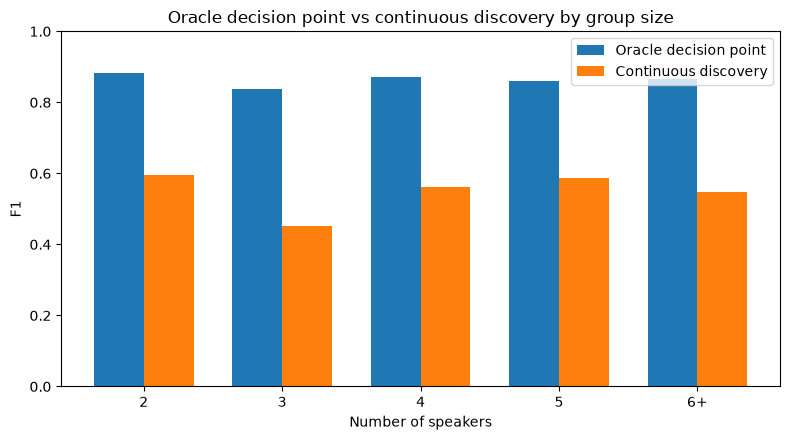

In [14]:
# Oracle Task A by speaker count
B2 = BRANCH2_SCORES.copy()
if "prediction_setup" in B2.columns:
    x = B2[B2["prediction_setup"].astype(str).eq("silent_100ms")].copy()
    if len(x):
        B2 = x

B2["session"] = B2["session"].astype(str)
B2["label"] = pd.to_numeric(B2["label"], errors="coerce").fillna(-1).astype(int)
B2["pred_label"] = pd.to_numeric(B2["pred_label"], errors="coerce").fillna(-1).astype(int)
B2 = B2[B2["label"].isin([0, 1]) & B2["pred_label"].isin([0, 1])]

B2 = B2.merge(SESSION_META[["session", "n_speakers"]], on="session", how="left")
if B2["n_speakers"].isna().any():
    bad = sorted(B2.loc[B2["n_speakers"].isna(), "session"].astype(str).unique())
    raise RuntimeError(
        "Speaker-count metadata missing for Branch-2 TEST session(s): "
        + ", ".join(bad[:10])
    )
B2["speaker_bucket"] = B2["n_speakers"].map(speaker_bucket)

rows = []
for bucket in ["2", "3", "4", "5", "6+"]:
    g = B2[B2["speaker_bucket"].eq(bucket)]
    if not len(g):
        continue
    y = g["label"].to_numpy(int)
    yp = g["pred_label"].to_numpy(int)
    p, r, f1, _ = precision_recall_fscore_support(y, yp, labels=[1], average=None, zero_division=0)
    rows.append({
        "speaker_bucket": bucket,
        "n": int(len(g)),
        "shift_rate": float(np.mean(y)),
        "accuracy": float(accuracy_score(y, yp)),
        "balanced_accuracy": float(balanced_accuracy_score(y, yp)),
        "macro_f1": float(f1_score(y, yp, average="macro", zero_division=0)),
        "precision_shift": float(p[0]),
        "recall_shift": float(r[0]),
        "f1_shift": float(f1[0]),
    })

SPEAKER_COUNT_TASKA = pd.DataFrame(rows)
SPEAKER_COUNT_TASKA.to_csv(TABLE_DIR / "taskA_oracle_performance_by_speaker_count.csv", index=False)
display(SPEAKER_COUNT_TASKA)

SC_COMPARISON = SPEAKER_COUNT_TASKA[["speaker_bucket", "f1_shift"]].rename(
    columns={"f1_shift": "Task_A_oracle_F1"}
).merge(
    SPEAKER_COUNT_TASKC[["speaker_bucket", "F1"]].rename(columns={"F1": "Task_C_continuous_F1"}),
    on="speaker_bucket", how="outer"
)
SC_COMPARISON["oracle_to_continuous_gap"] = (
    SC_COMPARISON["Task_A_oracle_F1"] - SC_COMPARISON["Task_C_continuous_F1"]
)
SC_COMPARISON.to_csv(TABLE_DIR / "speaker_count_oracle_vs_continuous.csv", index=False)
display(SC_COMPARISON)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(SC_COMPARISON))
w = 0.36
ax.bar(x - w/2, SC_COMPARISON["Task_A_oracle_F1"], width=w, label="Oracle decision point")
ax.bar(x + w/2, SC_COMPARISON["Task_C_continuous_F1"], width=w, label="Continuous discovery")
ax.set_xticks(x)
ax.set_xticklabels(SC_COMPARISON["speaker_bucket"])
ax.set_xlabel("Number of speakers")
ax.set_ylabel("F1")
ax.set_title("Oracle decision point vs continuous discovery by group size")
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "oracle_vs_continuous_by_speaker_count.png", dpi=220, bbox_inches="tight")
plt.show()

Overlap analysis sessions: 217 | excluded <2-speaker sessions: 14


,overlap_bucket,sessions,mean_overlap_ratio,median_overlap_ratio,mean_n_speakers,TP,FP,FN,P,R,F1,F1_mean,F1_lower_95,F1_upper_95
0,medium,72,0.016682,0.016351,6.513889,1004,633,542,0.613317,0.649418,0.630851,0.630999,0.595814,0.667962
1,low,73,0.001275,0.000850,7.178082,847,627,567,0.574627,0.599010,0.586565,0.586199,0.533109,0.641182
2,high,72,0.087383,0.066828,6.875000,1758,1842,1630,0.488333,0.518890,0.503148,0.503320,0.478822,0.528112


{'spearman_rho_overlap_vs_session_f1': -0.1588850541077027, 'p_value': 0.019185806684653375, 'tertile_boundaries': [0.004531684545093365, 0.03092039995822885]}


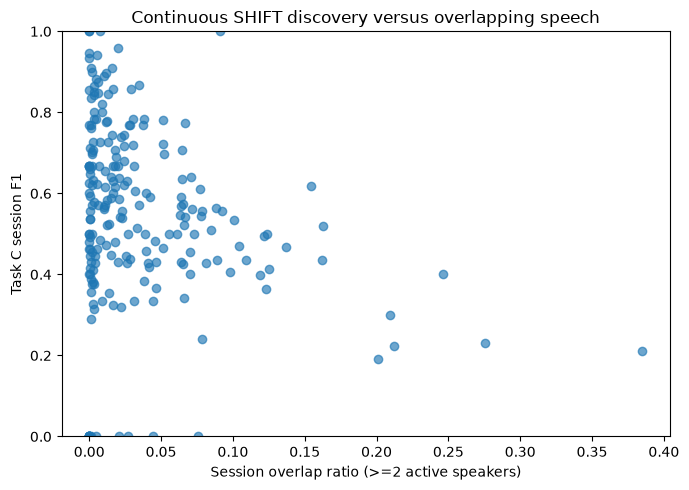

In [15]:
# Task C versus overlapping speech
valid = SESSION_ANALYSIS[
    (pd.to_numeric(SESSION_ANALYSIS["n_speakers"], errors="coerce") >= 2)
    & np.isfinite(pd.to_numeric(SESSION_ANALYSIS["overlap_ratio"], errors="coerce"))
].copy()

print(
    "Overlap analysis sessions:",
    len(valid),
    "| excluded <2-speaker sessions:",
    int(len(SESSION_ANALYSIS) - len(valid)),
)

if len(valid) >= 3:
    q1, q2 = valid["overlap_ratio"].quantile([1/3, 2/3]).tolist()
    def overlap_bucket(x):
        if x <= q1: return "low"
        if x <= q2: return "medium"
        return "high"
    valid["overlap_bucket"] = valid["overlap_ratio"].map(overlap_bucket)
else:
    q1 = q2 = np.nan
    valid["overlap_bucket"] = "all"

rows = []
for bucket, g in valid.groupby("overlap_bucket", sort=False):
    rows.append({
        "overlap_bucket": bucket,
        "sessions": int(len(g)),
        "mean_overlap_ratio": float(g["overlap_ratio"].mean()),
        "median_overlap_ratio": float(g["overlap_ratio"].median()),
        "mean_n_speakers": float(g["n_speakers"].mean()),
        **aggregate_count_metrics(g),
        **session_bootstrap_ci(g, BOOTSTRAP_REPLICATES, SEED + 50 + len(rows)),
    })

OVERLAP_PERFORMANCE = pd.DataFrame(rows)
OVERLAP_PERFORMANCE.to_csv(TABLE_DIR / "taskC_performance_by_overlap_level.csv", index=False)
display(OVERLAP_PERFORMANCE)

rho_o, p_o = safe_spearman(valid["overlap_ratio"], valid["F1"])
print({
    "spearman_rho_overlap_vs_session_f1": float(rho_o),
    "p_value": float(p_o),
    "tertile_boundaries": [float(q1), float(q2)] if np.isfinite(q1) else None,
})

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(valid["overlap_ratio"], valid["F1"], alpha=0.65)
ax.set_xlabel("Session overlap ratio (>=2 active speakers)")
ax.set_ylabel("Task C session F1")
ax.set_title("Continuous SHIFT discovery versus overlapping speech")
ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(FIG_DIR / "taskC_session_f1_vs_overlap.png", dpi=220, bbox_inches="tight")
plt.show()

,action,support,target_is_shift,predicted_shift_rate,correct_rate,interpretation_metric,action_success_rate
2,ITT,1431,True,0.838574,0.838574,SHIFT recall,0.838574
3,NTT,3700,True,0.864865,0.864865,SHIFT recall,0.864865
0,BC,106,False,0.716981,0.283019,HOLD rejection rate,0.283019
1,BI,215,False,0.655814,0.344186,HOLD rejection rate,0.344186
4,Other/unspecified,3703,False,0.113151,0.886849,HOLD rejection rate,0.886849


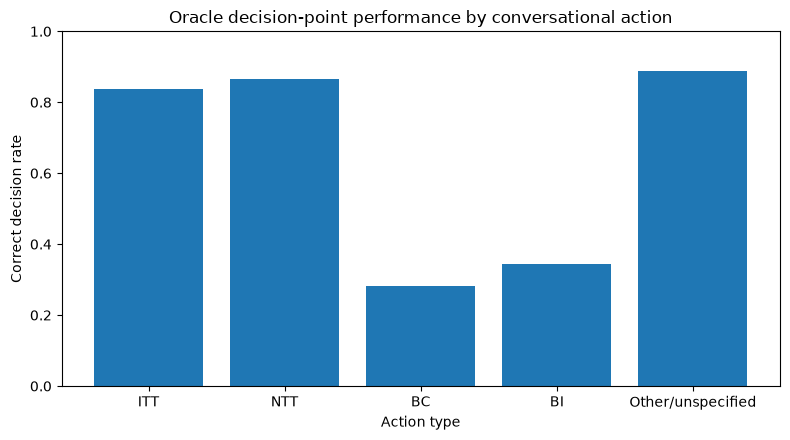

In [16]:
# Task A oracle action breakdown
rows = []
for action, g in B2.groupby("action", dropna=False):
    action_name = (
        "Other/unspecified"
        if pd.isna(action) or str(action).strip().lower() in {"nan", "none", ""}
        else str(action)
    )
    y = g["label"].to_numpy(int)
    yp = g["pred_label"].to_numpy(int)

    unique_targets = sorted(set(y.tolist()))
    if len(unique_targets) != 1:
        raise RuntimeError(
            f"Task-A action {action_name!r} maps to multiple labels: "
            f"{unique_targets}. The event contract should make each action "
            "unambiguously SHIFT or HOLD."
        )

    target_shift = int(unique_targets[0])
    pred_shift_rate = float(np.mean(yp == 1)) if len(yp) else np.nan

    rows.append({
        "action": action_name,
        "support": int(len(g)),
        "target_is_shift": bool(target_shift == 1),
        "predicted_shift_rate": pred_shift_rate,
        "correct_rate": float(np.mean(y == yp)) if len(y) else np.nan,
        "interpretation_metric": (
            "SHIFT recall" if target_shift == 1 else "HOLD rejection rate"
        ),
        "action_success_rate": (
            pred_shift_rate if target_shift == 1 else 1.0 - pred_shift_rate
        ),
    })

if not rows:
    raise RuntimeError("No Task-A action rows remain after filtering silent_100ms.")
TASKA_ACTION = pd.DataFrame(rows).sort_values(
    ["target_is_shift", "action"], ascending=[False, True]
)
TASKA_ACTION.to_csv(TABLE_DIR / "taskA_oracle_action_breakdown.csv", index=False)
display(TASKA_ACTION)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(TASKA_ACTION["action"], TASKA_ACTION["action_success_rate"])
ax.set_xlabel("Action type")
ax.set_ylabel("Correct decision rate")
ax.set_title("Oracle decision-point performance by conversational action")
ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(FIG_DIR / "taskA_action_success_rate.png", dpi=220, bbox_inches="tight")
plt.show()

,action,N_gt,TP,FN,recall,mean_gap_s,mean_overlap_s
0,ITT,1773,834,939,0.470389,-0.397445,0.397445
1,NTT,4575,2775,1800,0.606557,0.305025,0.002461


,fp_attribution,count,fraction_of_fp
0,background_or_other,2665,0.853619
1,near_NA,198,0.063421
2,near_NA_0p5_to_1p0,123,0.039398
3,near_BI,75,0.024023
4,near_BI_0p5_to_1p0,28,0.008969
5,near_BC,19,0.006086
6,near_BC_0p5_to_1p0,14,0.004484


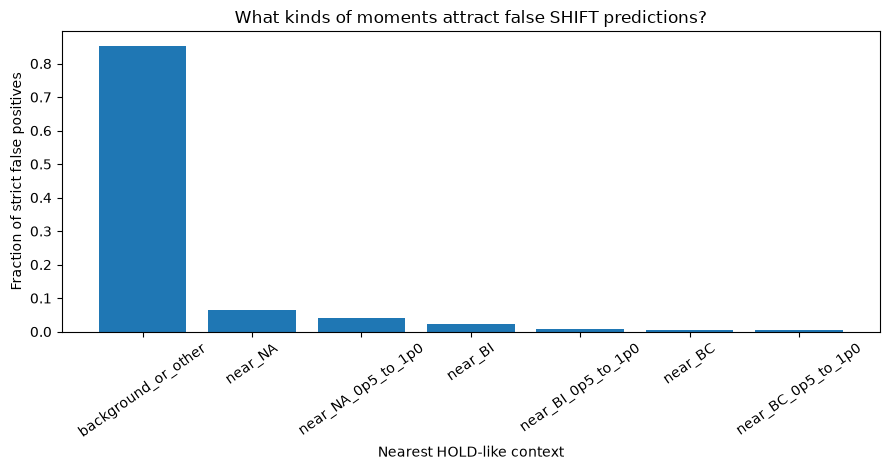

In [17]:
# Task C NTT/ITT recall + false-positive attribution
gt_shift = GT_SHIFT.copy().reset_index(drop=True)
gt_shift["_global_gt_index"] = np.arange(len(gt_shift))

pred_work = FINAL_PRED.copy().reset_index(drop=True)
pred_work["_global_pred_index"] = np.arange(len(pred_work))

matched_gt = set()
matched_pred = set()

for sid in sorted(set(gt_shift["session"]) | set(pred_work["session"])):
    gs = gt_shift[gt_shift["session"].eq(sid)].copy().reset_index()
    ps = pred_work[pred_work["session"].eq(sid)].copy().reset_index()
    pairs = canonical_match_indices(ps["time"].to_numpy(float), gs["time"].to_numpy(float), STRICT_TOL)
    for pi, gi, _ in pairs:
        matched_pred.add(int(ps.iloc[pi]["_global_pred_index"]))
        matched_gt.add(int(gs.iloc[gi]["_global_gt_index"]))

gt_shift["matched_strict"] = gt_shift["_global_gt_index"].isin(matched_gt)

rows = []
for action, g in gt_shift.groupby("action"):
    rows.append({
        "action": str(action),
        "N_gt": int(len(g)),
        "TP": int(g["matched_strict"].sum()),
        "FN": int((~g["matched_strict"]).sum()),
        "recall": float(g["matched_strict"].mean()) if len(g) else np.nan,
        "mean_gap_s": float(pd.to_numeric(g["gap"], errors="coerce").mean()) if "gap" in g.columns else np.nan,
        "mean_overlap_s": float(pd.to_numeric(g["overlap"], errors="coerce").mean()) if "overlap" in g.columns else np.nan,
    })

TASKC_SHIFT_ACTION = pd.DataFrame(rows)
TASKC_SHIFT_ACTION.to_csv(TABLE_DIR / "taskC_recall_by_shift_action.csv", index=False)
display(TASKC_SHIFT_ACTION)

hold = GT_EVENTS_ALL[GT_EVENTS_ALL["label"].eq(0)].copy()
unmatched = pred_work[~pred_work["_global_pred_index"].isin(matched_pred)].copy()

fp_rows = []
for r in unmatched.itertuples(index=False):
    h = hold[hold["session"].astype(str).eq(str(r.session))].copy()
    if len(h):
        ht = pd.to_numeric(h["time"], errors="coerce").to_numpy(float)
        valid_h = np.isfinite(ht)
        h = h.loc[valid_h].reset_index(drop=True)
        ht = ht[valid_h]
    if len(h):
        d = np.abs(ht - float(r.time))
        j = int(np.argmin(d))
        dist = float(d[j])
        action = str(h.iloc[j]["action"])
    else:
        dist, action = np.inf, "none"

    if dist <= 0.50:
        attr = f"near_{action}"
    elif dist <= 1.00:
        attr = f"near_{action}_0p5_to_1p0"
    else:
        attr = "background_or_other"

    fp_rows.append({
        "session": str(r.session),
        "pred_time": float(r.time),
        "nearest_hold_action": action,
        "nearest_hold_distance_s": dist,
        "fp_attribution": attr,
    })

TASKC_FP_ROWS = pd.DataFrame(
    fp_rows,
    columns=[
        "session", "pred_time", "nearest_hold_action",
        "nearest_hold_distance_s", "fp_attribution",
    ],
)
if len(TASKC_FP_ROWS):
    TASKC_FP_ATTRIBUTION = (
        TASKC_FP_ROWS["fp_attribution"].value_counts()
        .rename_axis("fp_attribution").reset_index(name="count")
    )
    TASKC_FP_ATTRIBUTION["fraction_of_fp"] = (
        TASKC_FP_ATTRIBUTION["count"]
        / max(1, TASKC_FP_ATTRIBUTION["count"].sum())
    )
else:
    TASKC_FP_ATTRIBUTION = pd.DataFrame(
        columns=["fp_attribution", "count", "fraction_of_fp"]
    )

TASKC_FP_ROWS.to_csv(TABLE_DIR / "taskC_false_positive_attribution_rows.csv", index=False)
TASKC_FP_ATTRIBUTION.to_csv(TABLE_DIR / "taskC_false_positive_attribution_summary.csv", index=False)
display(TASKC_FP_ATTRIBUTION)

if len(TASKC_FP_ATTRIBUTION):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    p = TASKC_FP_ATTRIBUTION.head(10)
    ax.bar(p["fp_attribution"], p["fraction_of_fp"])
    ax.set_xlabel("Nearest HOLD-like context")
    ax.set_ylabel("Fraction of strict false positives")
    ax.set_title("What kinds of moments attract false SHIFT predictions?")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    fig.savefig(
        FIG_DIR / "taskC_false_positive_attribution.png",
        dpi=220,
        bbox_inches="tight",
    )
    plt.show()
else:
    print("No strict false positives to attribute.")

In [18]:
# NTT gap and ITT overlap difficulty
rows = []

if "gap" in gt_shift.columns:
    ntt = gt_shift[gt_shift["action"].astype(str).eq("NTT")].copy()
    if len(ntt):
        ntt["value"] = pd.to_numeric(ntt["gap"], errors="coerce")
        ntt["timing_bin"] = pd.cut(
            ntt["value"],
            bins=[-np.inf, 0.10, 0.30, 0.50, 0.70, 1.00, np.inf],
            labels=["<=0.10", "0.10-0.30", "0.30-0.50", "0.50-0.70", "0.70-1.00", ">1.00"],
        )
        for b, g in ntt.groupby("timing_bin", observed=True):
            rows.append({"action": "NTT", "measure": "gap_s", "timing_bin": str(b),
                         "support": int(len(g)), "recall": float(g["matched_strict"].mean())})

if "overlap" in gt_shift.columns:
    itt = gt_shift[gt_shift["action"].astype(str).eq("ITT")].copy()
    if len(itt):
        itt["value"] = pd.to_numeric(itt["overlap"], errors="coerce")
        itt["timing_bin"] = pd.cut(
            itt["value"],
            bins=[-np.inf, 0.10, 0.25, 0.50, 1.00, 2.00, np.inf],
            labels=["<=0.10", "0.10-0.25", "0.25-0.50", "0.50-1.00", "1.00-2.00", ">2.00"],
        )
        for b, g in itt.groupby("timing_bin", observed=True):
            rows.append({"action": "ITT", "measure": "overlap_s", "timing_bin": str(b),
                         "support": int(len(g)), "recall": float(g["matched_strict"].mean())})

ACTION_TIMING_DIFFICULTY = pd.DataFrame(rows)
ACTION_TIMING_DIFFICULTY.to_csv(TABLE_DIR / "taskC_action_timing_difficulty.csv", index=False)
display(ACTION_TIMING_DIFFICULTY)

,action,measure,timing_bin,support,recall
0,NTT,gap_s,<=0.10,1492,0.623995
1,NTT,gap_s,0.10-0.30,1123,0.652716
2,NTT,gap_s,0.30-0.50,824,0.606796
3,NTT,gap_s,0.50-0.70,537,0.577281
4,NTT,gap_s,0.70-1.00,599,0.502504
5,ITT,overlap_s,<=0.10,207,0.531401
6,ITT,overlap_s,0.10-0.25,461,0.498915
7,ITT,overlap_s,0.25-0.50,522,0.482759
8,ITT,overlap_s,0.50-1.00,583,0.415094


,stage,F1,description
0,Oracle decision point,0.865545,SHIFT/HOLD at known RTTM decision point
1,Automatic candidate verifier,0.455280,Branch 2E on automatic System-1 candidates
2,Continuous dual-process,0.551877,Frozen final end-to-end SHIFT discovery


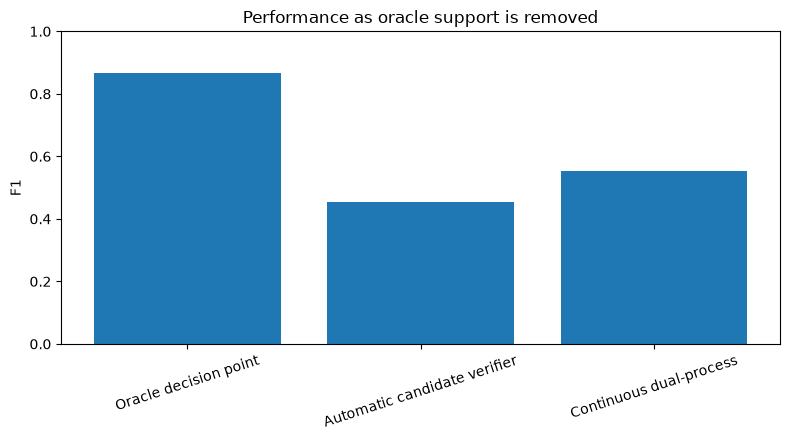

,stage,items,matched_gt,recall,items_per_min,candidate_retention_fraction
0,Ground-truth SHIFT events,6348,6348,1.000000,2.430165,NaN
1,System 1 candidates,80012,6092,0.959672,30.630489,1.000000
2,Final System 2 accepted events,6731,3609,0.568526,2.576786,0.084125


System 2 rejection fraction: 0.9159
Final recall / System-1 ceiling recall: 0.5924


,speaker_bucket,system1_candidate_recall,final_taskC_recall,recall_retained_after_system2,system1_candidates,system1_candidates_per_min
0,2,0.970032,0.623028,0.642276,8822,32.821243
1,3,0.939655,0.379310,0.403670,3040,28.926962
2,4,0.965969,0.628272,0.650407,4835,29.667333
3,5,0.967857,0.571429,0.590406,3217,29.825921
4,6+,0.958299,0.565560,0.590171,57553,30.859332


,candidate_class,n,mean_score,median_score
0,canonical_GT_match,6092,0.539396,0.575300
1,unmatched_candidate,73920,0.279085,0.240722


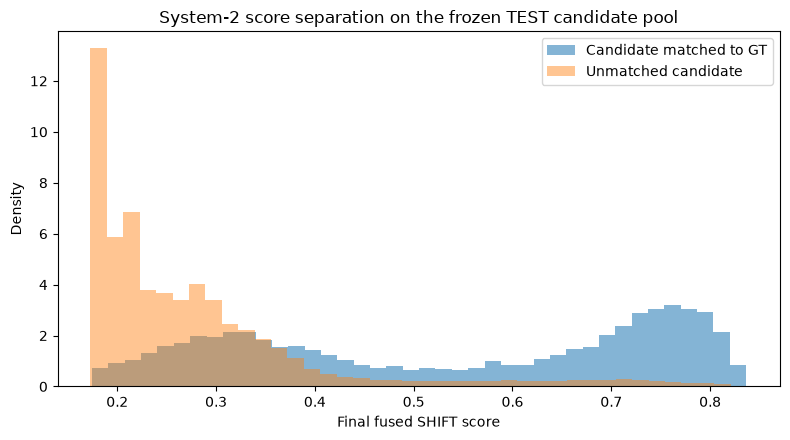

In [19]:
# Difficulty ladder + System 1 → System 2 funnel
def branch_row(name):
    g = CONSOLIDATED[CONSOLIDATED["branch"].astype(str).eq(name)]
    return g.iloc[0].to_dict() if len(g) else {}

b2 = branch_row("Branch 2")
b2e = branch_row("Branch 2E")
b1 = branch_row("Branch 1")

DIFFICULTY_LADDER = pd.DataFrame([
    {"stage": "Oracle decision point", "F1": float(b2.get("f1", np.nan)),
     "description": "SHIFT/HOLD at known RTTM decision point"},
    {"stage": "Automatic candidate verifier", "F1": float(b2e.get("f1", np.nan)),
     "description": "Branch 2E on automatic System-1 candidates"},
    {"stage": "Continuous dual-process", "F1": float(b1.get("f1", np.nan)),
     "description": "Frozen final end-to-end SHIFT discovery"},
])
DIFFICULTY_LADDER.to_csv(TABLE_DIR / "oracle_automatic_continuous_difficulty_ladder.csv", index=False)
display(DIFFICULTY_LADDER)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(DIFFICULTY_LADDER["stage"], DIFFICULTY_LADDER["F1"])
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
ax.set_title("Performance as oracle support is removed")
ax.tick_params(axis="x", rotation=18)
fig.tight_layout()
fig.savefig(FIG_DIR / "oracle_automatic_continuous_difficulty_ladder.png", dpi=220, bbox_inches="tight")
plt.show()

CAND = FINAL_FUSED_CANDIDATES[["session", "time", "fused_shift_score"]].copy()
CAND["session"] = CAND["session"].astype(str)
CAND["time"] = pd.to_numeric(CAND["time"], errors="coerce")
CAND = (
    CAND.dropna(subset=["session", "time"])
    .sort_values(["session", "time"])
    .drop_duplicates(["session", "time"])
    .reset_index(drop=True)
)

SYS1_METRICS, SYS1_PER_SESSION, _ = event_metrics(CAND, GT_SHIFT, STRICT_TOL)
total_minutes = float(SESSION_META["duration_min"].sum())

DUAL_PROCESS_FUNNEL = pd.DataFrame([
    {"stage": "Ground-truth SHIFT events", "items": len(GT_SHIFT),
     "matched_gt": len(GT_SHIFT), "recall": 1.0,
     "items_per_min": safe_div(len(GT_SHIFT), total_minutes)},
    {"stage": "System 1 candidates", "items": len(CAND),
     "matched_gt": SYS1_METRICS["TP"], "recall": SYS1_METRICS["R"],
     "items_per_min": safe_div(len(CAND), total_minutes)},
    {"stage": "Final System 2 accepted events", "items": len(FINAL_PRED),
     "matched_gt": STRICT_RECOMPUTED["TP"], "recall": STRICT_RECOMPUTED["R"],
     "items_per_min": safe_div(len(FINAL_PRED), total_minutes)},
])

DUAL_PROCESS_FUNNEL["candidate_retention_fraction"] = [
    np.nan, 1.0, safe_div(len(FINAL_PRED), len(CAND))
]

DUAL_PROCESS_FUNNEL.to_csv(TABLE_DIR / "dual_process_candidate_funnel.csv", index=False)
display(DUAL_PROCESS_FUNNEL)

print("System 2 rejection fraction:", round(1.0 - safe_div(len(FINAL_PRED), len(CAND)), 4))
print("Final recall / System-1 ceiling recall:",
      round(safe_div(STRICT_RECOMPUTED["R"], SYS1_METRICS["R"]), 4))

sys1_by_session = SYS1_PER_SESSION.merge(
    SESSION_META[["session", "n_speakers", "duration_min"]],
    on="session",
    how="left",
)
sys1_by_session["speaker_bucket"] = sys1_by_session["n_speakers"].map(speaker_bucket)

final_by_session = STRICT_PER_SESSION_RECOMPUTED.merge(
    SESSION_META[["session", "n_speakers", "duration_min"]],
    on="session",
    how="left",
)
final_by_session["speaker_bucket"] = final_by_session["n_speakers"].map(speaker_bucket)

stage_rows = []
for bucket in ["2", "3", "4", "5", "6+"]:
    g1 = sys1_by_session[sys1_by_session["speaker_bucket"].eq(bucket)]
    gf = final_by_session[final_by_session["speaker_bucket"].eq(bucket)]
    if len(g1) == 0 and len(gf) == 0:
        continue

    m1 = aggregate_count_metrics(g1) if len(g1) else {"R": np.nan}
    mf = aggregate_count_metrics(gf) if len(gf) else {"R": np.nan}

    n_cands = int(g1["N_pred"].sum()) if len(g1) else 0
    mins = float(
        SESSION_META[
            SESSION_META["n_speakers"].map(speaker_bucket).eq(bucket)
        ]["duration_min"].sum()
    )

    stage_rows.append({
        "speaker_bucket": bucket,
        "system1_candidate_recall": float(m1.get("R", np.nan)),
        "final_taskC_recall": float(mf.get("R", np.nan)),
        "recall_retained_after_system2": safe_div(
            mf.get("R", 0.0), m1.get("R", 0.0)
        ),
        "system1_candidates": n_cands,
        "system1_candidates_per_min": safe_div(n_cands, mins),
    })

SYSTEM_STAGE_BY_SPEAKER_COUNT = pd.DataFrame(stage_rows)
SYSTEM_STAGE_BY_SPEAKER_COUNT.to_csv(
    TABLE_DIR / "system1_system2_by_speaker_count.csv",
    index=False,
)
display(SYSTEM_STAGE_BY_SPEAKER_COUNT)

_, _, cand_matches = event_metrics(
    CAND[["session", "time"]],
    GT_SHIFT,
    STRICT_TOL,
    return_matches=True,
)

cand_diag = CAND.copy().reset_index(drop=True)
cand_diag["canonical_gt_match"] = False

for sid, g in cand_diag.groupby("session", sort=False):
    local = cand_matches[cand_matches["session"].astype(str).eq(str(sid))]
    if len(local):
        idx_global = g.index.to_numpy()
        valid_local = local["pred_local_index"].astype(int).to_numpy()
        valid_local = valid_local[(valid_local >= 0) & (valid_local < len(idx_global))]
        cand_diag.loc[idx_global[valid_local], "canonical_gt_match"] = True

score_pos = cand_diag.loc[cand_diag["canonical_gt_match"], "fused_shift_score"]
score_neg = cand_diag.loc[~cand_diag["canonical_gt_match"], "fused_shift_score"]

SYSTEM2_SCORE_DIAGNOSTIC = pd.DataFrame([
    {
        "candidate_class": "canonical_GT_match",
        "n": int(len(score_pos)),
        "mean_score": float(score_pos.mean()) if len(score_pos) else np.nan,
        "median_score": float(score_pos.median()) if len(score_pos) else np.nan,
    },
    {
        "candidate_class": "unmatched_candidate",
        "n": int(len(score_neg)),
        "mean_score": float(score_neg.mean()) if len(score_neg) else np.nan,
        "median_score": float(score_neg.median()) if len(score_neg) else np.nan,
    },
])
SYSTEM2_SCORE_DIAGNOSTIC.to_csv(
    TABLE_DIR / "system2_fused_score_candidate_diagnostic.csv",
    index=False,
)
display(SYSTEM2_SCORE_DIAGNOSTIC)

fig, ax = plt.subplots(figsize=(8, 4.5))
if len(score_pos):
    ax.hist(score_pos, bins=40, density=True, alpha=0.55, label="Candidate matched to GT")
if len(score_neg):
    ax.hist(score_neg, bins=40, density=True, alpha=0.45, label="Unmatched candidate")
ax.set_xlabel("Final fused SHIFT score")
ax.set_ylabel("Density")
ax.set_title("System-2 score separation on the frozen TEST candidate pool")
ax.legend()
fig.tight_layout()
fig.savefig(
    FIG_DIR / "system2_fused_score_matched_vs_unmatched.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

,stage,point_F1,bootstrap_mean_F1,F1_lower_95,F1_upper_95,bootstrap_source
0,Oracle decision point,0.865545,0.865710,0.854162,0.876784,analysis_session_bootstrap
1,Automatic candidate verifier,0.455280,0.455722,0.433552,0.477901,analysis_session_bootstrap
2,Continuous dual-process,0.551877,0.551551,0.529786,0.572728,original_saved_branch1_bootstrap


Primary strict Task-C 95% CI: {'mean': 0.5515505404541229, 'lower_95': 0.529786095187694, 'upper_95': 0.5727277202643507}
Oracle-minus-continuous descriptive gap:
{
  "common_sessions": 223,
  "mean_gap": 0.3133858855274188,
  "lower_95": 0.2944449136939878,
  "upper_95": 0.33073956170509705,
  "prob_gap_gt_0": 1.0,
  "interpretation": "Descriptive paired-session bootstrap only; Oracle Task A and continuous Task C are different evaluation problems."
}


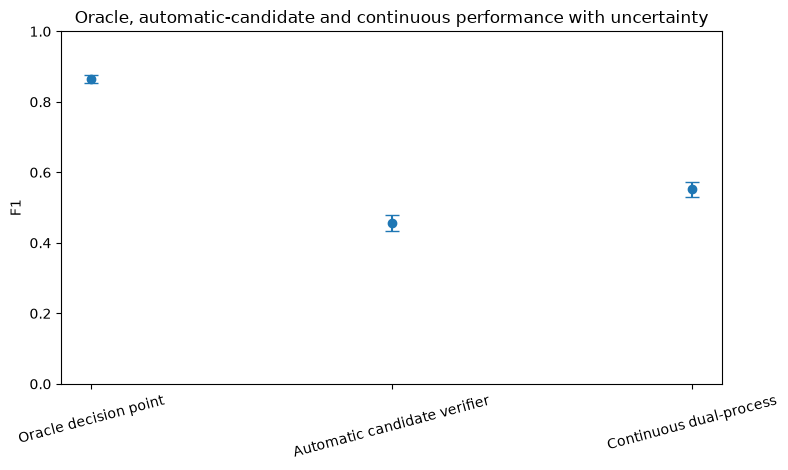

In [20]:
# Headline uncertainty: primary CI + oracle/continuous gap
def _normalise_saved_bootstrap(payload):
    out = {}
    if not isinstance(payload, dict):
        return out
    for metric in ["P", "R", "F1"]:
        obj = payload.get(metric, {})
        if isinstance(obj, dict):
            try:
                out[metric] = {
                    "mean": float(obj.get("mean")),
                    "lower_95": float(obj.get("lower_95")),
                    "upper_95": float(obj.get("upper_95")),
                }
            except Exception:
                pass
    return out

PRIMARY_BOOTSTRAP_SOURCE = "recomputed_from_current_per_session"
PRIMARY_BOOTSTRAP = {}

strict_bootstrap_path = OPTIONAL_ARTIFACTS["strict bootstrap"]
if strict_bootstrap_path.exists():
    try:
        payload = json.loads(strict_bootstrap_path.read_text())
        PRIMARY_BOOTSTRAP = _normalise_saved_bootstrap(payload)
        if PRIMARY_BOOTSTRAP:
            PRIMARY_BOOTSTRAP_SOURCE = "original_saved_branch1_bootstrap"
    except Exception as exc:
        print("Saved primary bootstrap could not be parsed:", repr(exc))

if not PRIMARY_BOOTSTRAP:
    _, _summary = bootstrap_count_metrics(
        STRICT_PER_SESSION_RECOMPUTED,
        reps=BOOTSTRAP_REPLICATES,
        seed=SEED + 1200,
    )
    PRIMARY_BOOTSTRAP = {
        k: _summary[k] for k in ["P", "R", "F1"] if k in _summary
    }

taska_session_rows = []
for sid, g in B2.groupby("session"):
    y = g["label"].to_numpy(int)
    yp = g["pred_label"].to_numpy(int)
    taska_session_rows.append({
        "session": str(sid),
        "TP": int(np.sum((y == 1) & (yp == 1))),
        "FP": int(np.sum((y == 0) & (yp == 1))),
        "FN": int(np.sum((y == 1) & (yp == 0))),
    })

TASKA_SESSION_COUNTS = pd.DataFrame(taska_session_rows)
TASKA_BOOT_REPS, TASKA_BOOTSTRAP = bootstrap_count_metrics(
    TASKA_SESSION_COUNTS,
    reps=BOOTSTRAP_REPLICATES,
    seed=SEED + 1210,
)

BRANCH2E_BOOTSTRAP = {}
b2e_ps_path = OPTIONAL_ARTIFACTS["Branch 2E per-session metrics"]
if b2e_ps_path.exists():
    try:
        b2e_ps = pd.read_csv(b2e_ps_path)
        if "tol" in b2e_ps.columns:
            tol_vals = pd.to_numeric(b2e_ps["tol"], errors="coerce")
            x = b2e_ps[np.isclose(tol_vals, STRICT_TOL)].copy()
            if len(x):
                b2e_ps = x
        elif "tolerance_label" in b2e_ps.columns:
            x = b2e_ps[
                b2e_ps["tolerance_label"].astype(str).str.contains("0p50|0.50", regex=True)
            ].copy()
            if len(x):
                b2e_ps = x

        require_columns(b2e_ps, {"session", "TP", "FP", "FN"}, "Branch 2E per-session metrics")
        b2e_counts = (
            b2e_ps[["session", "TP", "FP", "FN"]]
            .groupby("session", as_index=False)
            .sum()
        )
        _, BRANCH2E_BOOTSTRAP = bootstrap_count_metrics(
            b2e_counts,
            reps=BOOTSTRAP_REPLICATES,
            seed=SEED + 1220,
        )
    except Exception as exc:
        print("Branch 2E CI unavailable:", repr(exc))

common = TASKA_SESSION_COUNTS.merge(
    STRICT_PER_SESSION_RECOMPUTED[["session", "TP", "FP", "FN"]],
    on="session",
    suffixes=("_oracle", "_continuous"),
    how="inner",
)

rng_gap = np.random.default_rng(SEED + 1230)
gap_rows = []
if len(common):
    for rep in range(int(BOOTSTRAP_REPLICATES)):
        idx_boot = rng_gap.integers(0, len(common), size=len(common))
        g = common.iloc[idx_boot]

        oracle = prf_from_counts(
            int(g["TP_oracle"].sum()),
            int(g["FP_oracle"].sum()),
            int(g["FN_oracle"].sum()),
        )
        continuous = prf_from_counts(
            int(g["TP_continuous"].sum()),
            int(g["FP_continuous"].sum()),
            int(g["FN_continuous"].sum()),
        )

        gap_rows.append({
            "replicate": rep,
            "oracle_F1": oracle["F1"],
            "continuous_F1": continuous["F1"],
            "F1_gap_oracle_minus_continuous": oracle["F1"] - continuous["F1"],
        })

ORACLE_CONTINUOUS_GAP_BOOTSTRAP = pd.DataFrame(gap_rows)
if len(ORACLE_CONTINUOUS_GAP_BOOTSTRAP):
    gap_vals = ORACLE_CONTINUOUS_GAP_BOOTSTRAP[
        "F1_gap_oracle_minus_continuous"
    ].to_numpy(float)
    ORACLE_CONTINUOUS_GAP_SUMMARY = {
        "common_sessions": int(len(common)),
        "mean_gap": float(np.mean(gap_vals)),
        "lower_95": float(np.quantile(gap_vals, 0.025)),
        "upper_95": float(np.quantile(gap_vals, 0.975)),
        "prob_gap_gt_0": float(np.mean(gap_vals > 0)),
        "interpretation": (
            "Descriptive paired-session bootstrap only; Oracle Task A and "
            "continuous Task C are different evaluation problems."
        ),
    }
else:
    ORACLE_CONTINUOUS_GAP_SUMMARY = {}

ORACLE_CONTINUOUS_GAP_BOOTSTRAP.to_csv(
    TABLE_DIR / "oracle_continuous_gap_bootstrap_replicates.csv",
    index=False,
)
pd.DataFrame([ORACLE_CONTINUOUS_GAP_SUMMARY]).to_csv(
    TABLE_DIR / "oracle_continuous_gap_bootstrap_summary.csv",
    index=False,
)

def _ci_row(stage, point_f1, summary, source):
    f = summary.get("F1", {}) if isinstance(summary, dict) else {}
    return {
        "stage": stage,
        "point_F1": float(point_f1),
        "bootstrap_mean_F1": float(f.get("mean", np.nan)),
        "F1_lower_95": float(f.get("lower_95", np.nan)),
        "F1_upper_95": float(f.get("upper_95", np.nan)),
        "bootstrap_source": source,
    }

HEADLINE_UNCERTAINTY = pd.DataFrame([
    _ci_row(
        "Oracle decision point",
        float(b2.get("f1", np.nan)),
        TASKA_BOOTSTRAP,
        "analysis_session_bootstrap",
    ),
    _ci_row(
        "Automatic candidate verifier",
        float(b2e.get("f1", np.nan)),
        BRANCH2E_BOOTSTRAP,
        "analysis_session_bootstrap" if BRANCH2E_BOOTSTRAP else "CI_not_available",
    ),
    _ci_row(
        "Continuous dual-process",
        float(b1.get("f1", np.nan)),
        PRIMARY_BOOTSTRAP,
        PRIMARY_BOOTSTRAP_SOURCE,
    ),
])

HEADLINE_UNCERTAINTY.to_csv(
    TABLE_DIR / "headline_oracle_automatic_continuous_uncertainty.csv",
    index=False,
)
display(HEADLINE_UNCERTAINTY)

print("Primary strict Task-C 95% CI:", PRIMARY_BOOTSTRAP.get("F1", {}))
print("Oracle-minus-continuous descriptive gap:")
print(json.dumps(ORACLE_CONTINUOUS_GAP_SUMMARY, indent=2))

fig, ax = plt.subplots(figsize=(8, 4.8))
plot = HEADLINE_UNCERTAINTY.copy()
y = plot["point_F1"].to_numpy(float)
lo = plot["F1_lower_95"].to_numpy(float)
hi = plot["F1_upper_95"].to_numpy(float)
err_lo = np.where(np.isfinite(lo), y - lo, 0.0)
err_hi = np.where(np.isfinite(hi), hi - y, 0.0)
x = np.arange(len(plot))

ax.errorbar(
    x,
    y,
    yerr=np.vstack([err_lo, err_hi]),
    fmt="o",
    capsize=5,
)
ax.set_xticks(x)
ax.set_xticklabels(plot["stage"], rotation=15)
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
ax.set_title("Oracle, automatic-candidate and continuous performance with uncertainty")
fig.tight_layout()
fig.savefig(
    FIG_DIR / "headline_oracle_automatic_continuous_with_ci.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

In [21]:
# Dual-process workload proxy
WORKLOAD_PROXY = pd.DataFrame([
    {"quantity": "TEST conversation minutes", "value": total_minutes, "unit": "minutes"},
    {"quantity": "System-1 candidates", "value": len(CAND), "unit": "events"},
    {"quantity": "System-2 candidate workload",
     "value": safe_div(len(CAND), total_minutes), "unit": "candidate evaluations/min"},
    {"quantity": "Final accepted events", "value": len(FINAL_PRED), "unit": "events"},
    {"quantity": "Final accepted event rate",
     "value": safe_div(len(FINAL_PRED), total_minutes), "unit": "events/min"},
    {"quantity": "System-2 rejection fraction",
     "value": 1.0 - safe_div(len(FINAL_PRED), len(CAND)), "unit": "fraction"},
])
WORKLOAD_PROXY.to_csv(TABLE_DIR / "dual_process_workload_proxy.csv", index=False)
display(WORKLOAD_PROXY)

print(
    "NOTE: the supplied artefact tree does not contain trustworthy per-component "
    "inference wall-clock timings. These are workload counts, not measured latency or RTF."
)

,quantity,value,unit
0,TEST conversation minutes,2612.168533,minutes
1,System-1 candidates,80012.000000,events
2,System-2 candidate workload,30.630489,candidate evaluations/min
3,Final accepted events,6731.000000,events
4,Final accepted event rate,2.576786,events/min
5,System-2 rejection fraction,0.915875,fraction


NOTE: the supplied artefact tree does not contain trustworthy per-component inference wall-clock timings. These are workload counts, not measured latency or RTF.


,condition,P,R,F1,TP,FP,FN,N_pred,N_gt,provenance
0,no_aug,0.567128,0.516383,0.540567,3278.0,2502.0,3070.0,5780.0,6348.0,campaign_results_csv
1,synthetic_only,0.543354,0.555766,0.549490,3528.0,2965.0,2820.0,6493.0,6348.0,campaign_results_csv
2,diffusion_only,0.617334,0.483617,0.542355,3070.0,1903.0,3278.0,4973.0,6348.0,campaign_results_csv
3,full,0.536176,0.568526,0.551877,3609.0,3122.0,2739.0,6731.0,6348.0,campaign_results_csv


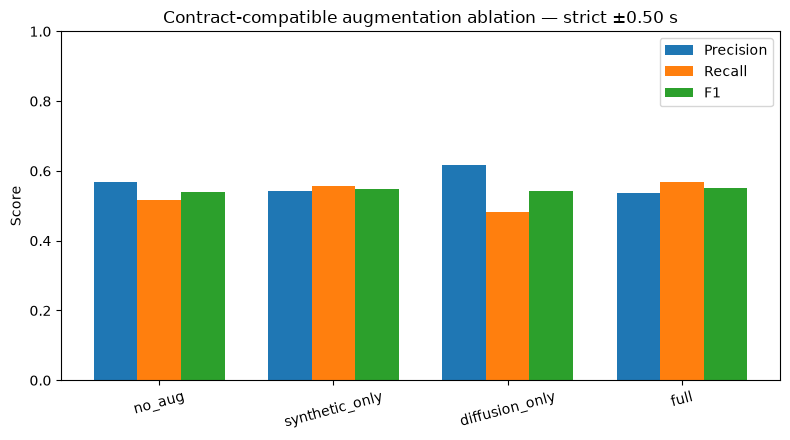

✅ All four augmentation conditions are available for paper analysis.


In [22]:
# Contract-compatible augmentation results
EVENT_CONTRACT_VERSION = "voxconverse_action_aware_immediate_v1"

CAMPAIGN_EMBEDDED_RESULTS = pd.DataFrame([
    {
        "condition": "no_aug",
        "status": "complete",
        "contract_compatible": True,
        "use_synthetic": False,
        "use_diffusion": False,
        "P": 0.5671280276816609,
        "R": 0.5163831127914303,
        "F1": 0.5405672823218997,
        "TP": 3278,
        "FP": 2502,
        "FN": 3070,
        "N_pred": 5780,
        "N_gt": 6348,
        "full_reference_reused": False,
    },
    {
        "condition": "synthetic_only",
        "status": "complete",
        "contract_compatible": True,
        "use_synthetic": True,
        "use_diffusion": False,
        "P": 0.5433543816417681,
        "R": 0.555765595463138,
        "F1": 0.5494899151156452,
        "TP": 3528,
        "FP": 2965,
        "FN": 2820,
        "N_pred": 6493,
        "N_gt": 6348,
        "full_reference_reused": False,
    },
    {
        "condition": "diffusion_only",
        "status": "complete",
        "contract_compatible": True,
        "use_synthetic": False,
        "use_diffusion": True,
        "P": 0.6173336014478182,
        "R": 0.4836168872085696,
        "F1": 0.5423549156434944,
        "TP": 3070,
        "FP": 1903,
        "FN": 3278,
        "N_pred": 4973,
        "N_gt": 6348,
        "full_reference_reused": False,
    },
    {
        "condition": "full",
        "status": "complete",
        "contract_compatible": True,
        "use_synthetic": True,
        "use_diffusion": True,
        "P": 0.5361759025404843,
        "R": 0.5685255198487713,
        "F1": 0.551877054820705,
        "TP": 3609,
        "FP": 3122,
        "FN": 2739,
        "N_pred": 6731,
        "N_gt": 6348,
        "full_reference_reused": True,
    },
])

CAMPAIGN_EMBEDDED_RESULTS["event_contract_version"] = EVENT_CONTRACT_VERSION
CAMPAIGN_EMBEDDED_RESULTS["provenance"] = "executed_campaign_notebook_embedded"

def read_condition_metrics(condition, run_root):
    run_root = Path(run_root)
    completion = run_root / "augmentation_ablation_condition_complete.json"
    metric_csv = run_root / "eval" / "final_test_metrics.csv"
    per_session_csv = run_root / "eval" / "final_test_metrics_per_session.csv"
    run_card = run_root / "run_card.json"

    main_full = (
        condition == "full"
        and run_root.resolve() == RUN_ROOT.resolve()
        and metric_csv.exists()
    )

    if not completion.exists() and not main_full:
        return {
            "condition": condition,
            "status": "missing",
            "run_root": str(run_root),
            "per_session_path": str(per_session_csv),
            "per_session_available": per_session_csv.exists(),
        }

    if not metric_csv.exists():
        return {
            "condition": condition,
            "status": "metrics_missing",
            "run_root": str(run_root),
            "per_session_path": str(per_session_csv),
            "per_session_available": per_session_csv.exists(),
        }

    m = pd.read_csv(metric_csv)
    if "tol" in m.columns:
        strict = m[
            np.isclose(
                pd.to_numeric(m["tol"], errors="coerce"),
                STRICT_TOL,
            )
        ].copy()
        if len(strict):
            m = strict

    r = m.iloc[0].to_dict()
    contract = None

    if completion.exists():
        try:
            c = json.loads(completion.read_text())
            contract = c.get(
                "event_contract_version",
                c.get("contract"),
            )
        except Exception:
            pass

    if contract is None and run_card.exists():
        try:
            rc = json.loads(run_card.read_text())
            contract = (
                rc.get("event_contract", {})
                .get("event_contract_version")
            )
        except Exception:
            pass

    return {
        "condition": condition,
        "status": "complete",
        "contract_compatible": (
            contract in {None, EVENT_CONTRACT_VERSION}
        ),
        "run_root": str(run_root),
        "event_contract_version": contract,
        "P": float(r.get("P", r.get("precision", np.nan))),
        "R": float(r.get("R", r.get("recall", np.nan))),
        "F1": float(r.get("F1", r.get("f1", np.nan))),
        "TP": int(r.get("TP", r.get("tp", 0))),
        "FP": int(r.get("FP", r.get("fp", 0))),
        "FN": int(r.get("FN", r.get("fn", 0))),
        "N_pred": int(r.get("N_pred", 0)),
        "N_gt": int(r.get("N_gt", 0)),
        "per_session_path": str(per_session_csv),
        "per_session_available": per_session_csv.exists(),
        "provenance": "individual_condition_run",
    }

if AUG_CAMPAIGN_RESULTS_CSV.exists():
    AUGMENTATION_SUMMARY = pd.read_csv(AUG_CAMPAIGN_RESULTS_CSV)

    if "contract_compatible" in AUGMENTATION_SUMMARY.columns:
        AUGMENTATION_SUMMARY["contract_compatible"] = parse_bool_series(
            AUGMENTATION_SUMMARY["contract_compatible"]
        )

    AUGMENTATION_SUMMARY["event_contract_version"] = EVENT_CONTRACT_VERSION
    AUGMENTATION_SUMMARY["provenance"] = "campaign_results_csv"

else:
    discovered = pd.DataFrame([
        read_condition_metrics(c, p)
        for c, p in AUGMENTATION_RUNS.items()
    ])

    rows = []
    for condition in ["no_aug", "synthetic_only", "diffusion_only", "full"]:
        d = discovered[
            discovered["condition"].astype(str).eq(condition)
        ]

        usable = (
            len(d)
            and str(d.iloc[0].get("status", "")) == "complete"
            and bool(d.iloc[0].get("contract_compatible", True))
        )

        if usable:
            row = d.iloc[0].to_dict()
        else:
            row = (
                CAMPAIGN_EMBEDDED_RESULTS[
                    CAMPAIGN_EMBEDDED_RESULTS["condition"].eq(condition)
                ]
                .iloc[0]
                .to_dict()
            )

            run_root = AUGMENTATION_RUNS[condition]
            per_session_csv = (
                run_root / "eval" / "final_test_metrics_per_session.csv"
            )
            row["run_root"] = str(run_root)
            row["per_session_path"] = str(per_session_csv)
            row["per_session_available"] = per_session_csv.exists()

        rows.append(row)

    AUGMENTATION_SUMMARY = pd.DataFrame(rows)

if "contract_compatible" in AUGMENTATION_SUMMARY.columns:
    if not parse_bool_series(AUGMENTATION_SUMMARY["contract_compatible"]).all():
        raise RuntimeError(
            "At least one augmentation condition is not contract-compatible."
        )

expected_conditions = {
    "no_aug",
    "synthetic_only",
    "diffusion_only",
    "full",
}

if set(AUGMENTATION_SUMMARY["condition"].astype(str)) != expected_conditions:
    raise RuntimeError(
        "Augmentation summary does not contain exactly the four expected conditions."
    )

AUGMENTATION_SUMMARY = (
    AUGMENTATION_SUMMARY
    .set_index("condition")
    .loc[["no_aug", "synthetic_only", "diffusion_only", "full"]]
    .reset_index()
)

AUGMENTATION_SUMMARY.to_csv(
    TABLE_DIR / "augmentation_condition_readiness_and_metrics.csv",
    index=False,
)

display(
    AUGMENTATION_SUMMARY[
        [
            "condition",
            "P",
            "R",
            "F1",
            "TP",
            "FP",
            "FN",
            "N_pred",
            "N_gt",
            "provenance",
        ]
    ]
)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(AUGMENTATION_SUMMARY))
w = 0.25

ax.bar(
    x - w,
    AUGMENTATION_SUMMARY["P"],
    width=w,
    label="Precision",
)
ax.bar(
    x,
    AUGMENTATION_SUMMARY["R"],
    width=w,
    label="Recall",
)
ax.bar(
    x + w,
    AUGMENTATION_SUMMARY["F1"],
    width=w,
    label="F1",
)

ax.set_xticks(x)
ax.set_xticklabels(
    AUGMENTATION_SUMMARY["condition"],
    rotation=15,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title(
    "Contract-compatible augmentation ablation — strict ±0.50 s"
)
ax.legend()

fig.tight_layout()
fig.savefig(
    FIG_DIR / "augmentation_precision_recall_f1.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

print("✅ All four augmentation conditions are available for paper analysis.")

In [23]:
# Paired session bootstrap for augmentation deltas
CAMPAIGN_EMBEDDED_BOOTSTRAP = pd.DataFrame([
    {
        "condition": "diffusion_only",
        "baseline": "no_aug",
        "delta_P_mean": 0.050064281564349666,
        "delta_P_lower95": 0.03713987843552963,
        "delta_P_upper95": 0.06483081234975799,
        "prob_delta_P_gt_0": 1.0,
        "delta_R_mean": -0.032954693696392826,
        "delta_R_lower95": -0.04555529434719606,
        "delta_R_upper95": -0.020090074975324234,
        "prob_delta_R_gt_0": 0.0,
        "delta_F1_mean": 0.0014837107652153683,
        "delta_F1_lower95": -0.008623091119400147,
        "delta_F1_upper95": 0.012810256388851601,
        "prob_delta_F1_gt_0": 0.609,
    },
    {
        "condition": "full",
        "baseline": "no_aug",
        "delta_P_mean": -0.03209665685479474,
        "delta_P_lower95": -0.04664222782940293,
        "delta_P_upper95": -0.01775284395125151,
        "prob_delta_P_gt_0": 0.0,
        "delta_R_mean": 0.05204929412182627,
        "delta_R_lower95": 0.03375382168187638,
        "delta_R_upper95": 0.07042708705440123,
        "prob_delta_R_gt_0": 1.0,
        "delta_F1_mean": 0.01090495622015443,
        "delta_F1_lower95": -0.0015636038104459293,
        "delta_F1_upper95": 0.023218513357706593,
        "prob_delta_F1_gt_0": 0.9575,
    },
    {
        "condition": "synthetic_only",
        "baseline": "no_aug",
        "delta_P_mean": -0.026369476389342627,
        "delta_P_lower95": -0.039880165823484866,
        "delta_P_upper95": -0.013184856148044934,
        "prob_delta_P_gt_0": 0.0,
        "delta_R_mean": 0.03915797179931724,
        "delta_R_lower95": 0.01913751893433122,
        "delta_R_upper95": 0.0589344715231442,
        "prob_delta_R_gt_0": 1.0,
        "delta_F1_mean": 0.007684124405765572,
        "delta_F1_lower95": -0.005010631168172283,
        "delta_F1_upper95": 0.020306530438713995,
        "prob_delta_F1_gt_0": 0.8855,
    },
])

CAMPAIGN_EMBEDDED_BOOTSTRAP["common_test_sessions"] = 214
CAMPAIGN_EMBEDDED_BOOTSTRAP["provenance"] = (
    "executed_campaign_notebook_embedded"
)

def load_strict_per_session(path):
    df = pd.read_csv(path)

    if "tol" in df.columns:
        x = df[
            np.isclose(
                pd.to_numeric(df["tol"], errors="coerce"),
                STRICT_TOL,
            )
        ].copy()
        if len(x):
            df = x

    if "tolerance_label" in df.columns:
        x = df[
            df["tolerance_label"].astype(str).eq("strict_0p50")
        ].copy()
        if len(x):
            df = x

    required = {"session", "TP", "FP", "FN"}
    if not required.issubset(df.columns):
        raise KeyError(
            f"Per-session table missing: {required - set(df.columns)}"
        )

    out = df[["session", "TP", "FP", "FN"]].copy()
    out["session"] = out["session"].astype(str)

    for c in ["TP", "FP", "FN"]:
        out[c] = (
            pd.to_numeric(out[c], errors="coerce")
            .fillna(0)
            .astype(int)
        )

    return (
        out.groupby("session", as_index=False)[["TP", "FP", "FN"]]
        .sum()
    )

def paired_bootstrap_all_conditions(
    per_session_paths,
    reps=2000,
    seed=7412026,
):
    tables = {
        condition: load_strict_per_session(path)
        for condition, path in per_session_paths.items()
    }

    common_sessions = sorted(
        set.intersection(
            *[
                set(df["session"].astype(str))
                for df in tables.values()
            ]
        )
    )

    if not common_sessions:
        raise RuntimeError("No common TEST sessions across conditions.")

    arrays = {}
    for condition, df in tables.items():
        arrays[condition] = (
            df[df["session"].isin(common_sessions)]
            .set_index("session")
            .loc[common_sessions, ["TP", "FP", "FN"]]
            .to_numpy(np.int64)
        )

    rng = np.random.default_rng(seed)
    rows = []
    n = len(common_sessions)

    for rep in range(int(reps)):
        idx = rng.integers(0, n, size=n)

        base_totals = arrays["no_aug"][idx].sum(axis=0)
        base = prf_from_counts(*map(int, base_totals))

        for condition in ["synthetic_only", "diffusion_only", "full"]:
            totals = arrays[condition][idx].sum(axis=0)
            m = prf_from_counts(*map(int, totals))

            rows.append({
                "replicate": rep,
                "condition": condition,
                "delta_P": m["P"] - base["P"],
                "delta_R": m["R"] - base["R"],
                "delta_F1": m["F1"] - base["F1"],
            })

    reps_df = pd.DataFrame(rows)
    summary = []

    for condition, g in reps_df.groupby("condition"):
        row = {
            "condition": condition,
            "baseline": "no_aug",
            "common_test_sessions": int(n),
            "provenance": "recomputed_from_condition_per_session_tables",
        }

        for metric in ["P", "R", "F1"]:
            vals = g[f"delta_{metric}"].to_numpy(float)
            row[f"delta_{metric}_mean"] = float(vals.mean())
            row[f"delta_{metric}_lower95"] = float(
                np.quantile(vals, 0.025)
            )
            row[f"delta_{metric}_upper95"] = float(
                np.quantile(vals, 0.975)
            )
            row[f"prob_delta_{metric}_gt_0"] = float(
                np.mean(vals > 0)
            )

        summary.append(row)

    return pd.DataFrame(summary), reps_df

if AUG_CAMPAIGN_BOOTSTRAP_CSV.exists():
    AUGMENTATION_PAIRED_BOOTSTRAP = pd.read_csv(
        AUG_CAMPAIGN_BOOTSTRAP_CSV
    )
    AUGMENTATION_PAIRED_BOOTSTRAP["common_test_sessions"] = 214
    AUGMENTATION_PAIRED_BOOTSTRAP["provenance"] = (
        "campaign_bootstrap_summary_csv"
    )

else:
    by_name = {
        r["condition"]: r
        for r in AUGMENTATION_SUMMARY.to_dict("records")
    }

    per_session_paths = {}
    for condition in [
        "no_aug",
        "synthetic_only",
        "diffusion_only",
        "full",
    ]:
        row = by_name.get(condition, {})
        path = Path(str(row.get("per_session_path", "")))
        if path.exists():
            per_session_paths[condition] = path

    if set(per_session_paths) == {
        "no_aug",
        "synthetic_only",
        "diffusion_only",
        "full",
    }:
        AUGMENTATION_PAIRED_BOOTSTRAP, AUGMENTATION_BOOTSTRAP_REPLICATES = (
            paired_bootstrap_all_conditions(
                per_session_paths,
                reps=BOOTSTRAP_REPLICATES,
                seed=7412026,
            )
        )

        AUGMENTATION_BOOTSTRAP_REPLICATES.to_csv(
            TABLE_DIR / "augmentation_paired_session_bootstrap_replicates.csv",
            index=False,
        )

    else:
        AUGMENTATION_PAIRED_BOOTSTRAP = (
            CAMPAIGN_EMBEDDED_BOOTSTRAP.copy()
        )

AUGMENTATION_PAIRED_BOOTSTRAP.to_csv(
    TABLE_DIR / "augmentation_paired_session_bootstrap.csv",
    index=False,
)

display(AUGMENTATION_PAIRED_BOOTSTRAP)

print(
    "✅ Paired augmentation uncertainty is available for all three "
    "comparisons against no augmentation."
)
print(
    "Campaign paired bootstrap used 214 common TEST sessions."
)

,condition,baseline,delta_P_mean,delta_P_lower95,delta_P_upper95,prob_delta_P_gt_0,delta_R_mean,delta_R_lower95,delta_R_upper95,prob_delta_R_gt_0,delta_F1_mean,delta_F1_lower95,delta_F1_upper95,prob_delta_F1_gt_0,common_test_sessions,provenance
0,diffusion_only,no_aug,0.050064,0.037140,0.064831,1.0,-0.032955,-0.045555,-0.020090,0.0,0.001484,-0.008623,0.012810,0.6090,214,campaign_bootstrap_summary_csv
1,full,no_aug,-0.032097,-0.046642,-0.017753,0.0,0.052049,0.033754,0.070427,1.0,0.010905,-0.001564,0.023219,0.9575,214,campaign_bootstrap_summary_csv
2,synthetic_only,no_aug,-0.026369,-0.039880,-0.013185,0.0,0.039158,0.019138,0.058934,1.0,0.007684,-0.005011,0.020307,0.8855,214,campaign_bootstrap_summary_csv


✅ Paired augmentation uncertainty is available for all three comparisons against no augmentation.
Campaign paired bootstrap used 214 common TEST sessions.


In [24]:
rng = np.random.default_rng(SEED + 300)

shift_source = GT_SHIFT.copy()

hold_source = GT_EVENTS_ALL[GT_EVENTS_ALL["label"].eq(0)].copy()
hold_source["session"] = hold_source["session"].astype(str).map(
    lambda x: Path(str(x)).stem
)
hold_source["time"] = pd.to_numeric(hold_source["time"], errors="coerce")
hold_source = hold_source.dropna(subset=["session", "time"]).copy()
hold_source["_time_key"] = hold_source["time"].round(9)
hold_source["_action_key"] = hold_source["action"].astype(str)
hold_source = (
    hold_source
    .sort_values(["session", "_time_key", "_action_key"], kind="mergesort")
    .drop_duplicates(["session", "_time_key", "_action_key"], keep="first")
    .drop(columns=["_time_key", "_action_key"])
)

source = pd.concat([shift_source, hold_source], ignore_index=True, sort=False)

if "source_event_type" in source.columns:
    x = source[
        source["source_event_type"].astype(str).eq("adjacent_rttm_boundary")
    ].copy()
    if len(x):
        source = x

actions = [
    a for a in ["NTT", "ITT", "BC", "BI", "NA"]
    if a in set(source["action"].astype(str))
]
per_action = max(1, MANUAL_AUDIT_TOTAL // max(1, len(actions)))

samples = []
for action in actions:
    g = source[source["action"].astype(str).eq(action)].copy()
    n = min(per_action, len(g))
    if n:
        idx_sample = rng.choice(g.index.to_numpy(), size=n, replace=False)
        samples.append(g.loc[idx_sample])

AUDIT_SAMPLE = (
    pd.concat(samples, ignore_index=True)
    if samples
    else source.head(0).copy()
)

if len(AUDIT_SAMPLE) < min(MANUAL_AUDIT_TOTAL, len(source)):
    used = set(zip(
        AUDIT_SAMPLE["session"].astype(str),
        pd.to_numeric(AUDIT_SAMPLE["time"], errors="coerce").round(9),
        AUDIT_SAMPLE["action"].astype(str),
    ))

    keep = []
    for r in source.itertuples():
        key = (
            str(r.session),
            round(float(r.time), 9),
            str(r.action),
        )
        keep.append(key not in used)

    remainder = source[np.asarray(keep, dtype=bool)]
    need = min(MANUAL_AUDIT_TOTAL - len(AUDIT_SAMPLE), len(remainder))

    if need > 0:
        AUDIT_SAMPLE = pd.concat(
            [
                AUDIT_SAMPLE,
                remainder.sample(n=need, random_state=SEED + 1),
            ],
            ignore_index=True,
        )

AUDIT_SAMPLE = (
    AUDIT_SAMPLE
    .sort_values(["action", "session", "time"], kind="mergesort")
    .reset_index(drop=True)
)

AUDIT_SAMPLE["audit_row"] = np.arange(len(AUDIT_SAMPLE), dtype=int)
AUDIT_SAMPLE["audio_path"] = AUDIT_SAMPLE["session"].map(
    lambda s: str(AUDIO_FILES.get(str(s), ""))
)
AUDIT_SAMPLE["rttm_path"] = AUDIT_SAMPLE["session"].map(
    lambda s: str(RTTM_FILES.get(str(s), ""))
)

AUDIT_SAMPLE["human_valid_event"] = ""
AUDIT_SAMPLE["human_action"] = ""
AUDIT_SAMPLE["human_preferred_time_s"] = ""
AUDIT_SAMPLE["human_confidence_1_to_5"] = ""
AUDIT_SAMPLE["human_notes"] = ""

preferred = [
    "audit_row",
    "session",
    "time",
    "action",
    "label",
    "prev_speaker",
    "next_speaker",
    "gap",
    "overlap",
    "prev_dur",
    "next_dur",
    "time_floor_release",
    "time_floor_acquisition",
    "audio_path",
    "rttm_path",
    "human_valid_event",
    "human_action",
    "human_preferred_time_s",
    "human_confidence_1_to_5",
    "human_notes",
]
preferred = [c for c in preferred if c in AUDIT_SAMPLE.columns]

audit_path = AUDIT_DIR / "manual_event_label_audit_template.csv"
AUDIT_SAMPLE[preferred].to_csv(audit_path, index=False)

display(
    AUDIT_SAMPLE["action"]
    .value_counts()
    .rename("n")
    .reset_index()
)

print("Saved audit template:", audit_path)
print(
    "Human review is still required before making a label-validity claim."
)

,action,n
0,BC,60
1,BI,60
2,ITT,60
3,NA,60
4,NTT,60


Saved audit template: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/paper_analysis_voxconverse/manual_label_audit/manual_event_label_audit_template.csv
Human review is still required before making a label-validity claim.


In [25]:
# Audio snippets + persistent human-review CSV
snippet_dir = AUDIT_DIR / "audio_snippets"
snippet_dir.mkdir(parents=True, exist_ok=True)

manifest = []

if EXPORT_AUDIO_SNIPPETS:
    if sf is None:
        raise ImportError(
            "soundfile is required to export manual-audit snippets."
        )

    for _, row in AUDIT_SAMPLE.iterrows():
        audit_row = int(row["audit_row"])
        audio_path = Path(str(row.get("audio_path", "")))

        if not audio_path.exists():
            manifest.append({
                "audit_row": audit_row,
                "session": str(row["session"]),
                "action": str(row["action"]),
                "event_time_s": float(row["time"]),
                "error": "audio_path_missing",
            })
            continue

        try:
            info = sf.info(str(audio_path))
            sr = int(info.samplerate)
            t = float(row["time"])
            a = max(0.0, t - SNIPPET_BEFORE_S)
            b = min(float(info.frames) / sr, t + SNIPPET_AFTER_S)

            safe_action = str(row["action"]).replace("/", "_")
            name = (
                f"{audit_row:04d}_{row['session']}_{safe_action}_{t:.3f}.wav"
            )
            out_path = snippet_dir / name

            if not out_path.exists():
                audio, read_sr = sf.read(
                    str(audio_path),
                    start=int(round(a * sr)),
                    stop=int(round(b * sr)),
                    always_2d=False,
                )
                sf.write(str(out_path), audio, read_sr)

            manifest.append({
                "audit_row": audit_row,
                "session": str(row["session"]),
                "action": str(row["action"]),
                "event_time_s": t,
                "snippet_start_s": a,
                "snippet_end_s": b,
                "snippet_path": str(out_path),
            })

        except Exception as exc:
            manifest.append({
                "audit_row": audit_row,
                "session": str(row["session"]),
                "action": str(row["action"]),
                "event_time_s": float(row["time"]),
                "error": repr(exc),
            })

    AUDIT_SNIPPET_MANIFEST = pd.DataFrame(manifest)
    AUDIT_SNIPPET_MANIFEST.to_csv(
        AUDIT_DIR / "manual_event_audio_snippet_manifest.csv",
        index=False,
    )
    print(
        "Audio audit snippets available:",
        int(AUDIT_SNIPPET_MANIFEST["snippet_path"].notna().sum())
        if "snippet_path" in AUDIT_SNIPPET_MANIFEST.columns
        else 0,
    )
else:
    AUDIT_SNIPPET_MANIFEST = pd.DataFrame()
    print(
        "Audio snippet export skipped because VOX_EXPORT_AUDIT_AUDIO is disabled."
    )

template = pd.read_csv(audit_path)
if len(AUDIT_SNIPPET_MANIFEST) and "snippet_path" in AUDIT_SNIPPET_MANIFEST.columns:
    review_seed = template.merge(
        AUDIT_SNIPPET_MANIFEST[["audit_row", "snippet_path"]],
        on="audit_row",
        how="left",
    )
else:
    review_seed = template.copy()
    review_seed["snippet_path"] = ""

if not AUDIT_REVIEW_PATH.exists():
    review_seed.to_csv(AUDIT_REVIEW_PATH, index=False)
    print("Created human-review CSV:", AUDIT_REVIEW_PATH)
else:
    print(
        "Existing human-review CSV preserved:",
        AUDIT_REVIEW_PATH,
    )

instructions_path = AUDIT_DIR / "MANUAL_AUDIT_INSTRUCTIONS.txt"
instructions_path.write_text(
    "VoxConverse manual event-label audit\n"
    "=====================================\n\n"
    "For each row, listen to the corresponding snippet and inspect the RTTM "
    "context if needed.\n\n"
    "Fill these fields in manual_event_label_audit_review.csv:\n"
    "  human_valid_event: yes/no\n"
    "  human_action: NTT/ITT/BC/BI/NA/other\n"
    "  human_preferred_time_s: preferred event timestamp in ORIGINAL session seconds\n"
    "  human_confidence_1_to_5: 1-5\n"
    "  human_notes: optional\n\n"
    "Do not change the automatic action/time columns. Re-run the next notebook "
    "cell after reviewing rows; it will calculate the audit statistics.\n",
    encoding="utf-8",
)
print("Audit instructions:", instructions_path)

Audio audit snippets available: 300
Existing human-review CSV preserved: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/paper_analysis_voxconverse/manual_label_audit/manual_event_label_audit_review.csv
Audit instructions: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/paper_analysis_voxconverse/manual_label_audit/MANUAL_AUDIT_INSTRUCTIONS.txt


In [26]:
def _parse_yes_no(value):
    if pd.isna(value):
        return np.nan
    x = str(value).strip().lower()
    if x in {"yes", "y", "true", "1", "valid"}:
        return 1.0
    if x in {"no", "n", "false", "0", "invalid"}:
        return 0.0
    return np.nan

AUDIT_COMPLETED = False
AUDIT_REVIEWED_ROWS = 0
AUDIT_SUMMARY = {}

if AUDIT_REVIEW_PATH.exists():
    review = pd.read_csv(AUDIT_REVIEW_PATH)

    require_columns(
        review,
        {
            "audit_row",
            "session",
            "time",
            "action",
            "human_valid_event",
            "human_action",
            "human_preferred_time_s",
            "human_confidence_1_to_5",
        },
        "manual audit review",
    )

    review["_valid_numeric"] = review["human_valid_event"].map(_parse_yes_no)
    review["_human_action_clean"] = review["human_action"].astype(str).str.strip()
    review["_preferred_time"] = pd.to_numeric(
        review["human_preferred_time_s"], errors="coerce"
    )
    review["_confidence"] = pd.to_numeric(
        review["human_confidence_1_to_5"], errors="coerce"
    )

    reviewed_mask = review["_valid_numeric"].notna()
    AUDIT_REVIEWED_ROWS = int(reviewed_mask.sum())
    AUDIT_COMPLETED = bool(
        len(review) > 0
        and AUDIT_REVIEWED_ROWS == len(review)
    )

    reviewed = review[reviewed_mask].copy()

    if len(reviewed):
        n_valid = int(reviewed["_valid_numeric"].sum())
        validity_rate = float(n_valid / len(reviewed))
        valid_lo, valid_hi = wilson_interval(n_valid, len(reviewed))

        action_mask = (
            reviewed["_human_action_clean"].notna()
            & ~reviewed["_human_action_clean"].str.lower().isin(
                {"", "nan", "none"}
            )
        )
        action_rows = reviewed[action_mask].copy()
        if len(action_rows):
            action_agree = (
                action_rows["_human_action_clean"].str.upper()
                == action_rows["action"].astype(str).str.upper()
            )
            n_action_agree = int(action_agree.sum())
            action_agreement = float(action_agree.mean())
            action_lo, action_hi = wilson_interval(
                n_action_agree, len(action_rows)
            )
        else:
            action_agreement = action_lo = action_hi = np.nan

        time_rows = reviewed[
            reviewed["_preferred_time"].notna()
        ].copy()
        if len(time_rows):
            time_error = np.abs(
                time_rows["_preferred_time"].to_numpy(float)
                - pd.to_numeric(
                    time_rows["time"], errors="coerce"
                ).to_numpy(float)
            )
            median_abs_time_error = float(np.nanmedian(time_error))
            mean_abs_time_error = float(np.nanmean(time_error))
        else:
            median_abs_time_error = mean_abs_time_error = np.nan

        AUDIT_SUMMARY = {
            "total_sampled_rows": int(len(review)),
            "reviewed_rows": int(len(reviewed)),
            "review_complete": bool(AUDIT_COMPLETED),
            "valid_event_count": n_valid,
            "valid_event_rate": validity_rate,
            "valid_event_rate_lower_95": valid_lo,
            "valid_event_rate_upper_95": valid_hi,
            "action_rows_judged": int(len(action_rows)),
            "automatic_vs_human_action_agreement": action_agreement,
            "action_agreement_lower_95": action_lo,
            "action_agreement_upper_95": action_hi,
            "timing_rows_judged": int(len(time_rows)),
            "median_abs_timing_error_s": median_abs_time_error,
            "mean_abs_timing_error_s": mean_abs_time_error,
            "mean_human_confidence": float(
                reviewed["_confidence"].dropna().mean()
            ) if reviewed["_confidence"].notna().any() else np.nan,
        }

        pd.DataFrame([AUDIT_SUMMARY]).to_csv(
            TABLE_DIR / "manual_event_label_audit_summary.csv",
            index=False,
        )

        per_action_rows = []
        for action, g in reviewed.groupby("action", dropna=False):
            valid = g["_valid_numeric"].dropna()
            if len(valid):
                n_ok = int(valid.sum())
                lo, hi = wilson_interval(n_ok, len(valid))
                per_action_rows.append({
                    "action": str(action),
                    "reviewed": int(len(valid)),
                    "valid_count": n_ok,
                    "valid_rate": float(valid.mean()),
                    "valid_rate_lower_95": lo,
                    "valid_rate_upper_95": hi,
                })

        pd.DataFrame(per_action_rows).to_csv(
            TABLE_DIR / "manual_event_label_audit_by_action.csv",
            index=False,
        )

AUDIT_STATUS_PATH.write_text(
    json.dumps(
        {
            "review_csv": str(AUDIT_REVIEW_PATH),
            "reviewed_rows": int(AUDIT_REVIEWED_ROWS),
            "required_rows": int(len(AUDIT_SAMPLE)),
            "complete": bool(AUDIT_COMPLETED),
            "paper_label_validity_claim_allowed": bool(AUDIT_COMPLETED),
            "summary": AUDIT_SUMMARY,
        },
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

if AUDIT_COMPLETED:
    print("✅ Human manual event-label audit is complete.")
    display(pd.DataFrame([AUDIT_SUMMARY]))
else:
    print(
        "⚠️ Human manual event-label audit is PENDING:",
        f"{AUDIT_REVIEWED_ROWS}/{len(AUDIT_SAMPLE)} rows reviewed."
    )
    print(
        "Do not make a paper claim that the RTTM-derived labels were manually "
        "validated until this reaches 100%."
    )

⚠️ Human manual event-label audit is PENDING: 0/300 rows reviewed.
Do not make a paper claim that the RTTM-derived labels were manually validated until this reaches 100%.


,component,metric,value,unit
0,System1_WavLM_core,model_load_s,3.288208,s
1,System1_WavLM_core,audio_seconds_benchmarked,180.000000,audio_s
2,System1_WavLM_core,audio_io_s,0.057419,s
3,System1_WavLM_core,window_prepare_s,0.193355,s
4,System1_WavLM_core,model_forward_s,41.581550,s
5,System1_WavLM_core,peak_postprocess_s,0.001457,s
6,System1_WavLM_core,compute_RTF_excluding_model_load_and_IO,0.232091,RTF
7,System1_WavLM_core,RTF_including_audio_IO_excluding_model_load,0.232410,RTF
8,System1_WavLM_core,timeline_windows_scored,1803.000000,windows
9,System1_WavLM_core,low_threshold_local_peaks,171.000000,peaks


Timing status:
{
  "requested": true,
  "sys1_status": "measured",
  "sys2_status": "measured",
  "sys1_device": "cuda",
  "sys1_model_name": "microsoft/wavlm-large",
  "sys2_device": "cuda",
  "sys2_rows_benchmarked": 20000,
  "sys2_repeat_seconds": [
    0.2273034590180032,
    0.22572382201906294,
    0.2256280219880864
  ]
}


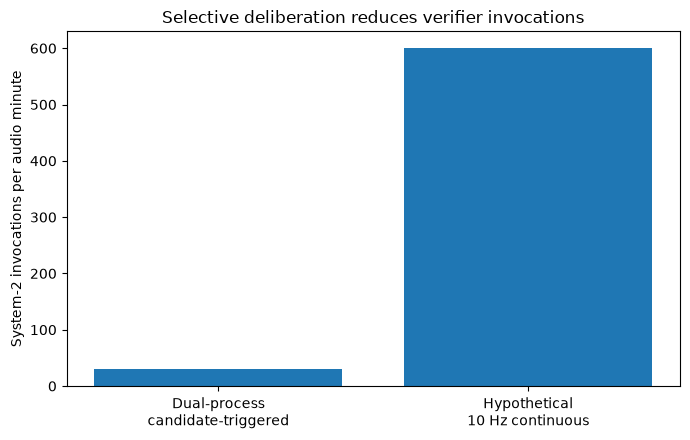

In [27]:
# True component timing benchmark
import time
import gc

TIMING_STATUS = {
    "requested": bool(RUN_TRUE_TIMING_BENCHMARK),
    "sys1_status": "not_run",
    "sys2_status": "not_run",
}

TIMING_ROWS = []

def _torch_load_compat(path, map_location):
    import torch
    try:
        return torch.load(
            path,
            map_location=map_location,
            weights_only=False,
        )
    except TypeError:
        return torch.load(path, map_location=map_location)

def _sync_device(device):
    import torch
    if str(device).startswith("cuda") and torch.cuda.is_available():
        torch.cuda.synchronize(device)

def _read_audio_for_timing(path, target_sr=16000, max_s=None):
    import soundfile as _sf
    from scipy.signal import resample_poly
    from math import gcd

    path = Path(path)
    info = _sf.info(str(path))
    src_sr = int(info.samplerate)

    if max_s is None:
        frames = -1
    else:
        frames = min(
            int(info.frames),
            int(math.ceil((float(max_s) + 3.0) * src_sr)),
        )

    x, sr = _sf.read(
        str(path),
        frames=frames,
        dtype="float32",
        always_2d=True,
    )
    x = x.mean(axis=1).astype(np.float32)

    if int(sr) != int(target_sr):
        g = gcd(int(sr), int(target_sr))
        x = resample_poly(
            x,
            int(target_sr) // g,
            int(sr) // g,
        ).astype(np.float32)
        sr = int(target_sr)

    return x, int(sr)

def _slice_or_pad_timing(x, center_s, total_s, sr):
    n = max(1, int(round(float(total_s) * int(sr))))
    start = int(round((float(center_s) - float(total_s) / 2.0) * int(sr)))
    stop = start + n

    out = np.zeros(n, dtype=np.float32)
    src_lo = max(0, start)
    src_hi = min(len(x), stop)

    if src_hi > src_lo:
        dst_lo = src_lo - start
        dst_hi = dst_lo + (src_hi - src_lo)
        out[dst_lo:dst_hi] = x[src_lo:src_hi]

    return out

def _local_peaks_timing(scores, keep_thr=0.03, radius=1):
    scores = np.asarray(scores, dtype=float)
    keep = scores >= float(keep_thr)
    peaks = []
    for i, score in enumerate(scores):
        if not keep[i]:
            continue
        lo = max(0, i - int(radius))
        hi = min(len(scores), i + int(radius) + 1)
        if score >= np.max(scores[lo:hi]):
            left_ok = i == 0 or score > scores[i - 1]
            right_ok = i == len(scores) - 1 or score >= scores[i + 1]
            if left_ok and right_ok:
                peaks.append(i)
    return np.asarray(peaks, dtype=int)

if RUN_TRUE_TIMING_BENCHMARK:
    try:
        import torch
        import torch.nn as nn

        TIMING_DEVICE = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        sys1_ckpt_path = OPTIONAL_ARTIFACTS["Sys1 WavLM checkpoint"]

        if sys1_ckpt_path.exists():
            from transformers import WavLMModel

            class _TimingDenseMultiScaleTCNHead(nn.Module):
                def __init__(self, in_dim, hidden=256, n_actions=5, dropout=0.15):
                    super().__init__()
                    self.proj = nn.Conv1d(in_dim, hidden, kernel_size=1)
                    self.blocks = nn.ModuleList()
                    for dilation in [1, 2, 4, 8, 16]:
                        self.blocks.append(
                            nn.Sequential(
                                nn.Conv1d(
                                    hidden, hidden, kernel_size=3,
                                    padding=dilation, dilation=dilation,
                                ),
                                nn.GELU(),
                                nn.Dropout(dropout),
                                nn.Conv1d(hidden, hidden, kernel_size=1),
                                nn.GELU(),
                                nn.Dropout(dropout),
                            )
                        )
                    self.boundary = nn.Conv1d(hidden, 1, kernel_size=1)
                    self.action = nn.Conv1d(hidden, n_actions, kernel_size=1)

                def forward(self, feats):
                    x = feats.transpose(1, 2)
                    h = self.proj(x)
                    for block in self.blocks:
                        h = h + block(h)
                    return (
                        self.boundary(h).squeeze(1),
                        self.action(h).transpose(1, 2),
                    )

            class _TimingWavLMSys1Dense(nn.Module):
                def __init__(self, model_name, n_actions=5):
                    super().__init__()
                    self.wavlm = WavLMModel.from_pretrained(model_name)
                    for parameter in self.wavlm.parameters():
                        parameter.requires_grad = False
                    self.wavlm.eval()
                    self.head = _TimingDenseMultiScaleTCNHead(
                        self.wavlm.config.hidden_size,
                        hidden=256,
                        n_actions=n_actions,
                    )

                def train(self, mode=True):
                    super().train(mode)
                    self.wavlm.eval()
                    return self

                def forward(self, wav):
                    with torch.no_grad():
                        feats = self.wavlm(
                            wav,
                            output_hidden_states=False,
                        ).last_hidden_state
                    return self.head(feats)

            t_load0 = time.perf_counter()
            ckpt = _torch_load_compat(
                sys1_ckpt_path,
                map_location=TIMING_DEVICE,
            )
            ckpt_contract = str(ckpt.get("event_contract_version", ""))
            if ckpt_contract and ckpt_contract != EVENT_CONTRACT_VERSION:
                raise RuntimeError(
                    "Timing refused: Sys1 checkpoint event contract is "
                    f"{ckpt_contract!r}, expected {EVENT_CONTRACT_VERSION!r}."
                )

            model_name = str(
                ckpt.get("model_name", "microsoft/wavlm-large")
            )
            sys1_model = _TimingWavLMSys1Dense(
                model_name,
                n_actions=5,
            ).to(TIMING_DEVICE)
            sys1_model.load_state_dict(ckpt["model"])
            sys1_model.eval()
            _sync_device(TIMING_DEVICE)
            sys1_model_load_s = time.perf_counter() - t_load0

            candidates = SESSION_META[
                SESSION_META["audio_path"].astype(str).map(
                    lambda x: bool(x) and Path(x).exists()
                )
            ].sort_values("session").head(
                max(1, int(TIMING_N_SYS1_SESSIONS))
            )

            if len(candidates) == 0:
                raise RuntimeError(
                    "No readable TEST audio files are available for Sys1 timing."
                )

            sys1_io_s = 0.0
            sys1_window_s = 0.0
            sys1_forward_s = 0.0
            sys1_post_s = 0.0
            sys1_audio_s = 0.0
            sys1_frames = 0
            sys1_peaks = 0

            batch_size = max(1, int(TIMING_SYS1_BATCH_SIZE))
            context_s = 4.0
            hop_s = 0.10
            target_sr = 16000

            for _, row in candidates.iterrows():
                audio_path = Path(row["audio_path"])

                io0 = time.perf_counter()
                x, sr = _read_audio_for_timing(
                    audio_path,
                    target_sr=target_sr,
                    max_s=TIMING_SYS1_AUDIO_S_PER_SESSION,
                )
                io_s = time.perf_counter() - io0
                sys1_io_s += io_s

                usable_s = min(
                    float(TIMING_SYS1_AUDIO_S_PER_SESSION),
                    len(x) / float(sr),
                )
                times = np.arange(
                    0.0,
                    usable_s + 1e-9,
                    hop_s,
                    dtype=np.float32,
                )

                warm_times = times[: min(1, len(times))]
                if len(warm_times):
                    warm = np.stack([
                        _slice_or_pad_timing(x, t, context_s, sr)
                        for t in warm_times
                    ])
                    warm_t = torch.from_numpy(warm).to(
                        TIMING_DEVICE, dtype=torch.float32
                    )
                    with torch.inference_mode():
                        _ = sys1_model(warm_t)
                    _sync_device(TIMING_DEVICE)
                    del warm_t, warm

                score_parts = []
                i = 0
                active_batch = batch_size

                while i < len(times):
                    bt = times[i:i + active_batch]

                    prep0 = time.perf_counter()
                    batch = np.stack([
                        _slice_or_pad_timing(x, t, context_s, sr)
                        for t in bt
                    ]).astype(np.float32)
                    wav = torch.from_numpy(batch).to(
                        TIMING_DEVICE,
                        dtype=torch.float32,
                    )
                    _sync_device(TIMING_DEVICE)
                    sys1_window_s += time.perf_counter() - prep0

                    try:
                        _sync_device(TIMING_DEVICE)
                        fwd0 = time.perf_counter()
                        with torch.inference_mode():
                            boundary_logits, _ = sys1_model(wav)
                            probs = torch.sigmoid(boundary_logits)
                            score = probs.max(dim=1).values.detach().cpu().numpy()
                        _sync_device(TIMING_DEVICE)
                        sys1_forward_s += time.perf_counter() - fwd0
                        score_parts.append(score)
                        i += len(bt)
                    except RuntimeError as exc:
                        if (
                            "out of memory" in str(exc).lower()
                            and str(TIMING_DEVICE).startswith("cuda")
                            and active_batch > 1
                        ):
                            del wav, batch
                            torch.cuda.empty_cache()
                            active_batch = max(1, active_batch // 2)
                            print(
                                "Timing Sys1 CUDA OOM; reducing batch size to",
                                active_batch,
                            )
                            continue
                        raise
                    finally:
                        if "wav" in locals():
                            del wav
                        if "batch" in locals():
                            del batch

                scores = (
                    np.concatenate(score_parts)
                    if score_parts
                    else np.zeros(0, dtype=float)
                )
                post0 = time.perf_counter()
                peaks = _local_peaks_timing(
                    scores,
                    keep_thr=0.03,
                    radius=1,
                )
                sys1_post_s += time.perf_counter() - post0

                sys1_audio_s += usable_s
                sys1_frames += len(times)
                sys1_peaks += len(peaks)

            sys1_compute_s = (
                sys1_window_s
                + sys1_forward_s
                + sys1_post_s
            )
            sys1_total_with_io_s = sys1_io_s + sys1_compute_s

            TIMING_ROWS.extend([
                {
                    "component": "System1_WavLM_core",
                    "metric": "model_load_s",
                    "value": sys1_model_load_s,
                    "unit": "s",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "audio_seconds_benchmarked",
                    "value": sys1_audio_s,
                    "unit": "audio_s",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "audio_io_s",
                    "value": sys1_io_s,
                    "unit": "s",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "window_prepare_s",
                    "value": sys1_window_s,
                    "unit": "s",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "model_forward_s",
                    "value": sys1_forward_s,
                    "unit": "s",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "peak_postprocess_s",
                    "value": sys1_post_s,
                    "unit": "s",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "compute_RTF_excluding_model_load_and_IO",
                    "value": safe_div(sys1_compute_s, sys1_audio_s),
                    "unit": "RTF",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "RTF_including_audio_IO_excluding_model_load",
                    "value": safe_div(sys1_total_with_io_s, sys1_audio_s),
                    "unit": "RTF",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "timeline_windows_scored",
                    "value": sys1_frames,
                    "unit": "windows",
                },
                {
                    "component": "System1_WavLM_core",
                    "metric": "low_threshold_local_peaks",
                    "value": sys1_peaks,
                    "unit": "peaks",
                },
            ])
            TIMING_STATUS["sys1_status"] = "measured"
            TIMING_STATUS["sys1_device"] = str(TIMING_DEVICE)
            TIMING_STATUS["sys1_model_name"] = model_name

            del sys1_model, ckpt
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        else:
            TIMING_STATUS["sys1_status"] = "skipped_missing_checkpoint"

        sys2_ckpt_path = OPTIONAL_ARTIFACTS["Sys2 temporal checkpoint"]
        sys2_npz_path = OPTIONAL_ARTIFACTS["Sys2 TEST temporal tensor"]

        if sys2_ckpt_path.exists() and sys2_npz_path.exists():
            class _TimingMultiScaleActionTCN(nn.Module):
                def __init__(self, in_dim, hidden=192, n_actions=5, dropout=0.18):
                    super().__init__()
                    self.in_proj = nn.Linear(int(in_dim), int(hidden))
                    self.branches = nn.ModuleList([
                        nn.Sequential(
                            nn.Conv1d(hidden, hidden, kernel_size=3, padding=1, dilation=1),
                            nn.GELU(), nn.Dropout(dropout),
                        ),
                        nn.Sequential(
                            nn.Conv1d(hidden, hidden, kernel_size=3, padding=2, dilation=2),
                            nn.GELU(), nn.Dropout(dropout),
                        ),
                        nn.Sequential(
                            nn.Conv1d(hidden, hidden, kernel_size=3, padding=4, dilation=4),
                            nn.GELU(), nn.Dropout(dropout),
                        ),
                    ])
                    self.gru = nn.GRU(
                        hidden * 3,
                        hidden,
                        num_layers=1,
                        batch_first=True,
                        bidirectional=True,
                    )
                    self.head = nn.Sequential(
                        nn.LayerNorm(hidden * 2),
                        nn.Linear(hidden * 2, hidden),
                        nn.GELU(),
                        nn.Dropout(dropout),
                        nn.Linear(hidden, n_actions),
                    )

                def forward(self, x):
                    h = self.in_proj(x)
                    h = h.transpose(1, 2)
                    h = torch.cat(
                        [branch(h) for branch in self.branches],
                        dim=1,
                    ).transpose(1, 2)
                    h, _ = self.gru(h)
                    centre = h[:, h.shape[1] // 2, :]
                    pooled = (
                        0.50 * centre
                        + 0.25 * h.max(dim=1).values
                        + 0.25 * h.mean(dim=1)
                    )
                    return self.head(pooled)

            load0 = time.perf_counter()
            z = np.load(sys2_npz_path, allow_pickle=False)
            X_sys2 = np.asarray(z["X"], dtype=np.float32)
            z.close()
            tensor_load_s = time.perf_counter() - load0

            n_rows = min(
                len(X_sys2),
                max(1, int(TIMING_SYS2_MAX_ROWS)),
            )
            X_bench = np.ascontiguousarray(X_sys2[:n_rows])
            del X_sys2
            gc.collect()

            ck0 = time.perf_counter()
            ckpt2 = _torch_load_compat(
                sys2_ckpt_path,
                map_location=TIMING_DEVICE,
            )
            contract2 = str(ckpt2.get("event_contract_version", ""))
            if contract2 and contract2 != EVENT_CONTRACT_VERSION:
                raise RuntimeError(
                    "Timing refused: Sys2 checkpoint event contract is "
                    f"{contract2!r}, expected {EVENT_CONTRACT_VERSION!r}."
                )

            sys2_model = _TimingMultiScaleActionTCN(
                in_dim=int(ckpt2["in_dim"]),
                hidden=int(ckpt2.get("hidden", 192)),
                n_actions=int(ckpt2.get("n_actions", 5)),
                dropout=float(ckpt2.get("dropout", 0.18)),
            ).to(TIMING_DEVICE)
            sys2_model.load_state_dict(ckpt2["model"])
            sys2_model.eval()
            _sync_device(TIMING_DEVICE)
            sys2_model_load_s = time.perf_counter() - ck0

            bsz = max(1, int(TIMING_SYS2_BATCH_SIZE))

            warm = torch.from_numpy(
                X_bench[: min(bsz, len(X_bench))]
            ).to(TIMING_DEVICE)
            with torch.inference_mode():
                _ = torch.softmax(sys2_model(warm), dim=-1)
            _sync_device(TIMING_DEVICE)
            del warm

            repeat_seconds = []
            for _rep in range(max(1, int(TIMING_REPEATS))):
                _sync_device(TIMING_DEVICE)
                t0 = time.perf_counter()

                with torch.inference_mode():
                    for start in range(0, len(X_bench), bsz):
                        xb = torch.from_numpy(
                            X_bench[start:start + bsz]
                        ).to(TIMING_DEVICE)
                        logits = sys2_model(xb)
                        _ = torch.softmax(logits, dim=-1)
                        del xb, logits

                _sync_device(TIMING_DEVICE)
                repeat_seconds.append(time.perf_counter() - t0)

            sys2_inference_s = float(np.median(repeat_seconds))
            sys2_ms_per_candidate = (
                1000.0 * safe_div(sys2_inference_s, len(X_bench))
            )

            actual_calls_per_min = safe_div(
                len(CAND),
                total_minutes,
            )
            continuous_calls_per_min = 60.0 / 0.10
            invocation_reduction = 1.0 - safe_div(
                actual_calls_per_min,
                continuous_calls_per_min,
            )

            selective_head_s_per_audio_min = (
                actual_calls_per_min
                * sys2_ms_per_candidate
                / 1000.0
            )
            continuous_head_s_per_audio_min = (
                continuous_calls_per_min
                * sys2_ms_per_candidate
                / 1000.0
            )

            TIMING_ROWS.extend([
                {
                    "component": "System2_temporal_verifier_core",
                    "metric": "tensor_load_decompress_s",
                    "value": tensor_load_s,
                    "unit": "s",
                },
                {
                    "component": "System2_temporal_verifier_core",
                    "metric": "model_load_s",
                    "value": sys2_model_load_s,
                    "unit": "s",
                },
                {
                    "component": "System2_temporal_verifier_core",
                    "metric": "candidates_benchmarked",
                    "value": len(X_bench),
                    "unit": "candidates",
                },
                {
                    "component": "System2_temporal_verifier_core",
                    "metric": "median_inference_s",
                    "value": sys2_inference_s,
                    "unit": "s",
                },
                {
                    "component": "System2_temporal_verifier_core",
                    "metric": "milliseconds_per_candidate",
                    "value": sys2_ms_per_candidate,
                    "unit": "ms/candidate",
                },
                {
                    "component": "Dual_process_selective_compute",
                    "metric": "actual_system2_calls_per_audio_min",
                    "value": actual_calls_per_min,
                    "unit": "calls/min",
                },
                {
                    "component": "Dual_process_selective_compute",
                    "metric": "hypothetical_continuous_calls_per_audio_min_at_10Hz",
                    "value": continuous_calls_per_min,
                    "unit": "calls/min",
                },
                {
                    "component": "Dual_process_selective_compute",
                    "metric": "system2_invocation_reduction_fraction",
                    "value": invocation_reduction,
                    "unit": "fraction",
                },
                {
                    "component": "Dual_process_selective_compute",
                    "metric": "measured_temporal_head_seconds_per_audio_min_selective",
                    "value": selective_head_s_per_audio_min,
                    "unit": "compute_s/audio_min",
                },
                {
                    "component": "Dual_process_selective_compute",
                    "metric": "estimated_temporal_head_seconds_per_audio_min_continuous_10Hz",
                    "value": continuous_head_s_per_audio_min,
                    "unit": "compute_s/audio_min",
                },
            ])

            TIMING_STATUS["sys2_status"] = "measured"
            TIMING_STATUS["sys2_device"] = str(TIMING_DEVICE)
            TIMING_STATUS["sys2_rows_benchmarked"] = int(len(X_bench))
            TIMING_STATUS["sys2_repeat_seconds"] = [
                float(x) for x in repeat_seconds
            ]

            del X_bench, sys2_model, ckpt2
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        else:
            TIMING_STATUS["sys2_status"] = "skipped_missing_checkpoint_or_tensor"

    except Exception as timing_exc:
        TIMING_STATUS["error"] = repr(timing_exc)
        print(
            "⚠️ Timing benchmark could not complete. "
            "The paper analyses remain valid; timing is reported as unavailable."
        )
        print("Timing error:", repr(timing_exc))

else:
    TIMING_STATUS["sys1_status"] = "disabled"
    TIMING_STATUS["sys2_status"] = "disabled"

TIMING_RESULTS = pd.DataFrame(
    TIMING_ROWS,
    columns=["component", "metric", "value", "unit"],
)
TIMING_RESULTS.to_csv(
    TABLE_DIR / "runtime_component_timing.csv",
    index=False,
)
(TIMING_DIR / "runtime_timing_status.json").write_text(
    json.dumps(TIMING_STATUS, indent=2, default=str)
)

display(TIMING_RESULTS)
print("Timing status:")
print(json.dumps(TIMING_STATUS, indent=2, default=str))

if len(TIMING_RESULTS):
    _sel = TIMING_RESULTS[
        TIMING_RESULTS["component"].eq("Dual_process_selective_compute")
    ].set_index("metric")["value"]

    if {
        "actual_system2_calls_per_audio_min",
        "hypothetical_continuous_calls_per_audio_min_at_10Hz",
    }.issubset(_sel.index):
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.bar(
            ["Dual-process\ncandidate-triggered", "Hypothetical\n10 Hz continuous"],
            [
                float(_sel["actual_system2_calls_per_audio_min"]),
                float(_sel["hypothetical_continuous_calls_per_audio_min_at_10Hz"]),
            ],
        )
        ax.set_ylabel("System-2 invocations per audio minute")
        ax.set_title("Selective deliberation reduces verifier invocations")
        fig.tight_layout()
        fig.savefig(
            FIG_DIR / "runtime_system2_selective_vs_continuous_calls.png",
            dpi=220,
            bbox_inches="tight",
        )
        plt.show()

In [28]:
# Timing interpretation table
def _timing_value(component, metric):
    g = TIMING_RESULTS[
        TIMING_RESULTS["component"].eq(component)
        & TIMING_RESULTS["metric"].eq(metric)
    ]
    return float(g.iloc[0]["value"]) if len(g) else np.nan

RUNTIME_PAPER_SUMMARY = pd.DataFrame([
    {
        "paper_quantity": "System-1 WavLM core compute RTF",
        "value": _timing_value(
            "System1_WavLM_core",
            "compute_RTF_excluding_model_load_and_IO",
        ),
        "scope": "raw audio windows + frozen WavLM + trained TCN + peak extraction",
    },
    {
        "paper_quantity": "System-2 temporal verifier latency",
        "value": _timing_value(
            "System2_temporal_verifier_core",
            "milliseconds_per_candidate",
        ),
        "scope": "saved temporal candidate tensor -> temporal verifier probabilities",
    },
    {
        "paper_quantity": "Actual System-2 candidate-trigger rate",
        "value": _timing_value(
            "Dual_process_selective_compute",
            "actual_system2_calls_per_audio_min",
        ),
        "scope": "exact final fused candidate pool / TEST duration",
    },
    {
        "paper_quantity": "System-2 invocation reduction vs 10-Hz continuous use",
        "value": _timing_value(
            "Dual_process_selective_compute",
            "system2_invocation_reduction_fraction",
        ),
        "scope": "computational comparison at verifier-head level",
    },
])

RUNTIME_PAPER_SUMMARY.to_csv(
    TABLE_DIR / "runtime_paper_summary.csv",
    index=False,
)
display(RUNTIME_PAPER_SUMMARY)

print(
    "Do not call these numbers full uncached end-to-end runtime: "
    "ASR/pyannote/Qwen3/ECAPA/multimodal feature extraction are not "
    "included in the component benchmark."
)

,paper_quantity,value,scope
0,System-1 WavLM core compute RTF,0.232091,raw audio windows + frozen WavLM + trained TCN...
1,System-2 temporal verifier latency,0.011286,saved temporal candidate tensor -> temporal ve...
2,Actual System-2 candidate-trigger rate,30.630489,exact final fused candidate pool / TEST duration
3,System-2 invocation reduction vs 10-Hz continu...,0.948949,computational comparison at verifier-head level


Do not call these numbers full uncached end-to-end runtime: ASR/pyannote/Qwen3/ECAPA/multimodal feature extraction are not included in the component benchmark.


In [29]:
missing_aug = AUGMENTATION_SUMMARY[
    ~AUGMENTATION_SUMMARY["status"].eq("complete")
]["condition"].astype(str).tolist()

summary = pd.DataFrame([
    {
        "analysis": "Primary continuous Task C F1",
        "value": STRICT_RECOMPUTED["F1"],
        "detail": f"P={STRICT_RECOMPUTED['P']:.4f}, R={STRICT_RECOMPUTED['R']:.4f}",
    },
    {
        "analysis": "Automatic silence-only continuous baseline F1",
        "value": float(SILENCE_STRICT["F1"]),
        "detail": (
            f"VAL-locked minimum silence={LOCKED_SILENCE_S:.2f}s; "
            f"P={float(SILENCE_STRICT['P']):.4f}, "
            f"R={float(SILENCE_STRICT['R']):.4f}"
        ),
    },
    {
        "analysis": "Silence + automatic speaker-change baseline F1",
        "value": float(STRONG_SILENCE_STRICT["F1"]),
        "detail": (
            f"P={float(STRONG_SILENCE_STRICT['P']):.4f}, "
            f"R={float(STRONG_SILENCE_STRICT['R']):.4f}; "
            f"VAL lock={STRONG_SILENCE_LOCK}"
        ),
    },
    {
        "analysis": "Strong silence minus pure silence paired ΔF1",
        "value": float(STRONG_VS_PURE["delta_F1_mean"]),
        "detail": (
            f"95% CI=[{STRONG_VS_PURE['delta_F1_lower_95']:.4f}, "
            f"{STRONG_VS_PURE['delta_F1_upper_95']:.4f}]"
        ),
    },
    {
        "analysis": "Dual minus strong silence paired ΔF1",
        "value": float(DUAL_VS_STRONG["delta_F1_mean"]),
        "detail": (
            f"95% CI=[{DUAL_VS_STRONG['delta_F1_lower_95']:.4f}, "
            f"{DUAL_VS_STRONG['delta_F1_upper_95']:.4f}]"
        ),
    },
    {
        "analysis": "Dual minus silence-only F1 paired bootstrap",
        "value": float(SILENCE_VS_DUAL_SIGNIFICANCE["delta_F1_mean"]),
        "detail": (
            f"95% CI=[{SILENCE_VS_DUAL_SIGNIFICANCE['delta_F1_lower_95']:.4f}, "
            f"{SILENCE_VS_DUAL_SIGNIFICANCE['delta_F1_upper_95']:.4f}]"
        ),
    },
    {
        "analysis": "System-1 candidate ceiling recall",
        "value": SYS1_METRICS["R"],
        "detail": f"{len(CAND)} candidates; {safe_div(len(CAND), total_minutes):.2f}/min",
    },
    {
        "analysis": "System-2 rejection fraction",
        "value": 1.0 - safe_div(len(FINAL_PRED), len(CAND)),
        "detail": f"{len(CAND)} candidates -> {len(FINAL_PRED)} final events",
    },
    {
        "analysis": "Speaker-count vs session-F1 Spearman rho",
        "value": float(rho_sc),
        "detail": f"p={float(p_sc):.6g}",
    },
    {
        "analysis": "Overlap vs session-F1 Spearman rho",
        "value": float(rho_o),
        "detail": f"p={float(p_o):.6g}",
    },
    {
        "analysis": "System-1 WavLM core compute RTF",
        "value": _timing_value(
            "System1_WavLM_core",
            "compute_RTF_excluding_model_load_and_IO",
        ),
        "detail": str(TIMING_STATUS.get("sys1_status", "unknown")),
    },
    {
        "analysis": "System-2 temporal verifier ms/candidate",
        "value": _timing_value(
            "System2_temporal_verifier_core",
            "milliseconds_per_candidate",
        ),
        "detail": str(TIMING_STATUS.get("sys2_status", "unknown")),
    },
    {
        "analysis": "Primary Task-C F1 lower 95% CI",
        "value": float(PRIMARY_BOOTSTRAP.get("F1", {}).get("lower_95", np.nan)),
        "detail": PRIMARY_BOOTSTRAP_SOURCE,
    },
    {
        "analysis": "Primary Task-C F1 upper 95% CI",
        "value": float(PRIMARY_BOOTSTRAP.get("F1", {}).get("upper_95", np.nan)),
        "detail": PRIMARY_BOOTSTRAP_SOURCE,
    },
    {
        "analysis": "Manual event-label audit completion fraction",
        "value": safe_div(AUDIT_REVIEWED_ROWS, len(AUDIT_SAMPLE)),
        "detail": "complete" if AUDIT_COMPLETED else "human review pending",
    },
])

summary.to_csv(TABLE_DIR / "paper_analysis_key_summary.csv", index=False)
display(summary)

manifest = {
    "analysis_type": "post_hoc_frozen_test_analysis",
    "model_or_threshold_selection_performed": False,
    "main_run": str(RUN_ROOT),
    "event_contract_version": "voxconverse_action_aware_immediate_v1",
    "primary_tolerance_s": STRICT_TOL,
    "primary_result": STRICT_RECOMPUTED,
    "strong_silence_plus_speaker_change_baseline": {
        "val_lock": STRONG_SILENCE_LOCK,
        "strict_test_result": {
            k: STRONG_SILENCE_STRICT[k]
            for k in [
                "minimum_silence_s",
                "maximum_silence_s",
                "cooldown_s",
                "P", "R", "F1",
                "TP", "FP", "FN",
                "N_pred", "N_gt",
            ]
        },
        "strict_bootstrap": STRONG_SILENCE_BOOTSTRAP,
        "strong_minus_pure": STRONG_VS_PURE,
        "dual_minus_strong": DUAL_VS_STRONG,
        "test_used_for_selection": False,
        "audit_test_statistics_used_for_selection": False,
        "human_test_audit_used_for_selection": False,
    },
    "automatic_silence_baseline": {
        "val_lock": SILENCE_LOCK,
        "strict_test_result": {
            k: SILENCE_STRICT[k]
            for k in [
                "minimum_silence_s",
                "P", "R", "F1",
                "TP", "FP", "FN",
                "N_pred", "N_gt",
            ]
        },
        "strict_bootstrap": SILENCE_BOOTSTRAP,
        "dual_minus_silence_paired_bootstrap": SILENCE_VS_DUAL_SIGNIFICANCE,
        "prediction_source": str(AUTO_PYANNOTE_TURNS_PATH),
        "uses_ground_truth_rttm_for_prediction_generation": False,
    },
    "system1_candidate_ceiling": SYS1_METRICS,
    "test_sessions_with_rttm_metadata": int(len(SESSION_META)),
    "speaker_count_range": [
        int(SESSION_META["n_speakers"].min()),
        int(SESSION_META["n_speakers"].max()),
    ],
    "augmentation_conditions_missing": missing_aug,
    "runtime_timing_status": TIMING_STATUS,
    "runtime_scope_note": (
        "True component timings are reported for the raw-audio WavLM System-1 "
        "core and the temporal System-2 verifier. ASR/pyannote/Qwen3/ECAPA/"
        "multimodal feature extraction remain outside this component benchmark."
    ),
    "manual_label_audit_template": str(audit_path),
    "manual_label_audit_review_csv": str(AUDIT_REVIEW_PATH),
    "manual_label_audit_complete": bool(AUDIT_COMPLETED),
    "manual_label_audit_reviewed_rows": int(AUDIT_REVIEWED_ROWS),
    "paper_label_validity_claim_allowed": bool(AUDIT_COMPLETED),
    "primary_strict_bootstrap_95_ci": PRIMARY_BOOTSTRAP,
    "oracle_continuous_gap_bootstrap": ORACLE_CONTINUOUS_GAP_SUMMARY,
    "canonical_shift_gt": {
        "raw_rows": int(len(GT_SHIFT_RAW)),
        "unique_rows": int(len(GT_SHIFT)),
        "duplicate_timestamp_rows_removed": int(N_SHIFT_DUPLICATES_REMOVED),
    },
    "output_tables": sorted(str(p) for p in TABLE_DIR.glob("*.csv")),
    "output_figures": sorted(str(p) for p in FIG_DIR.glob("*.png")),
}

(ANALYSIS_DIR / "paper_analysis_manifest.json").write_text(
    json.dumps(manifest, indent=2, default=str)
)

print("Analysis outputs:", ANALYSIS_DIR)
print("Missing augmentation conditions:", missing_aug if missing_aug else "none")
print("✅ VoxConverse paper analysis complete; frozen model unchanged.")

,analysis,value,detail
0,Primary continuous Task C F1,0.551877,"P=0.5362, R=0.5685"
1,Automatic silence-only continuous baseline F1,0.195886,"VAL-locked minimum silence=0.10s; P=0.1423, R=..."
2,Silence + automatic speaker-change baseline F1,0.341714,"P=0.5879, R=0.2409; VAL lock={'minimum_silence..."
3,Strong silence minus pure silence paired ΔF1,0.145553,"95% CI=[0.1169, 0.1772]"
4,Dual minus strong silence paired ΔF1,0.210389,"95% CI=[0.1872, 0.2322]"
5,Dual minus silence-only F1 paired bootstrap,0.356090,"95% CI=[0.3319, 0.3795]"
6,System-1 candidate ceiling recall,0.959672,80012 candidates; 30.63/min
7,System-2 rejection fraction,0.915875,80012 candidates -> 6731 final events
8,Speaker-count vs session-F1 Spearman rho,0.069291,p=0.309605
9,Overlap vs session-F1 Spearman rho,-0.158885,p=0.0191858


Analysis outputs: <REPOSITORY_ROOT>/Experiment_1/voxconverse-dataset/runs/18thAug_VAP_RRFAP_TEXT_META_CONFIRMER_PAPER_READY_v2/paper_analysis_voxconverse
Missing augmentation conditions: none
✅ VoxConverse paper analysis complete; frozen model unchanged.


In [30]:
ANALYSIS_CHECKS = pd.DataFrame([
    {
        "analysis_step": "Audit-informed silence + automatic speaker-change baseline",
        "implemented": (
            (STRONG_SILENCE_DIR / "strong_silence_val_lock.json").exists()
            and (STRONG_SILENCE_DIR / "strong_silence_test_metrics_by_tolerance.csv").exists()
            and (STRONG_SILENCE_DIR / "strong_vs_pure_paired_bootstrap_summary.csv").exists()
            and (STRONG_SILENCE_DIR / "dual_vs_strong_silence_paired_bootstrap_summary.csv").exists()
            and (TABLE_DIR / "voxconverse_same_task_silence_strong_dual.csv").exists()
            and STRONG_SILENCE_LOCK.get("test_used_for_selection") is False
            and STRONG_SILENCE_LOCK.get("audit_test_statistics_used_for_selection") is False
        ),
    },
    {
        "analysis_step": "Automatic silence-only continuous baseline (VAL lock -> TEST once)",
        "implemented": (
            (SILENCE_BASELINE_DIR / "silence_baseline_val_lock.json").exists()
            and (SILENCE_BASELINE_DIR / "silence_baseline_test_metrics_by_tolerance.csv").exists()
            and (SILENCE_BASELINE_DIR / "silence_vs_dual_paired_bootstrap_summary.csv").exists()
            and (TABLE_DIR / "voxconverse_same_task_silence_vs_dual.csv").exists()
            and bool(SILENCE_LOCK.get("test_used_for_selection") is False)
        ),
    },
    {
        "analysis_step": "Speaker-count Task C P/R/F1 (2/3/4/5/6+)",
        "implemented": (TABLE_DIR / "taskC_performance_by_speaker_count.csv").exists(),
    },
    {
        "analysis_step": "Overlap low/medium/high difficulty",
        "implemented": (TABLE_DIR / "taskC_performance_by_overlap_level.csv").exists(),
    },
    {
        "analysis_step": "NTT/ITT/BC/BI event-type analysis",
        "implemented": (
            (TABLE_DIR / "taskA_oracle_action_breakdown.csv").exists()
            and (TABLE_DIR / "taskC_recall_by_shift_action.csv").exists()
            and (TABLE_DIR / "taskC_false_positive_attribution_summary.csv").exists()
        ),
    },
    {
        "analysis_step": "Oracle -> automatic candidate -> continuous ladder",
        "implemented": (TABLE_DIR / "oracle_automatic_continuous_difficulty_ladder.csv").exists(),
    },
    {
        "analysis_step": "System1 -> System2 recall/burden/failure analysis",
        "implemented": (
            (TABLE_DIR / "dual_process_candidate_funnel.csv").exists()
            and (TABLE_DIR / "system1_system2_by_speaker_count.csv").exists()
            and (TABLE_DIR / "system2_fused_score_candidate_diagnostic.csv").exists()
        ),
    },
    {
        "analysis_step": "True component runtime timing",
        "implemented": (
            (TABLE_DIR / "runtime_component_timing.csv").exists()
            and (
                TIMING_STATUS.get("sys1_status") == "measured"
                or TIMING_STATUS.get("sys2_status") == "measured"
            )
        ),
    },
    {
        "analysis_step": "Augmentation 4-condition analysis",
        "implemented": (TABLE_DIR / "augmentation_condition_readiness_and_metrics.csv").exists(),
    },
    {
        "analysis_step": "Paired augmentation bootstrap uncertainty",
        "implemented": (TABLE_DIR / "augmentation_paired_session_bootstrap.csv").exists(),
    },
    {
        "analysis_step": "Manual event-label audit review package",
        "implemented": (
            (AUDIT_DIR / "manual_event_label_audit_template.csv").exists()
            and AUDIT_REVIEW_PATH.exists()
            and (AUDIT_DIR / "MANUAL_AUDIT_INSTRUCTIONS.txt").exists()
        ),
    },
    {
        "analysis_step": "Primary strict bootstrap CI surfaced",
        "implemented": (
            (TABLE_DIR / "headline_oracle_automatic_continuous_uncertainty.csv").exists()
            and bool(PRIMARY_BOOTSTRAP)
        ),
    },
    {
        "analysis_step": "Oracle-continuous descriptive gap uncertainty",
        "implemented": (
            (TABLE_DIR / "oracle_continuous_gap_bootstrap_summary.csv").exists()
        ),
    },
    {
        "analysis_step": "Canonical 6,348 SHIFT GT used globally",
        "implemented": (
            int(len(GT_SHIFT)) == int(EXPECTED_MAIN["N_gt"])
            and int(len(GT_SHIFT)) == 6348
        ),
    },
    {
        "analysis_step": "Multiparty-only speaker/overlap correlation",
        "implemented": (
            "MULTIPARTY_SESSION_ANALYSIS" in globals()
            and bool((MULTIPARTY_SESSION_ANALYSIS["n_speakers"] >= 2).all())
            and bool((valid["n_speakers"] >= 2).all())
        ),
    },
    {
        "analysis_step": "Paper-ready tables and figures",
        "implemented": (
            len(list(TABLE_DIR.glob("*.csv"))) >= 10
            and len(list(FIG_DIR.glob("*.png"))) >= 5
        ),
    },
])

display(ANALYSIS_CHECKS)

missing = ANALYSIS_CHECKS.loc[
    ~ANALYSIS_CHECKS["implemented"],
    "analysis_step",
].tolist()

non_timing_missing = [
    x for x in missing
    if x != "True component runtime timing"
]
if non_timing_missing:
    raise RuntimeError(
        "Analysis notebook finished with missing requested outputs: "
        + "; ".join(non_timing_missing)
    )

if "True component runtime timing" in missing:
    print(
        "⚠️ All paper analyses completed, but component timing could not be "
        "measured on this machine. See runtime_timing_status.json for the "
        "dependency/device error."
    )
else:
    print("✅ True component timing completed.")

ANALYSIS_CHECKS.to_csv(
    TABLE_DIR / "analysis_implementation_audit.csv",
    index=False,
)

if not missing:
    print("✅ Every computational VoxConverse paper-analysis step produced an output.")
else:
    print("✅ All non-timing computational paper analyses produced their required outputs.")

if AUDIT_COMPLETED:
    print("✅ Human event-label audit is complete; label-validity statistics are available.")
else:
    print(
        "⚠️ Human event-label audit package is ready, but the human review itself "
        f"is still pending ({AUDIT_REVIEWED_ROWS}/{len(AUDIT_SAMPLE)} rows)."
    )

,analysis_step,implemented
0,Audit-informed silence + automatic speaker-cha...,True
1,Automatic silence-only continuous baseline (VA...,True
2,Speaker-count Task C P/R/F1 (2/3/4/5/6+),True
3,Overlap low/medium/high difficulty,True
4,NTT/ITT/BC/BI event-type analysis,True
5,Oracle -> automatic candidate -> continuous la...,True
6,System1 -> System2 recall/burden/failure analysis,True
7,True component runtime timing,True
8,Augmentation 4-condition analysis,True
9,Paired augmentation bootstrap uncertainty,True


✅ True component timing completed.
✅ Every computational VoxConverse paper-analysis step produced an output.
⚠️ Human event-label audit package is ready, but the human review itself is still pending (0/300 rows).
